In [ ]:
%load_ext autoreload
%autoreload 2

### Supplementary figures generation

- Supplementary Figure 1: Dataset overlaps.
- Supplementary Figure 2: Additional benchmarking on MS test data.
- Supplementary Figure 3: Model correlations on MS data.
- Supplementary Figure 4: AP distributions for non-MS datasets.
- Supplementary Figure 5: BA and ESCAPE-seq continuous test set model correlations.
- Supplementary Figure 6: Synthetic MS cluster-specific performance.
- Supplementary Figure 7: MS pathogen set ranking and recovery.
- Supplementary Figure 8: ESCAPE-seq CLS and Ligand.MHC Atlas performance.
- Supplementary Figure 9: Additional BA updating statistics.
- Supplementary Figure 10: ESCAPE-seq differential mutation calling per gene.



In [ ]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT.name != "CLSBN26":
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise RuntimeError("Could not find CLSBN26 project root.")
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "Data"
SRC_DIR = PROJECT_ROOT / "src"
FIGURES_DIR = PROJECT_ROOT / "Figures"
MODEL_CHECKPOINTS_DIR = PROJECT_ROOT / "Model_Checkpoints"

print("PROJECT_ROOT:", PROJECT_ROOT)
print("PROJECT_ROOT in sys.path:", str(PROJECT_ROOT) in sys.path)

In [ ]:
# get mhc pseudosequences (process before you use)
from Data.mhc_pseudo_seqs import mhc_seq_dict
mhc_seq_dict={k.removeprefix("HLA-").replace("*","").replace(":",""):v for k,v in mhc_seq_dict.items()}

# imports
from src.general_utils import *
from src.get_feature_data import *
from src.plotting import *
from src.louvain_clustering import *
from src.resampled_jsd import *

# misc
import warnings
warnings.filterwarnings("ignore")
device="cuda"

In [ ]:
"""
Set figure output directory
"""
# create central repository and for this figure
central_figure_dir="SupplementaryFigures"

# associated data dir
associated_data_dir=f"{central_figure_dir}/Associated_Data"

### Supplementary Figure 1: Dataset overlaps

 - Associated with analyses in Fig. 2a,b.

In [ ]:
%%time
# get datasets

# ms pos
ms_train_test_dir=f"{DATA_DIR}/Training_Datasets/Processed/MS_Train_Test_Sets"
positive_seqs_ms=pd.read_csv(f"{ms_train_test_dir}/positive_seqs_ms.csv")

# yd
holec_et_al_pathogen_data=pd.read_csv(f"{DATA_DIR}/Training_Datasets/Processed/Holec_et_al_2025/holec_et_al_pathogen_data.csv")

# episcan
episcan_train_test_dir=f"{DATA_DIR}/Training_Datasets/Processed/EpiScan"
sd2_formatted_spp_ko=pd.read_csv(f"{episcan_train_test_dir}/sd2_formatted_spp_ko.csv")
sd6_df=pd.read_csv(f"{episcan_train_test_dir}/sd6_df.csv")

# escape-seq
escape_seq_datasets_dir=f"{DATA_DIR}/Training_Datasets/Processed/ESCAPE_seq"
oncogene_mut_wt_df=pd.read_csv(f"{escape_seq_datasets_dir}/oncogene_mut_wt_df.csv")
iedb_escapeseq_df_processed=pd.read_csv(f"{escape_seq_datasets_dir}/iedb_escapeseq_df_processed.csv")
sars_escapeseq_df_processed=pd.read_csv(f"{escape_seq_datasets_dir}/sars_escapeseq_df_processed.csv")
escape_seq_all_data=pd.concat([oncogene_mut_wt_df, iedb_escapeseq_df_processed, sars_escapeseq_df_processed])

# ba
nmp_ba_data_hla=pd.read_csv(f"{DATA_DIR}/Training_Datasets/Processed/BA/nmp_ba_data_hla.csv")

CPU times: user 6.62 s, sys: 1.33 s, total: 7.95 s
Wall time: 7.95 s


In [ ]:
# process
positive_seqs_ms=full_process_data(positive_seqs_ms, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
positive_seqs_ms=create_seq_allele_column(positive_seqs_ms)

holec_et_al_pathogen_data=full_process_data(holec_et_al_pathogen_data, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
holec_et_al_pathogen_data=create_seq_allele_column(holec_et_al_pathogen_data)

sd2_formatted_spp_ko=full_process_data(sd2_formatted_spp_ko, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
sd2_formatted_spp_ko=create_seq_allele_column(sd2_formatted_spp_ko)

sd6_df=full_process_data(sd6_df, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
sd6_df=create_seq_allele_column(sd6_df)

escape_seq_all_data=full_process_data(escape_seq_all_data, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
escape_seq_all_data=create_seq_allele_column(escape_seq_all_data)

nmp_ba_data_hla=full_process_data(nmp_ba_data_hla, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
nmp_ba_data_hla=create_seq_allele_column(nmp_ba_data_hla)

In [ ]:
# get overlap dfs
dict_of_dfs={
    "MS": positive_seqs_ms,
    "YD": holec_et_al_pathogen_data,
    "EpiScan R9": sd2_formatted_spp_ko,
    "EpiScan RT": sd6_df,
    "ESCAPE-seq": escape_seq_all_data,
    "BA": nmp_ba_data_hla,
}

dataset_allele_overlap_df=pairwise_group_overlap(dict_of_dfs, "allele", label_col="label", split_by_pos_neg=False)

dataset_seq_overlap_df=pairwise_group_overlap(dict_of_dfs, "seq", label_col="label", split_by_pos_neg=True)

dataset_seq_allele_overlap_df=pairwise_group_overlap(dict_of_dfs, "seq_allele", label_col="label", split_by_pos_neg=True)

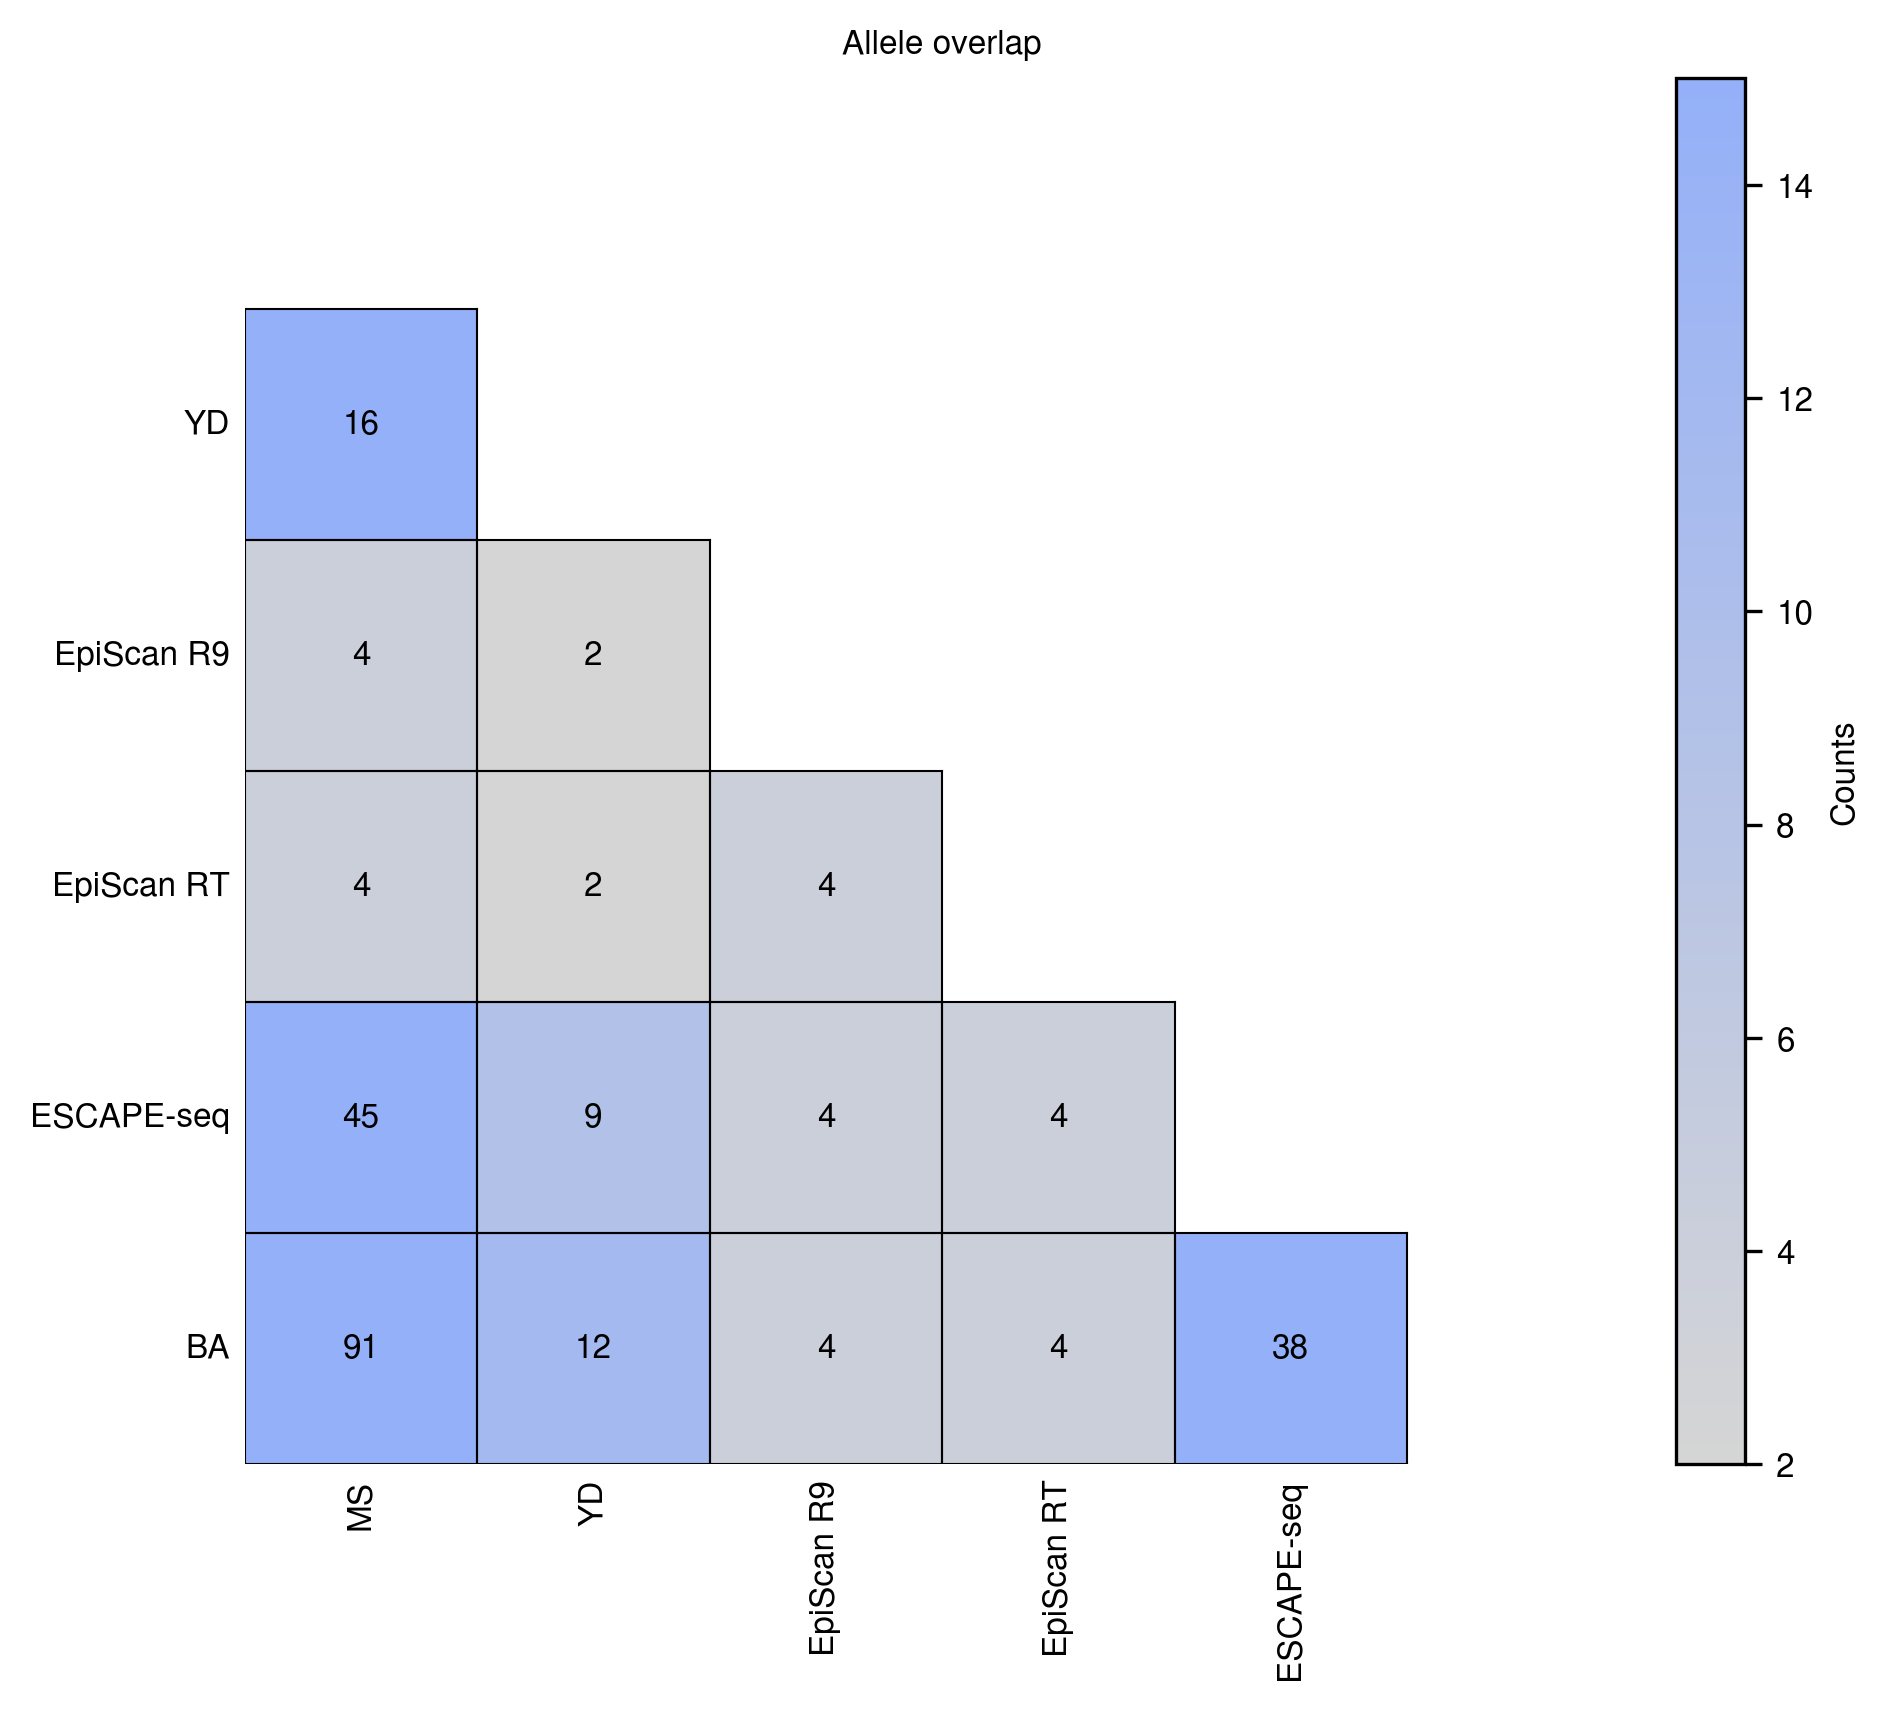

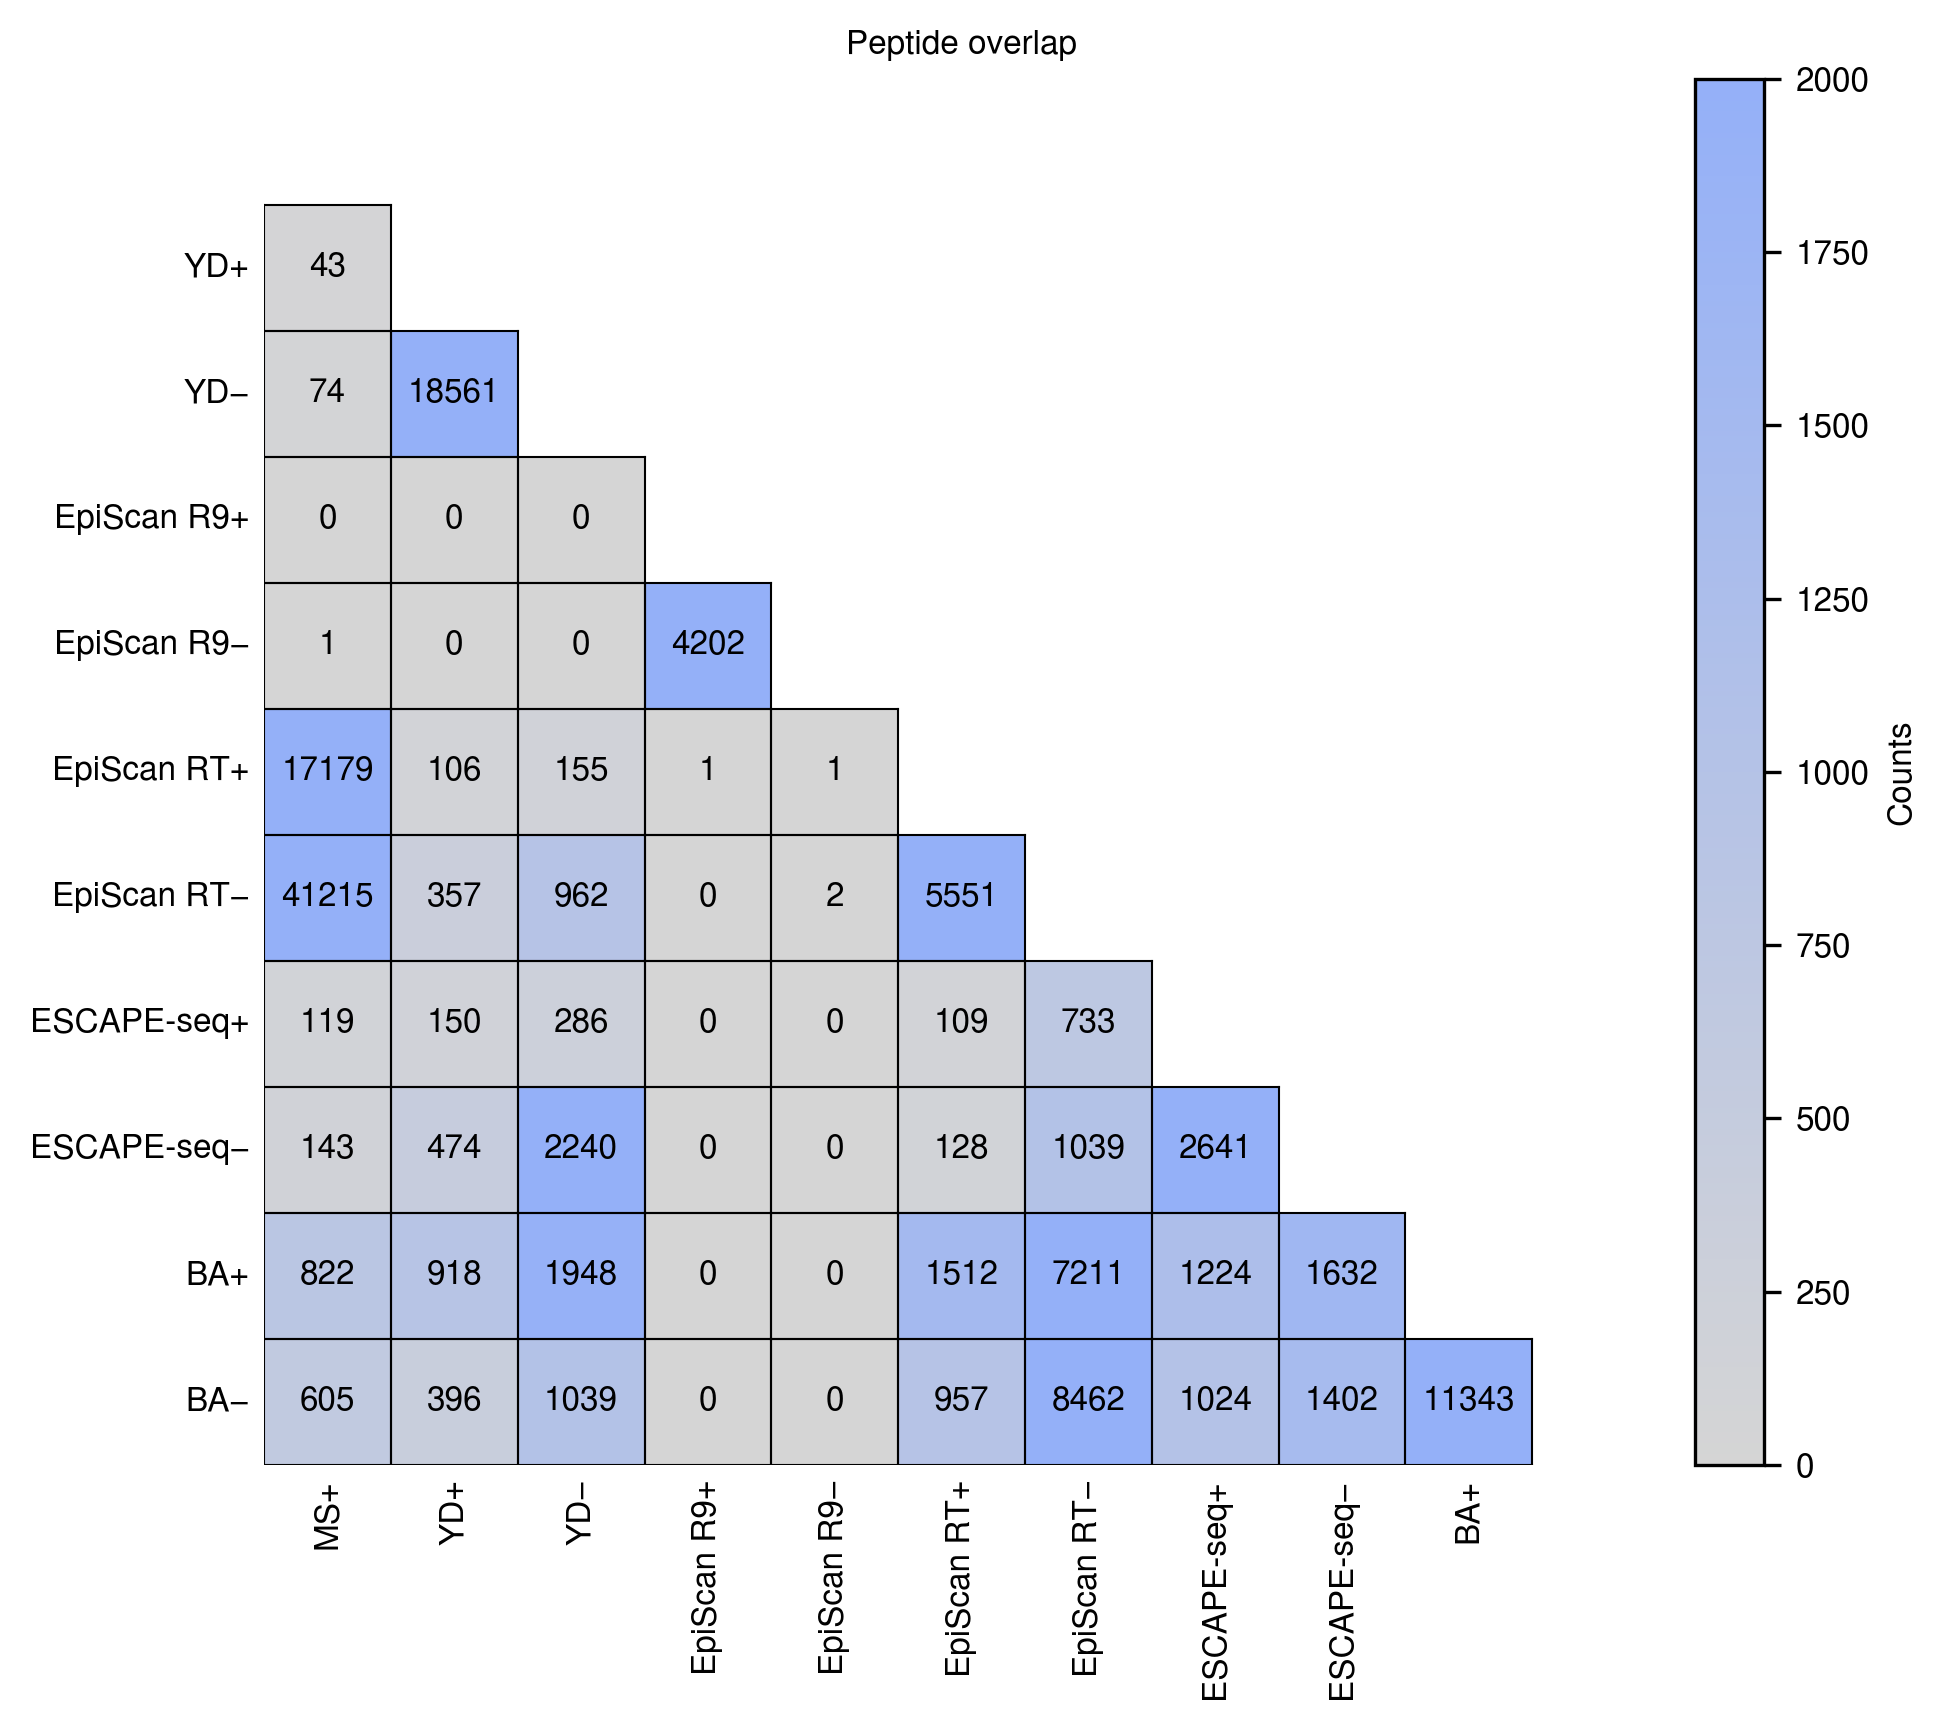

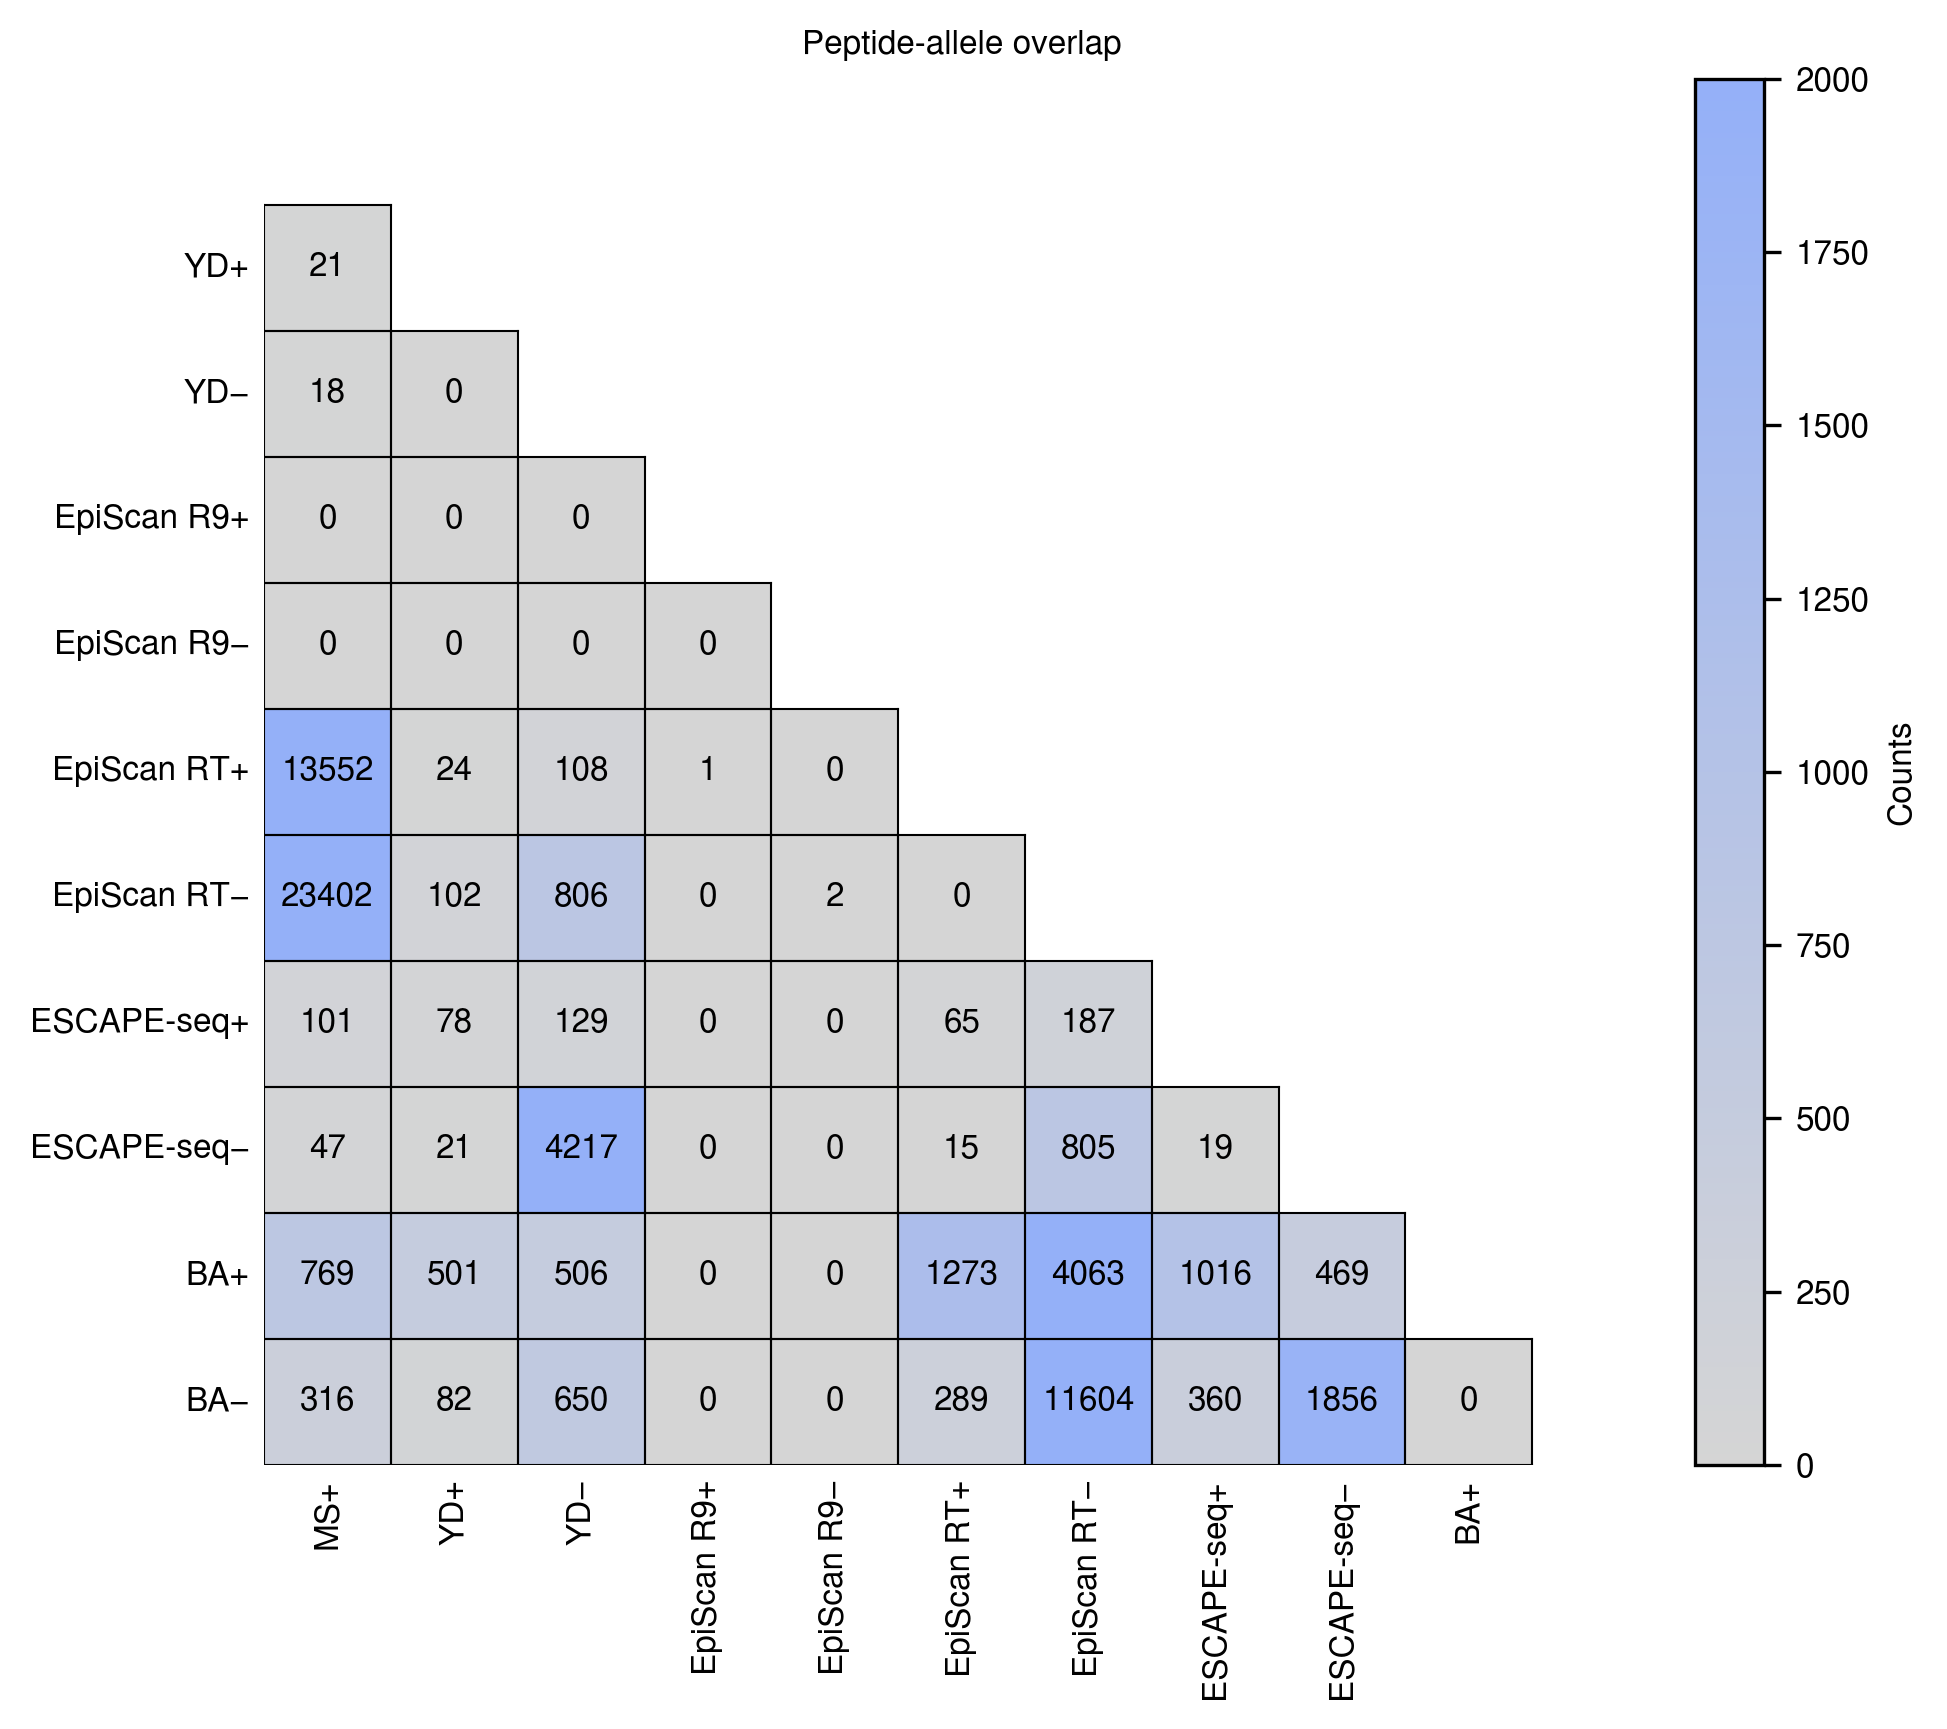

In [ ]:
# correlation across all models heatmap

# for allele
col_label_map = {m: m for m in dataset_allele_overlap_df.columns.tolist()}

_=plot_heatmap(
    df=dataset_allele_overlap_df,
    title="Allele overlap",
    title_fontsize=8,
    lower_triangle_only=True,
    exclude_diagonal=True,
    cmap=None,
    color_list=["#d5d5d5", "#94B0F8"],
    # vmin=0.0,
    vmax=15,
    x_col_labels=col_label_map,
    y_col_labels=col_label_map,
    xtick_rotation=90,
    annot=True,
    annot_fontsize=8,
    annot_decimals=0,
    cell_outline_color='black',
    cell_outline_width=0.5,
    cbar_label='Counts',
    figsize=(6, 6),
    dpi=300,
    default_font='Nimbus Sans',
    xtick_labelsize=8,
    ytick_labelsize=8,
    cbar_label_fontsize=8,
    cbar_labelsize=8,
    save_path=None,
    # save_path=f"{central_figure_dir}/suppfig1_a_allele_overlap_between_datasets_prefiltering", 
)

# for peptide
col_label_map = {m: m for m in dataset_seq_overlap_df.columns.tolist()}

_=plot_heatmap(
    df=dataset_seq_overlap_df,
    title="Peptide overlap",
    title_fontsize=8,
    lower_triangle_only=True,
    exclude_diagonal=True,
    cmap=None,
    color_list=["#d5d5d5", "#94B0F8"],
    # vmin=0.0,
    vmax=2000,
    x_col_labels=col_label_map,
    y_col_labels=col_label_map,
    xtick_rotation=90,
    annot=True,
    annot_fontsize=8,
    annot_decimals=0,
    cell_outline_color='black',
    cell_outline_width=0.5,
    cbar_label='Counts',
    figsize=(6, 6),
    dpi=300,
    default_font='Nimbus Sans',
    xtick_labelsize=8,
    ytick_labelsize=8,
    cbar_label_fontsize=8,
    cbar_labelsize=8,
    save_path=None,
    # save_path=f"{central_figure_dir}/suppfig1_b_peptide_overlap_between_datasets_prefiltering", 

)

# for peptide-allele pairs
col_label_map = {m: m for m in dataset_seq_allele_overlap_df.columns.tolist()}

_=plot_heatmap(
    df=dataset_seq_allele_overlap_df,
    title="Peptide-allele overlap",
    title_fontsize=8,
    lower_triangle_only=True,
    exclude_diagonal=True,
    cmap=None,
    color_list=["#d5d5d5", "#94B0F8"],
    # vmin=0.0,
    vmax=2000,
    x_col_labels=col_label_map,
    y_col_labels=col_label_map,
    xtick_rotation=90,
    annot=True,
    annot_fontsize=8,
    annot_decimals=0,
    cell_outline_color='black',
    cell_outline_width=0.5,
    cbar_label='Counts',
    figsize=(6, 6),
    dpi=300,
    default_font='Nimbus Sans',
    xtick_labelsize=8,
    ytick_labelsize=8,
    cbar_label_fontsize=8,
    cbar_labelsize=8,
    save_path=None,
    # save_path=f"{central_figure_dir}/suppfig1_c_peptide_allele_overlap_between_datasets_prefiltering", 

)

In [ ]:
"""
Save dataframes associated with figures.
"""
save_dfs=False
# save_dfs=True

if save_dfs:
    dataset_allele_overlap_df.to_csv(f"{associated_data_dir}/suppfig1_a_dataset_allele_overlap_df.csv")
    dataset_seq_overlap_df.to_csv(f"{associated_data_dir}/suppfig1_b_dataset_seq_overlap_df.csv")
    dataset_seq_allele_overlap_df.to_csv(f"{associated_data_dir}/suppfig1_c_dataset_seq_allele_overlap_df.csv")

### Supplementary Figure 2: Additional benchmarking on MS test data

 - Associated with analyses in Fig. 2d.

In [ ]:
# get ms set with external model scores
datasets_dir = DATA_DIR / "Training_Datasets" / "Processed" / "MS_Train_Test_Sets"
ms_test_data_with_benchmarking_model_scores=pd.read_csv(f"{datasets_dir}/ms_test_data_with_benchmarking_model_scores.csv", index_col=0)

In [ ]:
%%time
# get ms ap per allele (exclude C0301 as it is not a valid allele for some models)
score_cols=["mhcprime", "mhc_pred_0", "ms_log_odds", "score", "presentation_score", "EL_score", "BA_score", "munis", "transphla", "bigmhc", "deepattentionpan", "Pathogen_score_nmp42", "Neo_score_nmp42", "capsnetmhc_anthem", "capsnetmhc_iedb"]

# auc
ms_allele_auc_matrix = compute_metric_matrix_optimized(df=ms_test_data_with_benchmarking_model_scores.query("allele != 'C0301'"),score_cols=score_cols, method="auc", label_col="label", allele_col="allele", disable_tqdm=False)

# auc0.1
ms_allele_auc01_matrix = compute_metric_matrix_optimized(df=ms_test_data_with_benchmarking_model_scores.query("allele != 'C0301'"),score_cols=score_cols, method="auc01", label_col="label", allele_col="allele", auc01_max_fpr=0.1, auc01_normalized=True, disable_tqdm=False)

# ppvn
ms_allele_ppvn_matrix = compute_metric_matrix_optimized(df=ms_test_data_with_benchmarking_model_scores.query("allele != 'C0301'"),score_cols=score_cols, method="ppvn", label_col="label", allele_col="allele", disable_tqdm=False)

100%|██████████| 141/141 [00:04<00:00, 32.22it/s]

CPU times: user 32.2 s, sys: 537 ms, total: 32.7 s
Wall time: 32.6 s


In [ ]:
# p-values
ms_allele_auc_matrix_pval_df=compute_pairwise_pvalues_general(ms_allele_auc_matrix[score_cols])
display(ms_allele_auc_matrix_pval_df)
display(pval_to_stars(ms_allele_auc_matrix_pval_df))

,mhcprime,mhc_pred_0,ms_log_odds,score,presentation_score,EL_score,BA_score,munis,transphla,bigmhc,deepattentionpan,Pathogen_score_nmp42,Neo_score_nmp42,capsnetmhc_anthem,capsnetmhc_iedb
mhcprime,1.000000e+00,7.316906e-13,1.875366e-17,1.317357e-21,1.054961e-23,4.201451e-23,2.701345e-24,1.590688e-01,1.017529e-24,1.533566e-16,7.709249e-25,7.875804e-25,1.249068e-23,3.380042e-22,7.709249e-25
mhc_pred_0,7.316906e-13,1.000000e+00,2.305973e-01,1.331567e-13,2.661397e-14,9.288425e-17,2.756528e-18,1.039747e-09,1.053693e-19,2.195842e-01,2.051802e-24,1.768853e-24,1.011818e-15,2.262962e-06,2.140581e-24
ms_log_odds,1.875366e-17,2.305973e-01,1.000000e+00,1.385876e-20,1.046185e-17,1.305169e-22,2.477525e-23,4.512167e-13,3.821728e-23,2.877867e-01,6.927405e-25,6.927405e-25,1.881092e-22,1.096546e-12,6.927405e-25
score,1.317357e-21,1.331567e-13,1.385876e-20,1.000000e+00,1.277078e-05,8.559217e-03,3.420269e-08,2.039452e-20,7.222170e-02,3.513402e-09,9.544613e-25,2.887504e-23,2.354354e-01,5.192024e-08,1.624899e-24
presentation_score,1.054961e-23,2.661397e-14,1.046185e-17,1.277078e-05,1.000000e+00,1.505597e-11,1.163174e-15,1.023418e-22,1.761306e-08,3.979787e-09,1.370909e-24,2.051802e-24,5.227799e-09,3.120485e-05,1.430454e-24
EL_score,4.201451e-23,9.288425e-17,1.305169e-22,8.559217e-03,1.505597e-11,1.000000e+00,1.199201e-12,3.901249e-23,1.523205e-01,9.876465e-13,7.709249e-25,3.380042e-22,1.949522e-02,4.212997e-15,1.370909e-24
BA_score,2.701345e-24,2.756528e-18,2.477525e-23,3.420269e-08,1.163174e-15,1.199201e-12,1.000000e+00,1.342064e-24,8.112275e-02,2.405870e-15,8.397161e-25,2.155580e-19,1.012968e-16,5.022883e-20,9.960605e-25
munis,1.590688e-01,1.039747e-09,4.512167e-13,2.039452e-20,1.023418e-22,3.901249e-23,1.342064e-24,1.000000e+00,1.461181e-24,4.746594e-18,7.230239e-25,7.077217e-25,1.671135e-23,8.333407e-22,7.230239e-25
transphla,1.017529e-24,1.053693e-19,3.821728e-23,7.222170e-02,1.761306e-08,1.523205e-01,8.112275e-02,1.461181e-24,1.000000e+00,3.022802e-14,1.014059e-23,1.890165e-19,2.891570e-02,5.366455e-22,5.647828e-23
bigmhc,1.533566e-16,2.195842e-01,2.877867e-01,3.513402e-09,3.979787e-09,9.876465e-13,2.405870e-15,4.746594e-18,3.022802e-14,1.000000e+00,8.229216e-24,1.017211e-21,4.778519e-12,2.990080e-03,4.575255e-24


,mhcprime,mhc_pred_0,ms_log_odds,score,presentation_score,EL_score,BA_score,munis,transphla,bigmhc,deepattentionpan,Pathogen_score_nmp42,Neo_score_nmp42,capsnetmhc_anthem,capsnetmhc_iedb
mhcprime,ns,****,****,****,****,****,****,ns,****,****,****,****,****,****,****
mhc_pred_0,****,ns,ns,****,****,****,****,****,****,ns,****,****,****,****,****
ms_log_odds,****,ns,ns,****,****,****,****,****,****,ns,****,****,****,****,****
score,****,****,****,ns,****,**,****,****,ns,****,****,****,ns,****,****
presentation_score,****,****,****,****,ns,****,****,****,****,****,****,****,****,****,****
EL_score,****,****,****,**,****,ns,****,****,ns,****,****,****,*,****,****
BA_score,****,****,****,****,****,****,ns,****,ns,****,****,****,****,****,****
munis,ns,****,****,****,****,****,****,ns,****,****,****,****,****,****,****
transphla,****,****,****,ns,****,ns,ns,****,ns,****,****,****,*,****,****
bigmhc,****,ns,ns,****,****,****,****,****,****,ns,****,****,****,**,****


In [ ]:
# p-values
ms_allele_auc01_matrix_pval_df=compute_pairwise_pvalues_general(ms_allele_auc01_matrix[score_cols])
display(ms_allele_auc01_matrix_pval_df)
display(pval_to_stars(ms_allele_auc01_matrix_pval_df))

,mhcprime,mhc_pred_0,ms_log_odds,score,presentation_score,EL_score,BA_score,munis,transphla,bigmhc,deepattentionpan,Pathogen_score_nmp42,Neo_score_nmp42,capsnetmhc_anthem,capsnetmhc_iedb
mhcprime,1.000000e+00,1.622659e-10,3.263079e-21,5.533124e-23,1.281705e-24,3.504855e-24,9.960605e-25,1.877749e-13,6.927405e-25,3.902861e-21,7.077217e-25,6.927405e-25,1.259088e-24,2.051802e-24,6.927405e-25
mhc_pred_0,1.622659e-10,1.000000e+00,1.066771e-10,1.595739e-17,4.059115e-21,5.475132e-22,1.853860e-23,5.444486e-01,6.138545e-24,1.289880e-10,8.045924e-25,6.927405e-25,1.676347e-22,1.504771e-22,7.875804e-25
ms_log_odds,3.263079e-21,1.066771e-10,1.000000e+00,3.835063e-14,7.230939e-19,1.778510e-23,2.280931e-24,1.289880e-10,1.659761e-24,2.015923e-01,6.927405e-25,6.927405e-25,9.135529e-24,8.204549e-21,6.927405e-25
score,5.533124e-23,1.595739e-17,3.835063e-14,1.000000e+00,1.524041e-01,7.002919e-08,2.340103e-18,1.048684e-16,3.820988e-18,5.343068e-03,7.386538e-25,8.397161e-25,5.163607e-09,1.866051e-03,7.230239e-25
presentation_score,1.281705e-24,4.059115e-21,7.230939e-19,1.524041e-01,1.000000e+00,4.933606e-07,1.888052e-20,6.625417e-20,5.663011e-21,5.560709e-05,1.039455e-24,2.644861e-24,6.781564e-10,2.967934e-02,9.960605e-25
EL_score,3.504855e-24,5.475132e-22,1.778510e-23,7.002919e-08,4.933606e-07,1.000000e+00,3.821728e-23,1.169269e-21,5.483472e-18,1.263402e-07,7.386538e-25,5.886425e-24,3.710907e-01,1.049129e-02,7.230239e-25
BA_score,9.960605e-25,1.853860e-23,2.280931e-24,2.340103e-18,1.888052e-20,3.821728e-23,1.000000e+00,1.932371e-23,5.292396e-03,2.813444e-13,8.045924e-25,1.474507e-22,6.005004e-21,4.941859e-13,7.230239e-25
munis,1.877749e-13,5.444486e-01,1.289880e-10,1.048684e-16,6.625417e-20,1.169269e-21,1.932371e-23,1.000000e+00,1.149208e-23,9.729824e-13,7.077217e-25,3.002190e-24,1.108982e-22,3.590571e-22,7.077217e-25
transphla,6.927405e-25,6.138545e-24,1.659761e-24,3.820988e-18,5.663011e-21,5.483472e-18,5.292396e-03,1.149208e-23,1.000000e+00,1.728406e-14,6.519405e-23,1.521167e-17,1.303603e-18,1.747774e-20,1.203124e-22
bigmhc,3.902861e-21,1.289880e-10,2.015923e-01,5.343068e-03,5.560709e-05,1.263402e-07,2.813444e-13,9.729824e-13,1.728406e-14,1.000000e+00,1.014059e-23,3.022680e-21,1.975639e-08,5.261343e-07,1.249068e-23


,mhcprime,mhc_pred_0,ms_log_odds,score,presentation_score,EL_score,BA_score,munis,transphla,bigmhc,deepattentionpan,Pathogen_score_nmp42,Neo_score_nmp42,capsnetmhc_anthem,capsnetmhc_iedb
mhcprime,ns,****,****,****,****,****,****,****,****,****,****,****,****,****,****
mhc_pred_0,****,ns,****,****,****,****,****,ns,****,****,****,****,****,****,****
ms_log_odds,****,****,ns,****,****,****,****,****,****,ns,****,****,****,****,****
score,****,****,****,ns,ns,****,****,****,****,**,****,****,****,**,****
presentation_score,****,****,****,ns,ns,****,****,****,****,****,****,****,****,*,****
EL_score,****,****,****,****,****,ns,****,****,****,****,****,****,ns,*,****
BA_score,****,****,****,****,****,****,ns,****,**,****,****,****,****,****,****
munis,****,ns,****,****,****,****,****,ns,****,****,****,****,****,****,****
transphla,****,****,****,****,****,****,**,****,ns,****,****,****,****,****,****
bigmhc,****,****,ns,**,****,****,****,****,****,ns,****,****,****,****,****


In [ ]:
# p-values
ms_allele_ppvn_matrix_pval_df=compute_pairwise_pvalues_general(ms_allele_ppvn_matrix[score_cols])
display(ms_allele_ppvn_matrix_pval_df)
display(pval_to_stars(ms_allele_ppvn_matrix_pval_df))

,mhcprime,mhc_pred_0,ms_log_odds,score,presentation_score,EL_score,BA_score,munis,transphla,bigmhc,deepattentionpan,Pathogen_score_nmp42,Neo_score_nmp42,capsnetmhc_anthem,capsnetmhc_iedb
mhcprime,1.000000e+00,3.633990e-03,1.595813e-16,6.738623e-18,4.315788e-23,5.236125e-23,2.682729e-24,3.827018e-22,3.877749e-13,1.871225e-11,6.924656e-25,6.925048e-25,7.341042e-24,1.133564e-23,6.925245e-25
mhc_pred_0,3.633990e-03,1.000000e+00,1.359489e-14,3.552443e-17,3.679665e-21,7.679708e-22,7.888760e-23,6.548386e-18,9.301835e-14,4.717642e-14,6.926030e-25,7.076615e-25,1.524401e-22,1.887461e-22,7.075813e-25
ms_log_odds,1.595813e-16,1.359489e-14,1.000000e+00,2.354031e-05,1.487543e-17,7.057663e-23,6.639413e-24,3.723402e-02,5.080245e-02,6.878942e-02,6.923281e-25,6.926423e-25,1.246113e-22,6.787345e-23,6.923085e-25
score,6.738623e-18,3.552443e-17,2.354031e-05,1.000000e+00,4.957629e-09,7.974804e-15,3.783832e-21,1.215332e-01,7.439892e-01,7.347283e-01,6.926030e-25,7.386329e-25,8.555817e-16,1.872213e-15,7.227576e-25
presentation_score,4.315788e-23,3.679665e-21,1.487543e-17,4.957629e-09,1.000000e+00,5.140165e-06,2.063762e-19,1.130630e-12,1.666795e-06,3.805666e-04,7.229010e-25,1.309188e-24,1.758815e-08,1.261209e-09,7.076214e-25
EL_score,5.236125e-23,7.679708e-22,7.057663e-23,7.974804e-15,5.140165e-06,1.000000e+00,1.270348e-21,6.349821e-17,2.227199e-13,4.652426e-07,6.925048e-25,1.815556e-23,9.604316e-02,2.014400e-02,6.925245e-25
BA_score,2.682729e-24,7.888760e-23,6.639413e-24,3.783832e-21,2.063762e-19,1.270348e-21,1.000000e+00,2.216435e-21,1.293093e-22,1.693823e-14,1.017385e-24,1.183004e-20,2.056999e-19,1.998064e-10,1.915172e-24
munis,3.827018e-22,6.548386e-18,3.723402e-02,1.215332e-01,1.130630e-12,6.349821e-17,2.216435e-21,1.000000e+00,3.737704e-01,4.027178e-01,6.924459e-25,4.721301e-24,1.589483e-19,9.106356e-20,7.074810e-25
transphla,3.877749e-13,9.301835e-14,5.080245e-02,7.439892e-01,1.666795e-06,2.227199e-13,1.293093e-22,3.737704e-01,1.000000e+00,3.858755e-01,1.078955e-24,5.714001e-24,1.371197e-14,1.049257e-17,7.709031e-25
bigmhc,1.871225e-11,4.717642e-14,6.878942e-02,7.347283e-01,3.805666e-04,4.652426e-07,1.693823e-14,4.027178e-01,3.858755e-01,1.000000e+00,1.636484e-23,8.416359e-22,8.648222e-08,8.648988e-09,2.066115e-23


,mhcprime,mhc_pred_0,ms_log_odds,score,presentation_score,EL_score,BA_score,munis,transphla,bigmhc,deepattentionpan,Pathogen_score_nmp42,Neo_score_nmp42,capsnetmhc_anthem,capsnetmhc_iedb
mhcprime,ns,**,****,****,****,****,****,****,****,****,****,****,****,****,****
mhc_pred_0,**,ns,****,****,****,****,****,****,****,****,****,****,****,****,****
ms_log_odds,****,****,ns,****,****,****,****,*,ns,ns,****,****,****,****,****
score,****,****,****,ns,****,****,****,ns,ns,ns,****,****,****,****,****
presentation_score,****,****,****,****,ns,****,****,****,****,***,****,****,****,****,****
EL_score,****,****,****,****,****,ns,****,****,****,****,****,****,ns,*,****
BA_score,****,****,****,****,****,****,ns,****,****,****,****,****,****,****,****
munis,****,****,*,ns,****,****,****,ns,ns,ns,****,****,****,****,****
transphla,****,****,ns,ns,****,****,****,ns,ns,ns,****,****,****,****,****
bigmhc,****,****,ns,ns,***,****,****,ns,ns,ns,****,****,****,****,****


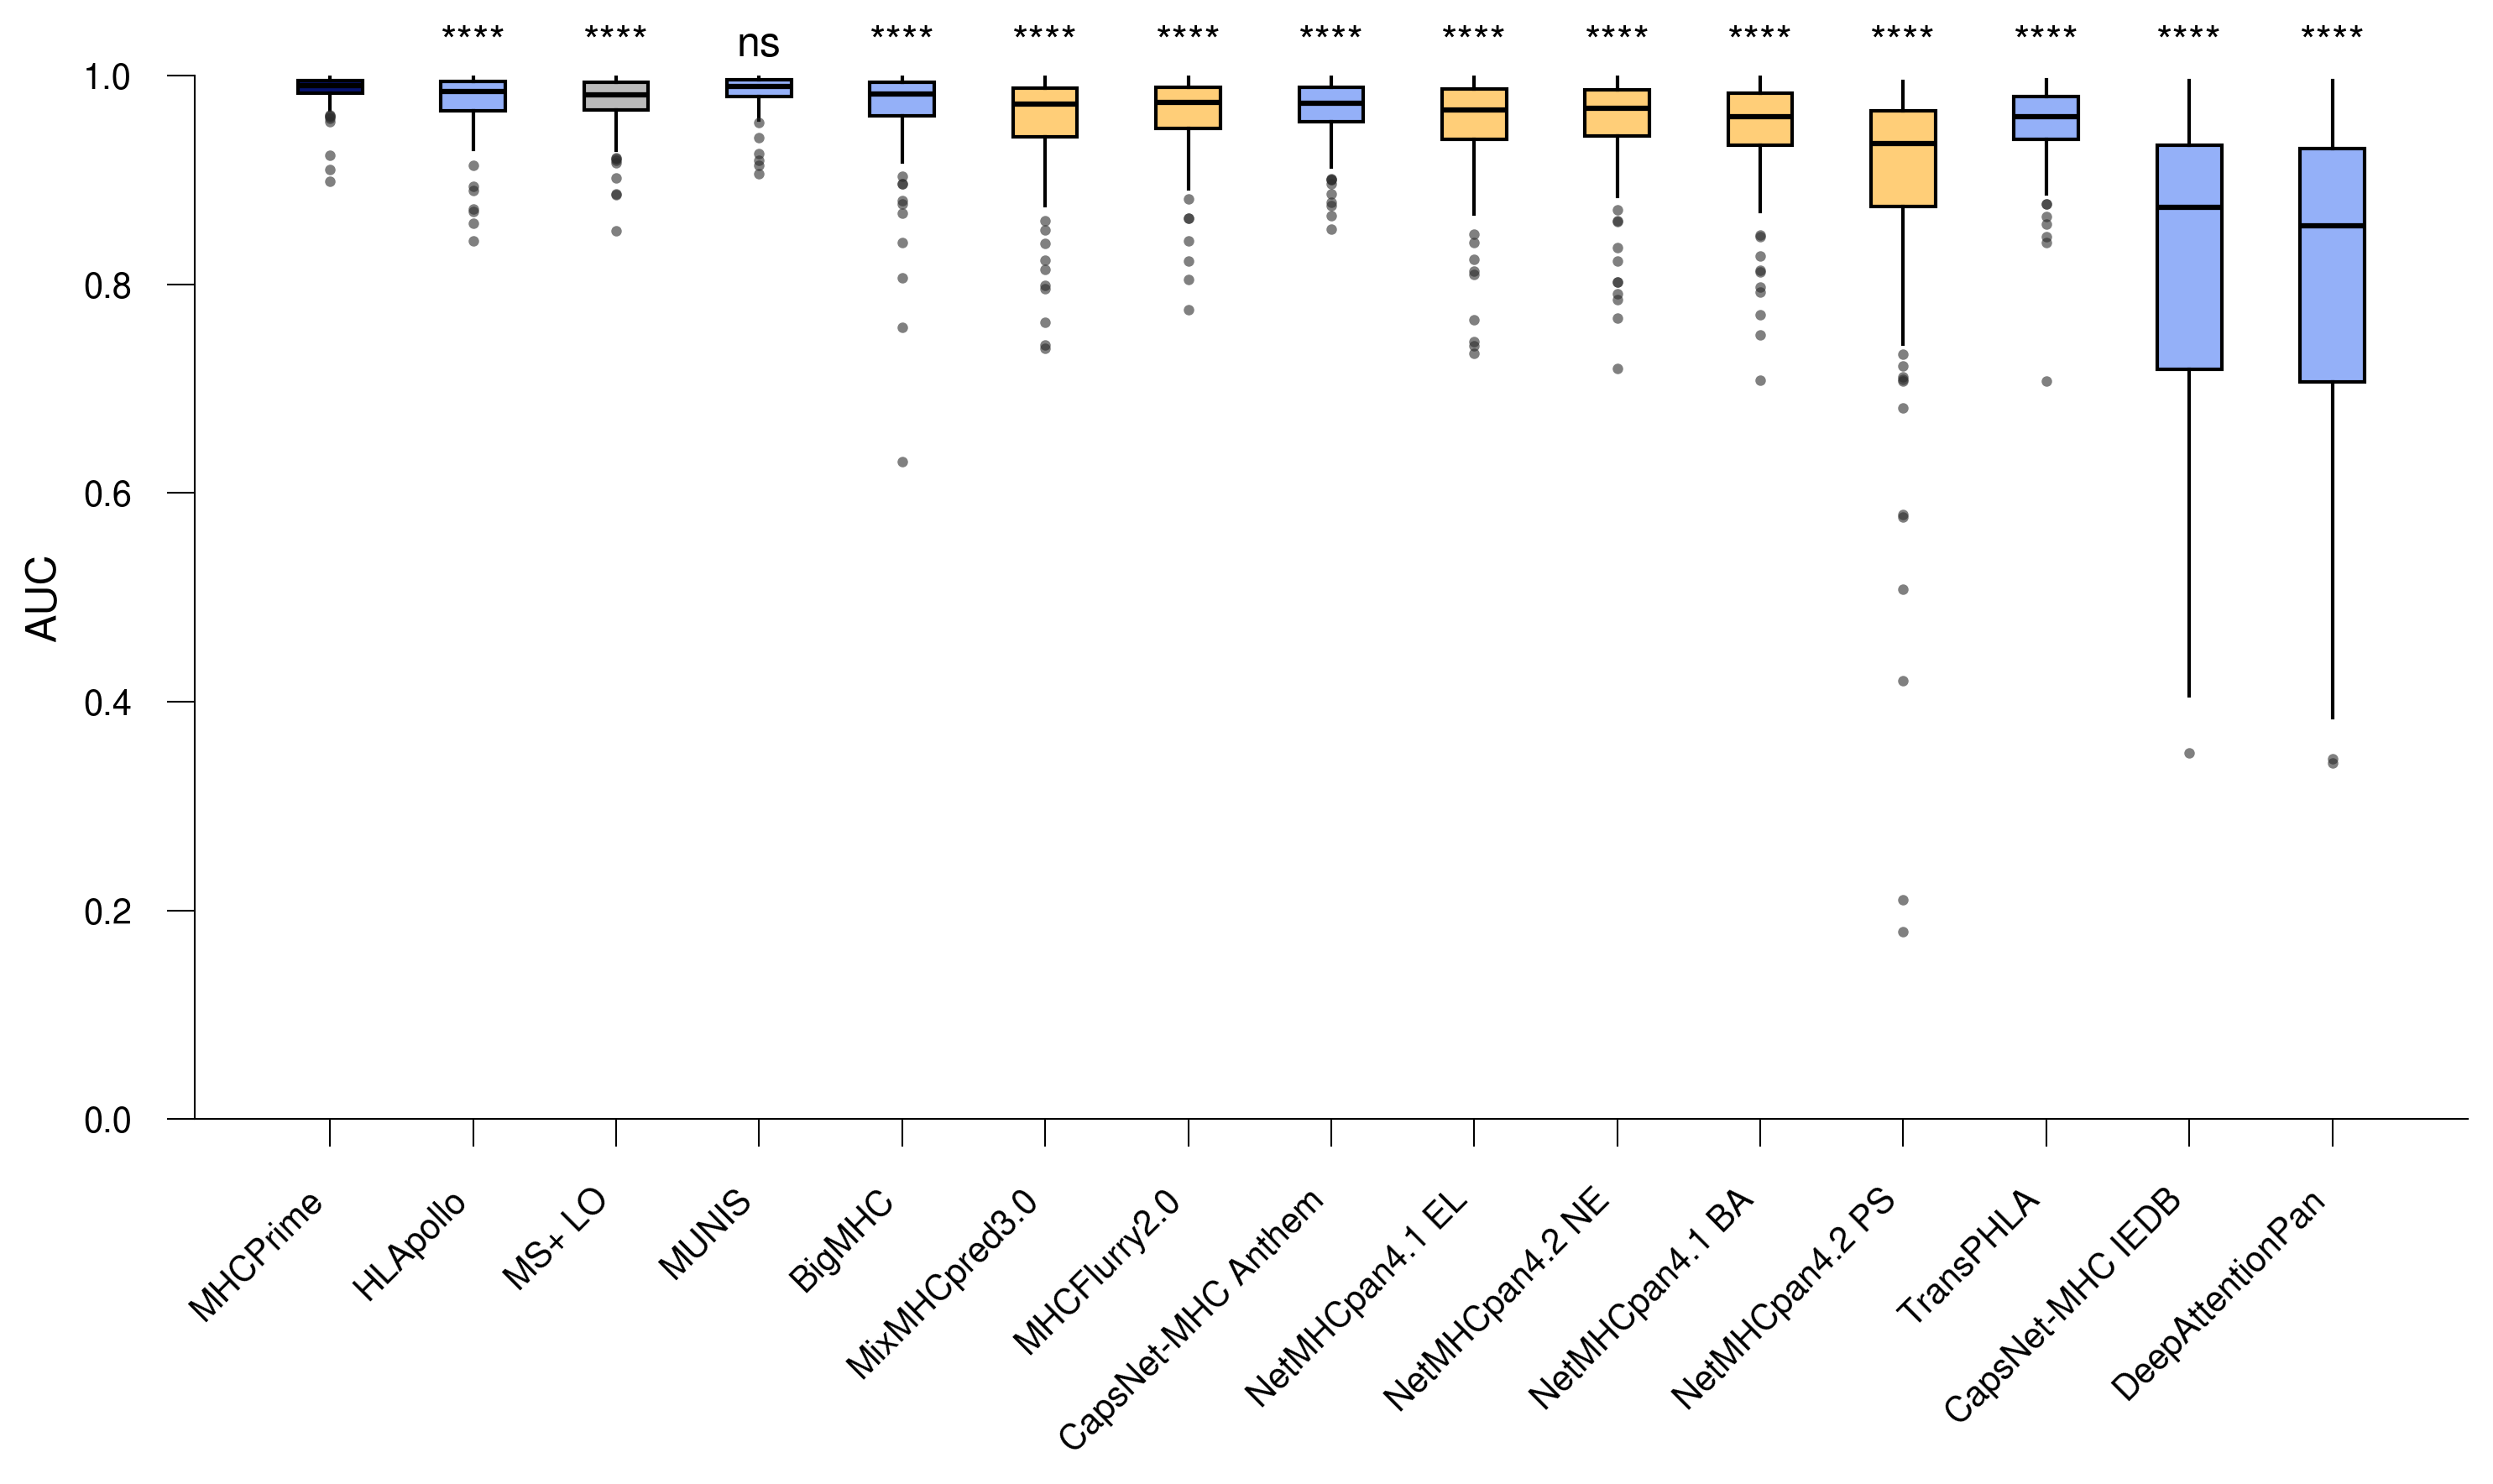

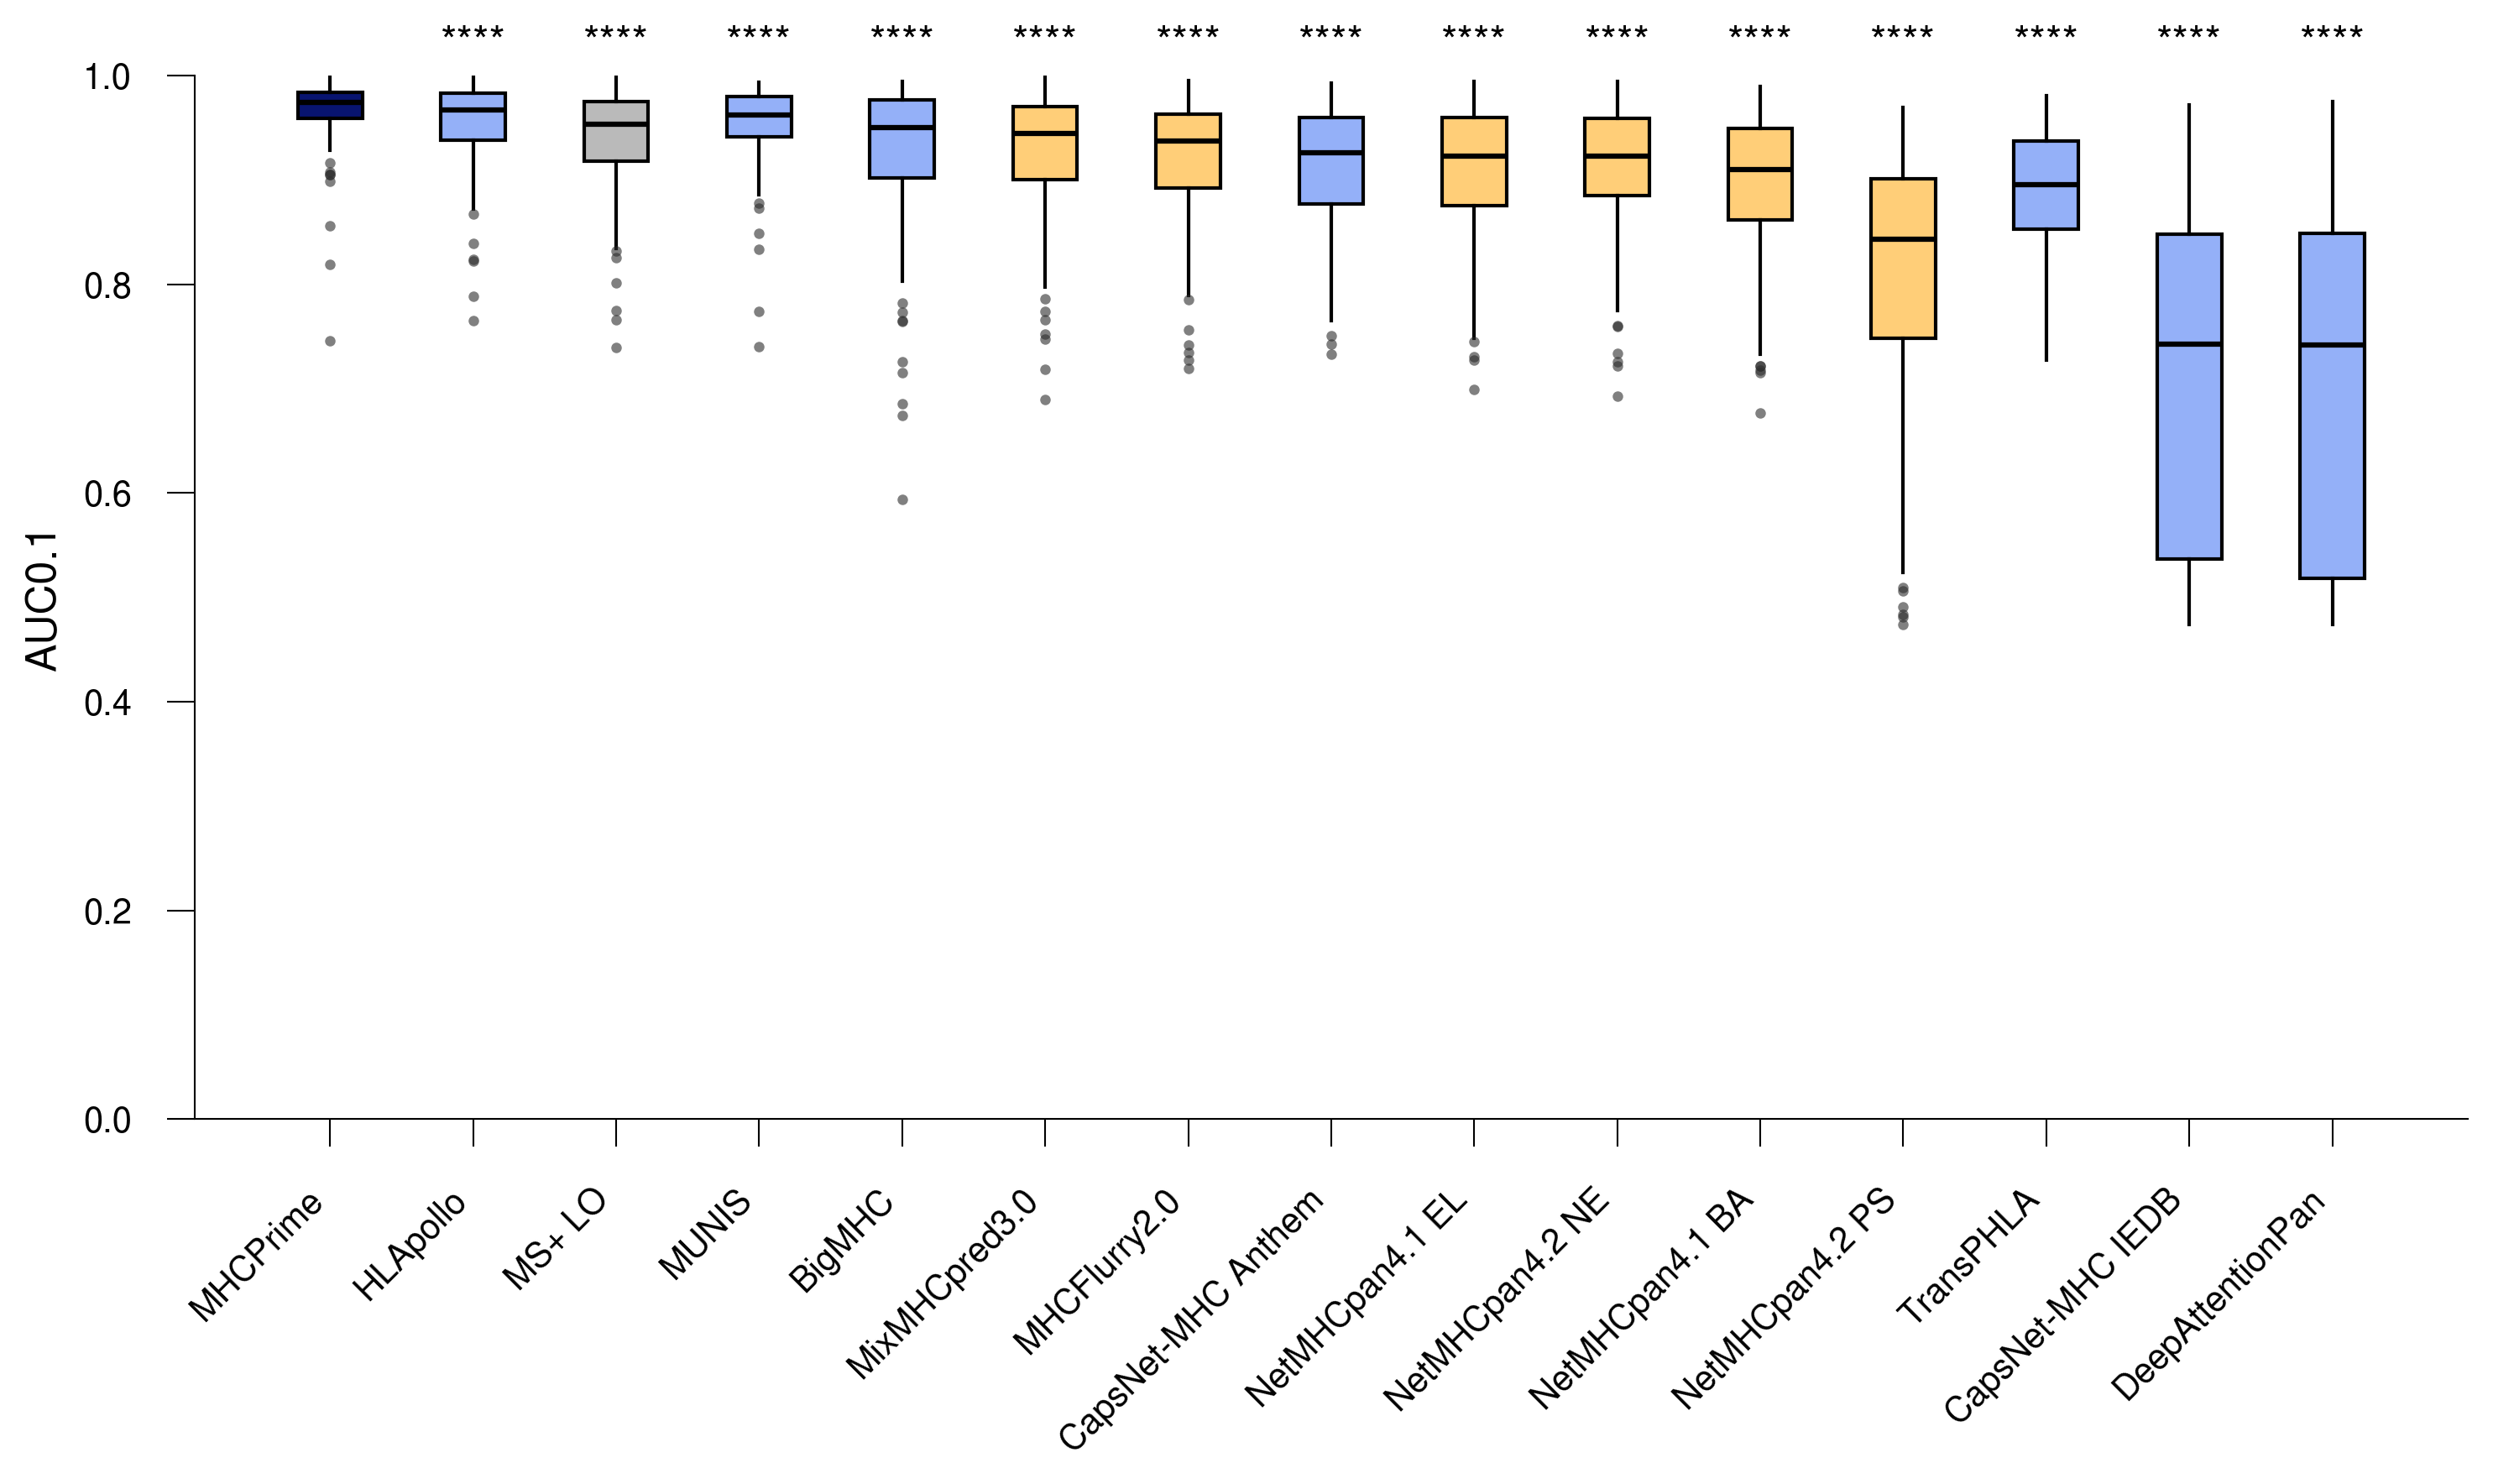

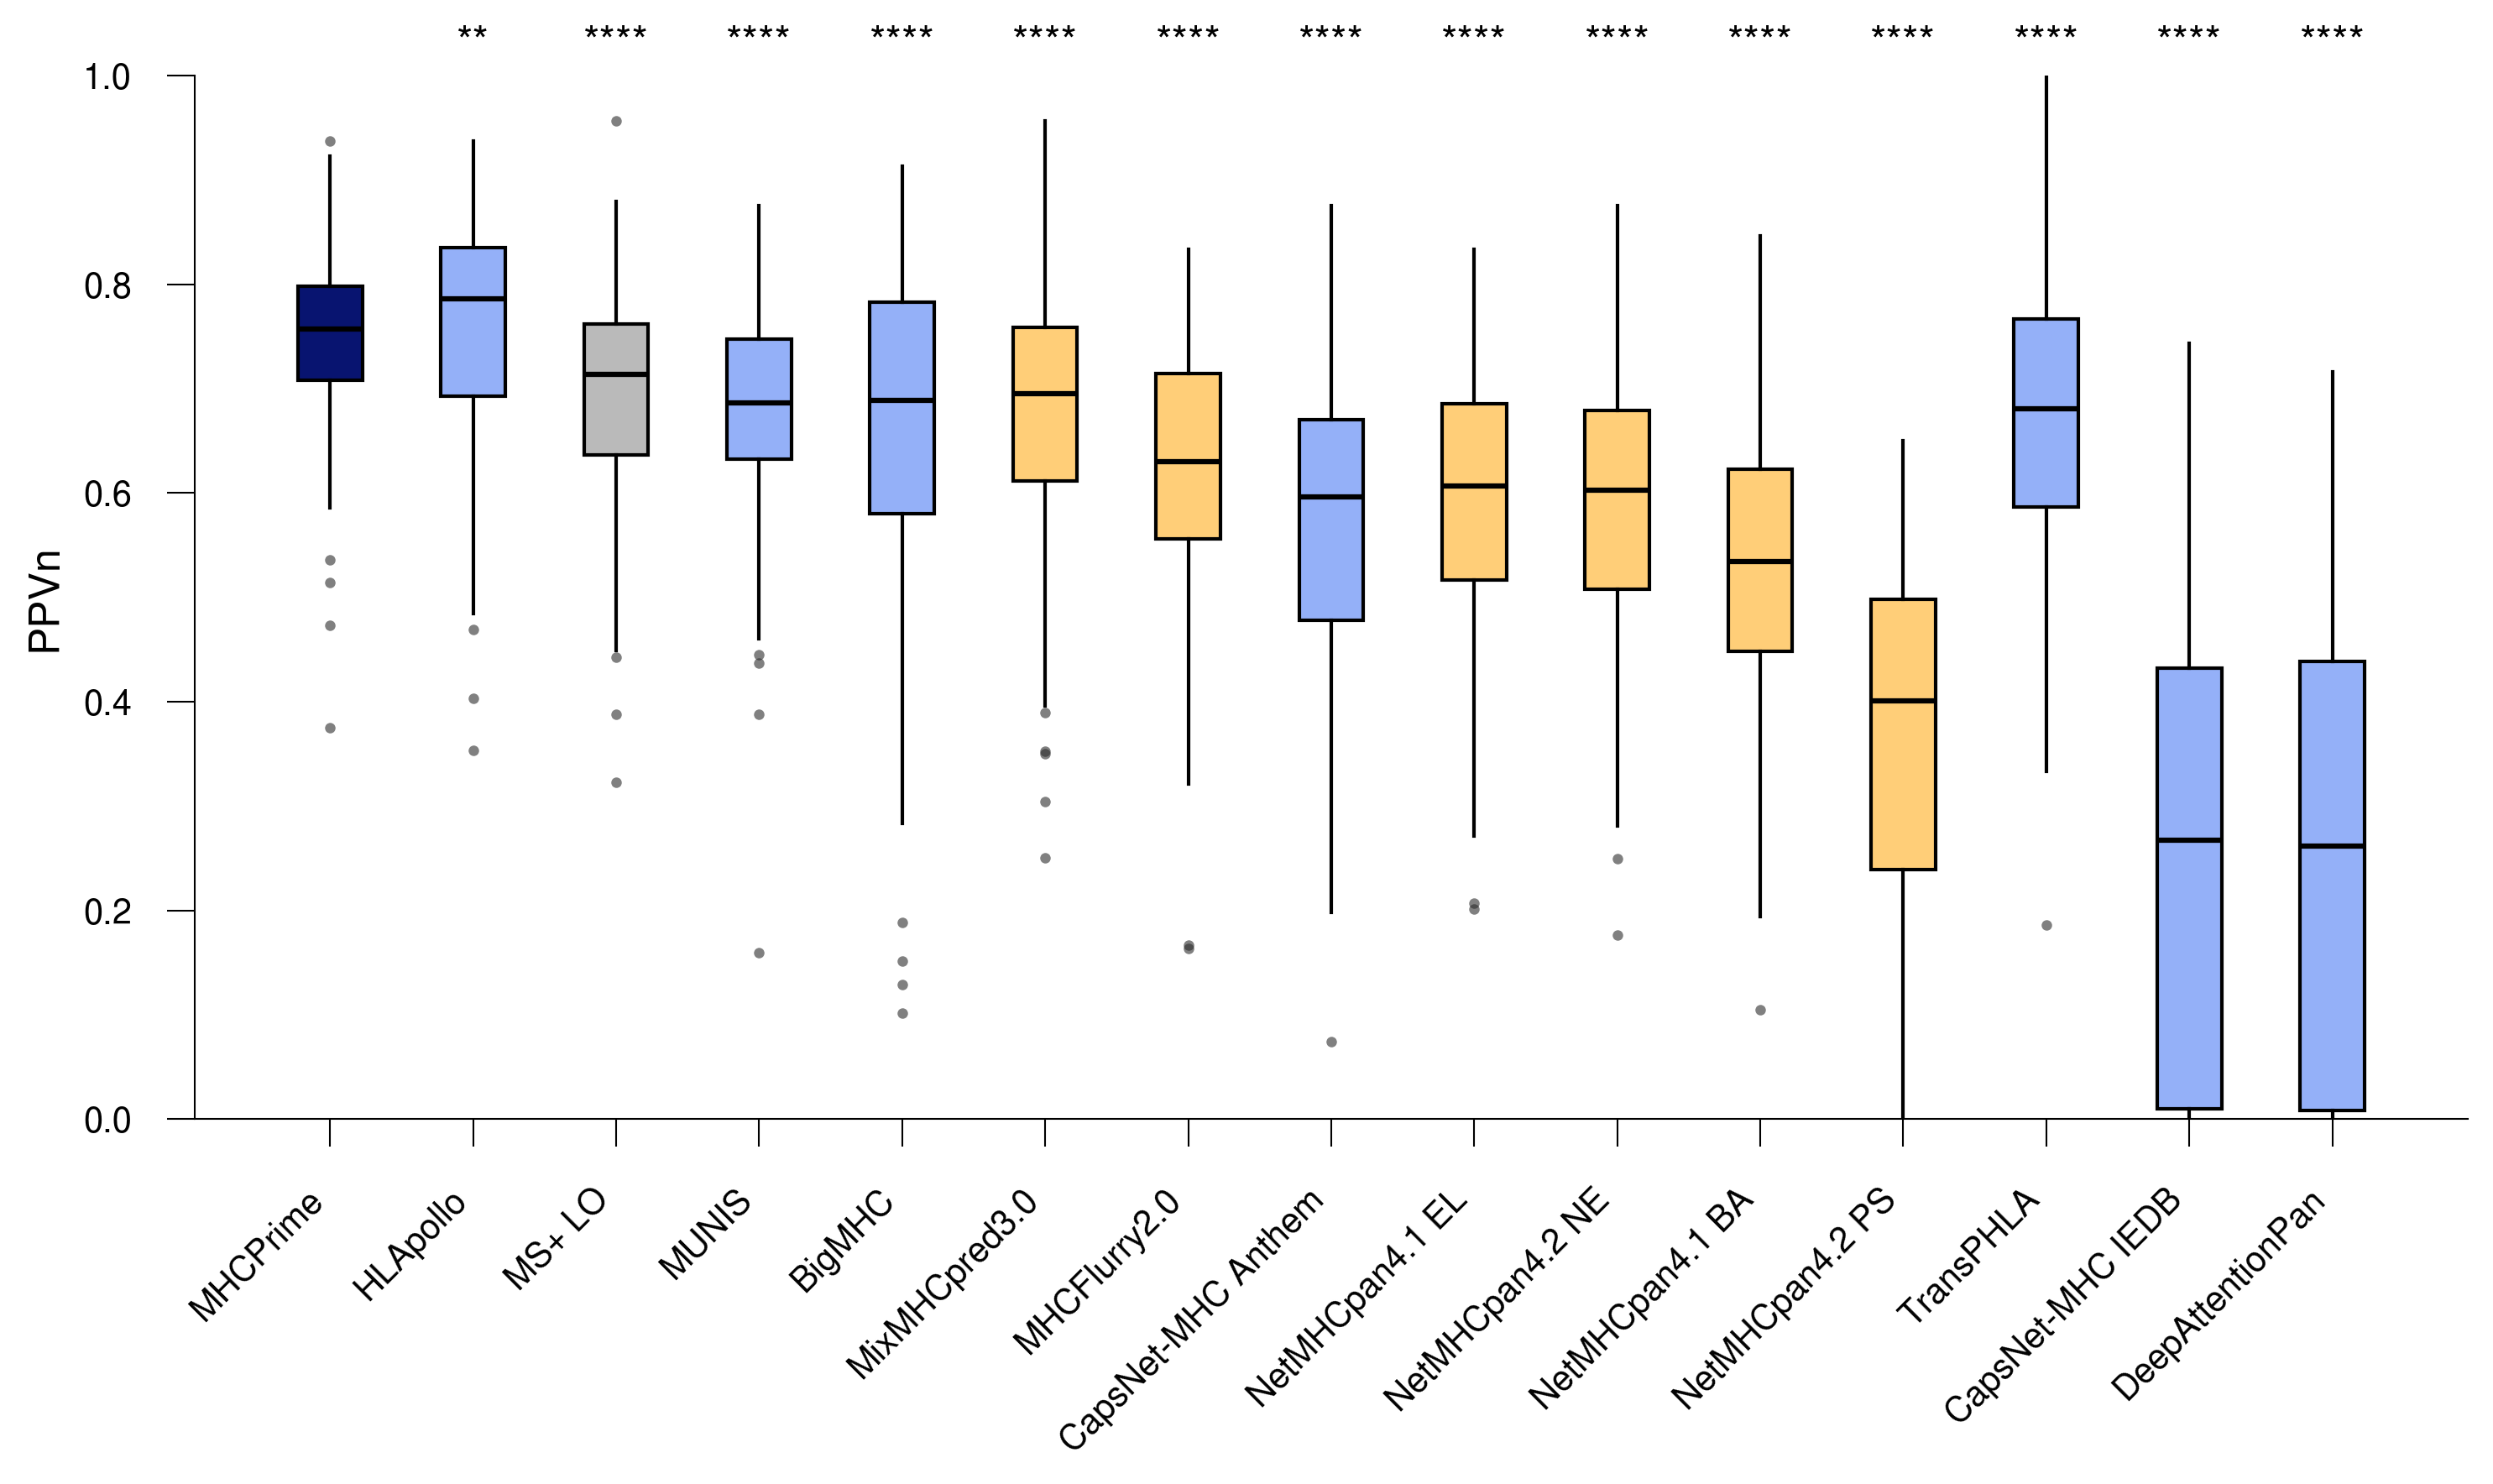

In [ ]:
# ms performance boxplots
def replace_boxplot_df(boxplot_groups, new_df):
    return {
        label: [(new_df, col) for _, col in pairs]
        for label, pairs in boxplot_groups.items()
    }

boxplot_groups={
    "MHCPrime": [(ms_allele_auc_matrix, 'mhcprime')],
    "HLApollo": [(ms_allele_auc_matrix, 'mhc_pred_0')],
    "MS+ LO": [(ms_allele_auc_matrix, 'ms_log_odds')],
    "MUNIS": [(ms_allele_auc_matrix, 'munis')],
    "BigMHC": [(ms_allele_auc_matrix, 'bigmhc')],
    "MixMHCpred3.0": [(ms_allele_auc_matrix, 'score')],
    "MHCFlurry2.0": [(ms_allele_auc_matrix, 'presentation_score')],
    "CapsNet-MHC Anthem": [(ms_allele_auc_matrix, 'capsnetmhc_anthem')],
    "NetMHCpan4.1 EL": [(ms_allele_auc_matrix, 'EL_score')],
    "NetMHCpan4.2 NE": [(ms_allele_auc_matrix, 'Neo_score_nmp42')],
    "NetMHCpan4.1 BA": [(ms_allele_auc_matrix, 'BA_score')],
    "NetMHCpan4.2 PS": [(ms_allele_auc_matrix, 'Pathogen_score_nmp42')],
    "TransPHLA": [(ms_allele_auc_matrix, 'transphla')],
    "CapsNet-MHC IEDB": [(ms_allele_auc_matrix, 'capsnetmhc_iedb')],
    "DeepAttentionPan": [(ms_allele_auc_matrix, 'deepattentionpan')],
}


transformer_based_color="#94B0F8"
nn_based_color="#ffce78"
lo_color="#bababa"
colors={
    "mhcprime": "#081470",
    "mhc_pred_0": transformer_based_color,
    "ms_log_odds": lo_color,
    "presentation_score":nn_based_color, 
    "score":nn_based_color, 
    "EL_score": nn_based_color,
    "BA_score": nn_based_color,
    "munis": transformer_based_color, 
    "transphla": transformer_based_color,
    "bigmhc": transformer_based_color, 
    "deepattentionpan": transformer_based_color,
    "Pathogen_score_nmp42":nn_based_color, 
    "Neo_score_nmp42":nn_based_color, 
    "capsnetmhc_anthem": transformer_based_color,
    "capsnetmhc_iedb": transformer_based_color, 
}

plot_params = {
    'title': '',
    'title_fontsize': 16,
    'title_bold': False,
    'xlabel': '',
    'ylabel': 'AUC',
    'xlabel_fontsize': 12,
    'ylabel_fontsize': 12,
    'figsize': (10, 6),
    'dpi': 300,
    'legend_fontsize': 12,
    'legend_cols': 5,
    'legend_handle_size': 0.9,
    'marker_size': 3,
    'axis_linewidth': 0.5,
    'tick_length': 8.0,
    'xlabel_pad': 5.0,
    'ylabel_pad': 5.0,
    'xtick_labelsize': 10,
    'ytick_labelsize': 10,
    'xtick_rotation': 45

}

plotting_params=dict(
    colors=colors,
    legend=None,
    plot_params=plot_params,
    grid_alpha=0.0,
    default_font='Nimbus Sans',
    box_width=0.1,
    group_spacing=0.1,
    box_spacing=0.05,
    box_outline_color='black',
    box_outline_width=1.0,
    box_flier_marker='o',
    box_flier_size=3,
    box_flier_color="#2B2B2B",
    box_flier_alpha=0.6,
    box_flier_edge_width=0,
    box_median_color='black',
    box_median_width=1.5,
    box_whisker_style='-',
    box_whisker_width=1.0,
    box_notch=False,
    box_patch_alpha=1.0,
    hline_y=None,
    hline_label=None,
    hline_color='gray',
    hline_width=1.0,
    hline_style='--',
    hline_text=None,
    hline_text_position='above',
    hline_text_color=None,
    hline_text_fontsize=10,
    hline_text_offset=0.01,
    hline_text_x_offset=0.05,
    hline_in_legend=True,
    reference_hlines=None,
    legend_mode=None,
    legend_loc='lower center',
    legend_bbox=None,
    legend_ncol=None,
    ylim=(0, 1.0),
    compute_pvalues=False,
    pvalue_test='wilcoxon', 
    cluster_col='louvain_id',
    # sort_by ="median",
    sort_ascending=False, 
    pval_df=None,
    pval_ref_col="mhcprime",
    pval_ref_stars_only=True,
    pval_format='stars',
    pval_fontsize=12,
    pval_color='black',
    pval_star_y=None,
    pval_star_y_frac=1.01,
    pval_star_text_offset=0.0,

)

plot_params["ylabel"]="AUC"
plotting_params["plot_params"]=plot_params
plotting_params["pval_df"]=ms_allele_auc_matrix_pval_df
boxplot_groups=replace_boxplot_df(boxplot_groups, ms_allele_auc_matrix)
_=plot_grouped_boxplots(
    groups=boxplot_groups,
    save_path=None,
    # save_path=f"{central_figure_dir}/suppfig2_a_ms_baseline_allele_auc_performance_boxplots_per_model", 
    **plotting_params
)


plot_params["ylabel"]="AUC0.1"
plotting_params["plot_params"]=plot_params
plotting_params["pval_df"]=ms_allele_auc01_matrix_pval_df
boxplot_groups=replace_boxplot_df(boxplot_groups, ms_allele_auc01_matrix)
_=plot_grouped_boxplots(
    groups=boxplot_groups,
    save_path=None,
    # save_path=f"{central_figure_dir}/suppfig2_b_ms_baseline_allele_auc01_performance_boxplots_per_model", 
    **plotting_params
)


plot_params["ylabel"]="PPVn"
plotting_params["plot_params"]=plot_params
plotting_params["pval_df"]=ms_allele_ppvn_matrix_pval_df
boxplot_groups=replace_boxplot_df(boxplot_groups, ms_allele_ppvn_matrix)
_=plot_grouped_boxplots(
    groups=boxplot_groups,
    save_path=None,
    # save_path=f"{central_figure_dir}/suppfig2_c_ms_baseline_allele_ppvn_performance_boxplots_per_model", 
    **plotting_params
)


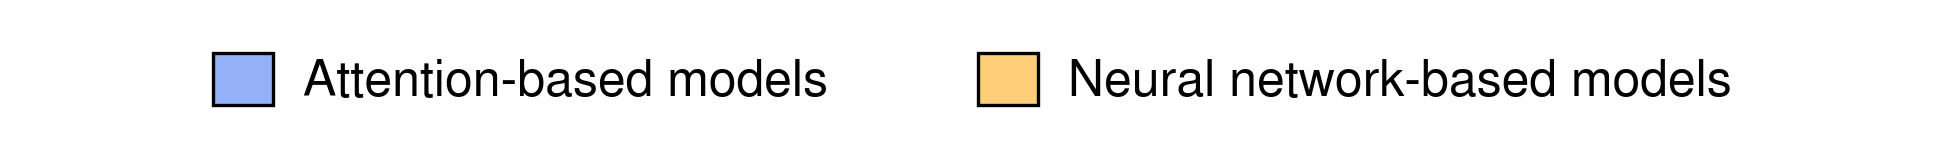

In [ ]:
# legend resized and formatted in illustrator
plot_horizontal_legend(
    legend_dict={
        'Attention-based models': '#94B0F8',
        'Neural network-based models': '#ffce78',
    },
    swatch_size=12,
    text_size=12,
    item_spacing=30,
    swatch_text_gap=6,
    swatch_outline_color='black',
    swatch_outline_width=0.8,
    figsize=None,
    dpi=300,
    default_font='Nimbus Sans',
    save_path=None,
    # save_path=f"{central_figure_dir}/suppfig2_legend",
)

In [ ]:
"""
Save dataframes associated with figures.
"""
save_dfs=False
# save_dfs=True

if save_dfs:
    ms_allele_auc_matrix.to_csv(f"{associated_data_dir}/suppfig2_a_ms_allele_auc_matrix.csv")
    ms_allele_auc_matrix_pval_df.to_csv(f"{associated_data_dir}/suppfig2_a_ms_allele_auc_matrix_pval_df.csv")

    ms_allele_auc01_matrix.to_csv(f"{associated_data_dir}/suppfig2_b_ms_allele_auc01_matrix.csv")
    ms_allele_auc01_matrix_pval_df.to_csv(f"{associated_data_dir}/suppfig2_b_ms_allele_auc01_matrix_pval_df.csv")

    ms_allele_ppvn_matrix.to_csv(f"{associated_data_dir}/suppfig2_c_ms_allele_ppvn_matrix.csv")
    ms_allele_ppvn_matrix_pval_df.to_csv(f"{associated_data_dir}/suppfig2_c_ms_allele_ppvn_matrix_pval_df.csv")


### Supplementary Figure 3: Model correlations on MS data

In [ ]:
# compute metrics
score_cols=["mhcprime", "mhc_pred_0", "ms_log_odds", "score", "presentation_score", "EL_score", "BA_score", "munis", "transphla", "bigmhc", "deepattentionpan", "Pathogen_score_nmp42", "Neo_score_nmp42", "capsnetmhc_anthem", "capsnetmhc_iedb"]

# spearman correlation of ms positive scores only between mhcprime and all other models per allele
ms_pos_spearman_corr_to_mhcprime=compute_spearman_matrix_optimized(ms_test_data_with_benchmarking_model_scores.query("allele != 'C0301' and label ==1"), score_cols, "mhcprime", allele_col='allele', return_float64=True, disable_tqdm=False)

# spearman correlation between model scores per allele averaged for ms positives
ms_pos_avg_spearman_corr_per_allele_matrix=pairwise_spearman_by_group(ms_test_data_with_benchmarking_model_scores.query("allele != 'C0301' and label ==1"), score_cols, split_col='allele', disable_tqdm=False)

# ap matrix
ms_allele_ap_matrix=compute_ap_matrix_optimized(ms_test_data_with_benchmarking_model_scores.query("allele != 'C0301'"), score_cols, label_col='label', allele_col='allele', disable_tqdm=True)
ms_allele_ap_matrix["hla"]=[a[0] for a in ms_allele_ap_matrix.index.tolist()]

100%|██████████| 141/141 [00:00<00:00, 1600.82it/s]


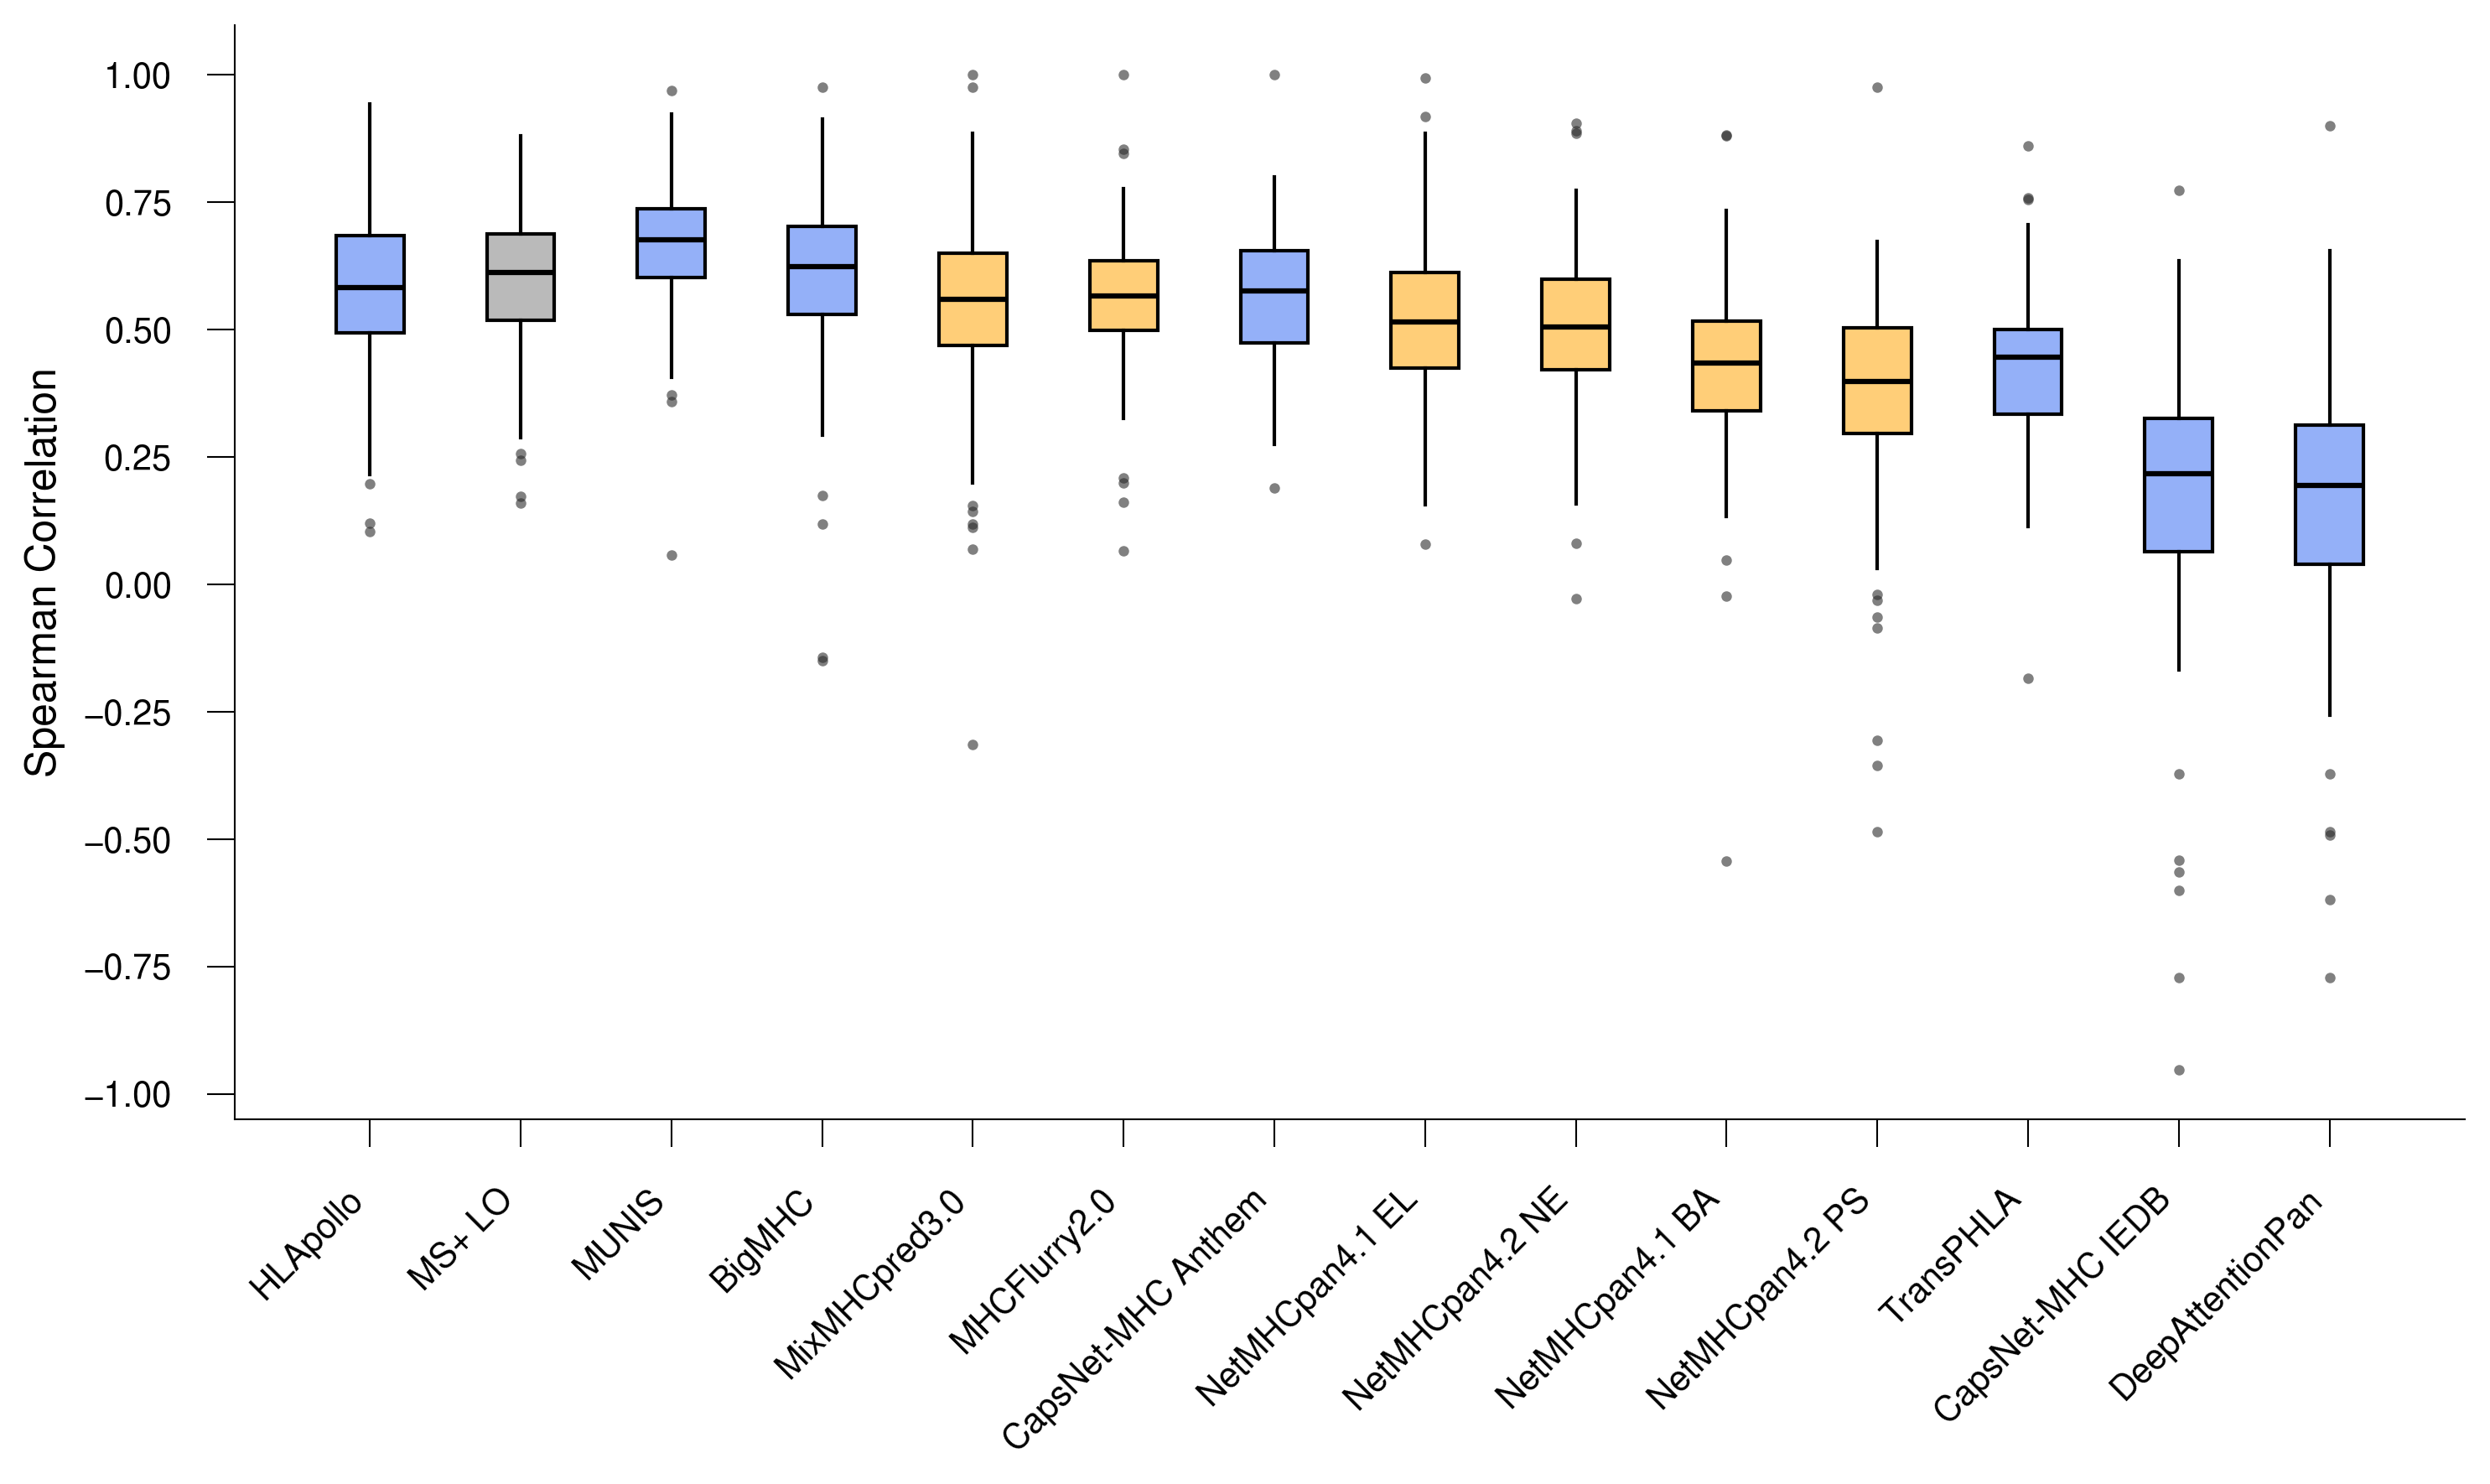

In [ ]:
# ms pos mhcprime corr boxplots
boxplot_groups={
    # "MHCPrime": [(ms_pos_spearman_corr_to_mhcprime, 'mhcprime')],
    "HLApollo": [(ms_pos_spearman_corr_to_mhcprime, 'mhc_pred_0')],
    "MS+ LO": [(ms_pos_spearman_corr_to_mhcprime, 'ms_log_odds')],
    "MUNIS": [(ms_pos_spearman_corr_to_mhcprime, 'munis')],
    "BigMHC": [(ms_pos_spearman_corr_to_mhcprime, 'bigmhc')],
    "MixMHCpred3.0": [(ms_pos_spearman_corr_to_mhcprime, 'score')],
    "MHCFlurry2.0": [(ms_pos_spearman_corr_to_mhcprime, 'presentation_score')],
    "CapsNet-MHC Anthem": [(ms_pos_spearman_corr_to_mhcprime, 'capsnetmhc_anthem')],
    "NetMHCpan4.1 EL": [(ms_pos_spearman_corr_to_mhcprime, 'EL_score')],
    "NetMHCpan4.2 NE": [(ms_pos_spearman_corr_to_mhcprime, 'Neo_score_nmp42')],
    "NetMHCpan4.1 BA": [(ms_pos_spearman_corr_to_mhcprime, 'BA_score')],
    "NetMHCpan4.2 PS": [(ms_pos_spearman_corr_to_mhcprime, 'Pathogen_score_nmp42')],
    "TransPHLA": [(ms_pos_spearman_corr_to_mhcprime, 'transphla')],
    "CapsNet-MHC IEDB": [(ms_pos_spearman_corr_to_mhcprime, 'capsnetmhc_iedb')],
    "DeepAttentionPan": [(ms_pos_spearman_corr_to_mhcprime, 'deepattentionpan')],
}


transformer_based_color="#94B0F8"
nn_based_color="#ffce78"
lo_color="#bababa"
colors={
    # "mhcprime": "#081470",
    "mhc_pred_0": transformer_based_color,
    "ms_log_odds": lo_color,
    "presentation_score":nn_based_color, 
    "score":nn_based_color, 
    "EL_score": nn_based_color,
    "BA_score": nn_based_color,
    "munis": transformer_based_color, 
    "transphla": transformer_based_color,
    "bigmhc": transformer_based_color, 
    "deepattentionpan": transformer_based_color,
    "Pathogen_score_nmp42":nn_based_color, 
    "Neo_score_nmp42":nn_based_color, 
    "capsnetmhc_anthem": transformer_based_color,
    "capsnetmhc_iedb": transformer_based_color, 
}

plot_params = {
    'title': '',
    'title_fontsize': 16,
    'title_bold': False,
    'xlabel': '',
    'ylabel': 'AUC',
    'xlabel_fontsize': 12,
    'ylabel_fontsize': 12,
    'figsize': (10, 6),
    'dpi': 300,
    'legend_fontsize': 12,
    'legend_cols': 5,
    'legend_handle_size': 0.9,
    'marker_size': 3,
    'axis_linewidth': 0.5,
    'tick_length': 8.0,
    'xlabel_pad': 5.0,
    'ylabel_pad': 5.0,
    'xtick_labelsize': 10,
    'ytick_labelsize': 10,
    'xtick_rotation': 45

}

plotting_params=dict(
    colors=colors,
    legend=None,
    plot_params=plot_params,
    grid_alpha=0.0,
    default_font='Nimbus Sans',
    box_width=0.1,
    group_spacing=0.1,
    box_spacing=0.05,
    box_outline_color='black',
    box_outline_width=1.0,
    box_flier_marker='o',
    box_flier_size=3,
    box_flier_color="#2B2B2B",
    box_flier_alpha=0.6,
    box_flier_edge_width=0,
    box_median_color='black',
    box_median_width=1.5,
    box_whisker_style='-',
    box_whisker_width=1.0,
    box_notch=False,
    box_patch_alpha=1.0,
    hline_y=None,
    hline_label=None,
    hline_color='gray',
    hline_width=1.0,
    hline_style='--',
    hline_text=None,
    hline_text_position='above',
    hline_text_color=None,
    hline_text_fontsize=10,
    hline_text_offset=0.01,
    hline_text_x_offset=0.05,
    hline_in_legend=True,
    reference_hlines=None,
    legend_mode=None,
    legend_loc='lower center',
    legend_bbox=None,
    legend_ncol=None,
    # ylim=(0, 1.0),
    compute_pvalues=False,
    pvalue_test='wilcoxon', 
    cluster_col='louvain_id',
    # sort_by ="median",
    sort_ascending=False, 
)

plot_params["ylabel"]="Spearman Correlation"
plotting_params["plot_params"]=plot_params
boxplot_groups=replace_boxplot_df(boxplot_groups, ms_pos_spearman_corr_to_mhcprime)
_=plot_grouped_boxplots(
    groups=boxplot_groups,
    save_path=None,
    # save_path=f"{central_figure_dir}/suppfig3_a_ms_pos_spearman_corr_to_mhcprime_per_model", 
    **plotting_params
)


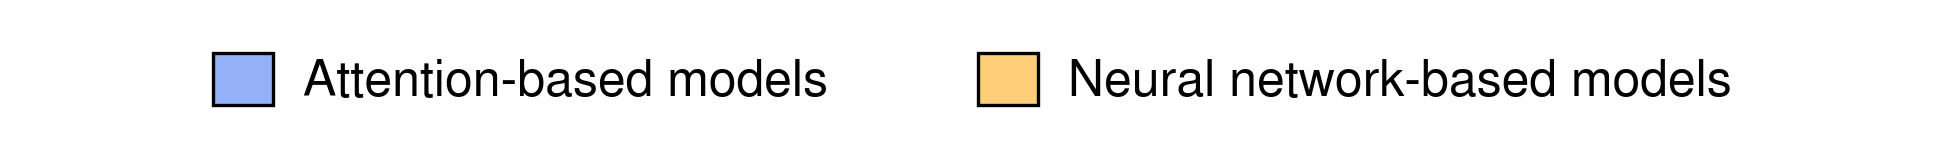

In [ ]:
# legend resized and formatted in illustrator
plot_horizontal_legend(
    legend_dict={
        'Attention-based models': '#94B0F8',
        'Neural network-based models': '#ffce78',
    },
    swatch_size=12,
    text_size=12,
    item_spacing=30,
    swatch_text_gap=6,
    swatch_outline_color='black',
    swatch_outline_width=0.8,
    figsize=None,
    dpi=300,
    default_font='Nimbus Sans',
    save_path=None,
    # save_path=f"{central_figure_dir}/suppfig3_a_legend",
)

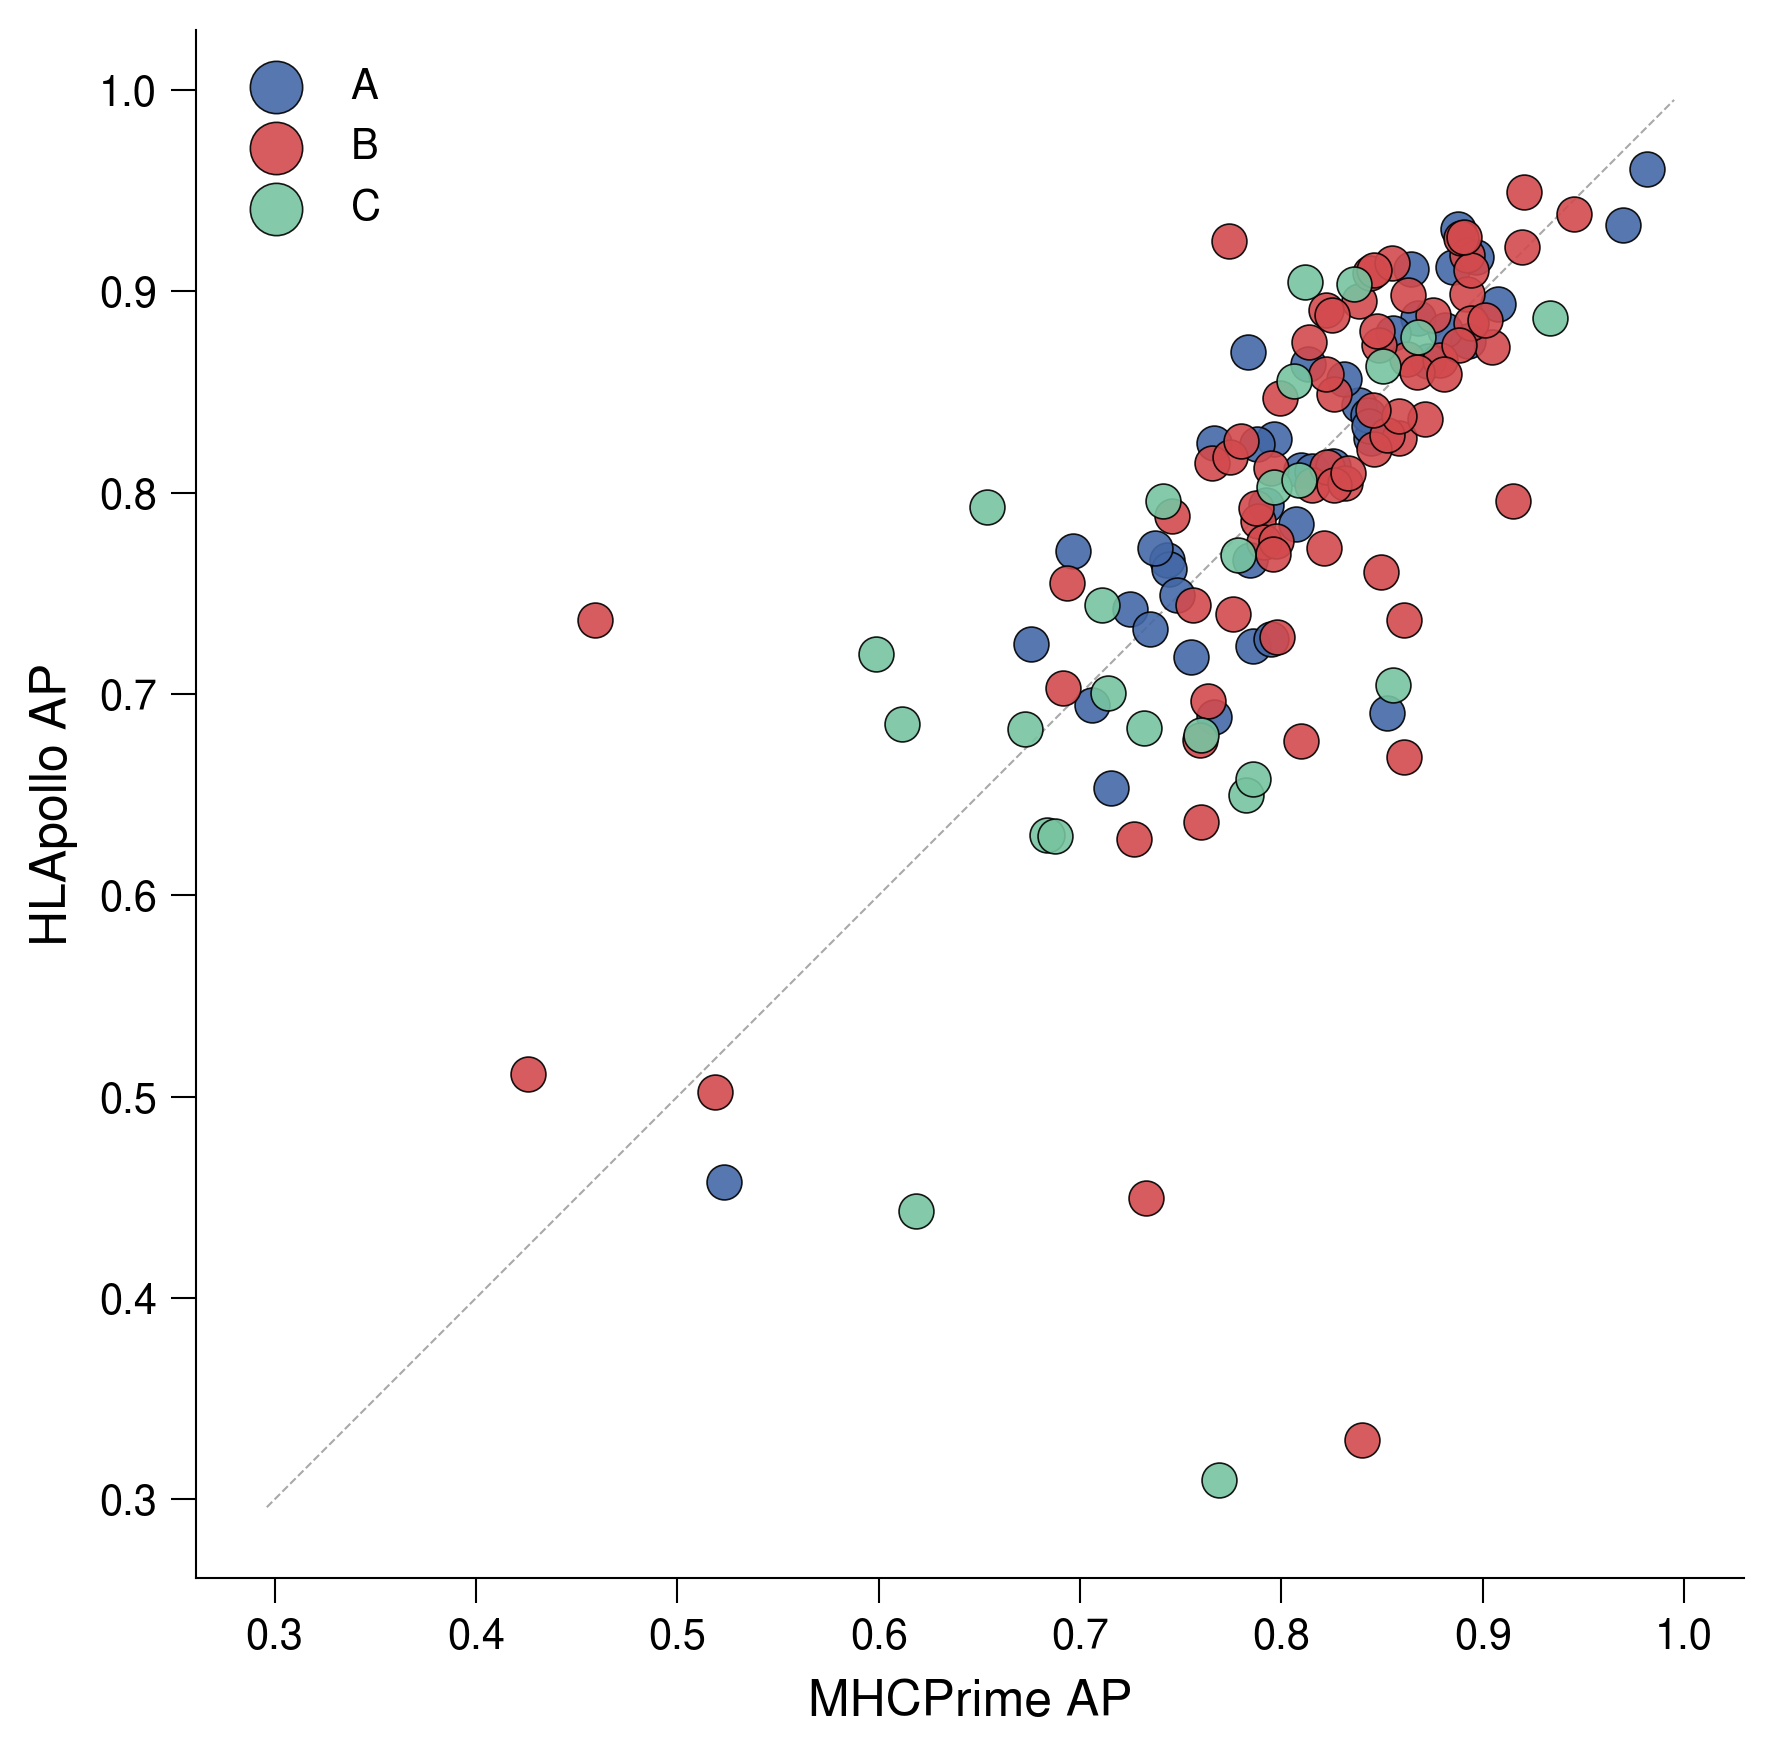

In [ ]:
# per allele ap comparison between MHCPrime and HLApollo
_=plot_scatter_simple(
    df=ms_allele_ap_matrix,
    x_col='mhcprime',
    y_col='mhc_pred_0',
    xlabel='MHCPrime AP',
    ylabel='HLApollo AP',
    hue_col='hla',
    hue_colors={'A': '#4468a7', 'B': '#d34a4d', 'C': '#77c4a0'},
    hue_order=['A', 'B', 'C'],
    point_size=70,
    point_alpha=0.9,
    point_edge_color='black',
    point_edge_width=0.4,
    show_xy_line=True,
    xy_line_color='darkgray',
    xy_line_style='--',
    xy_line_width=0.5,
    figsize=(6, 6),
    dpi=300,
    equal_aspect=True,
    remove_top_right_spines=True,
    spine_width=0.5,
    tick_length=6.0,
    xtick_labelsize=10,
    ytick_labelsize=10,
    xlabel_fontsize=12,
    ylabel_fontsize=12,
    xlabel_pad=5.0,
    ylabel_pad=5.0,
    default_font='Nimbus Sans',
    save_path=None,
    # save_path=f"{central_figure_dir}/suppfig3_b_mhcprime_vs_hlapollo_ap_scatterplot",

)

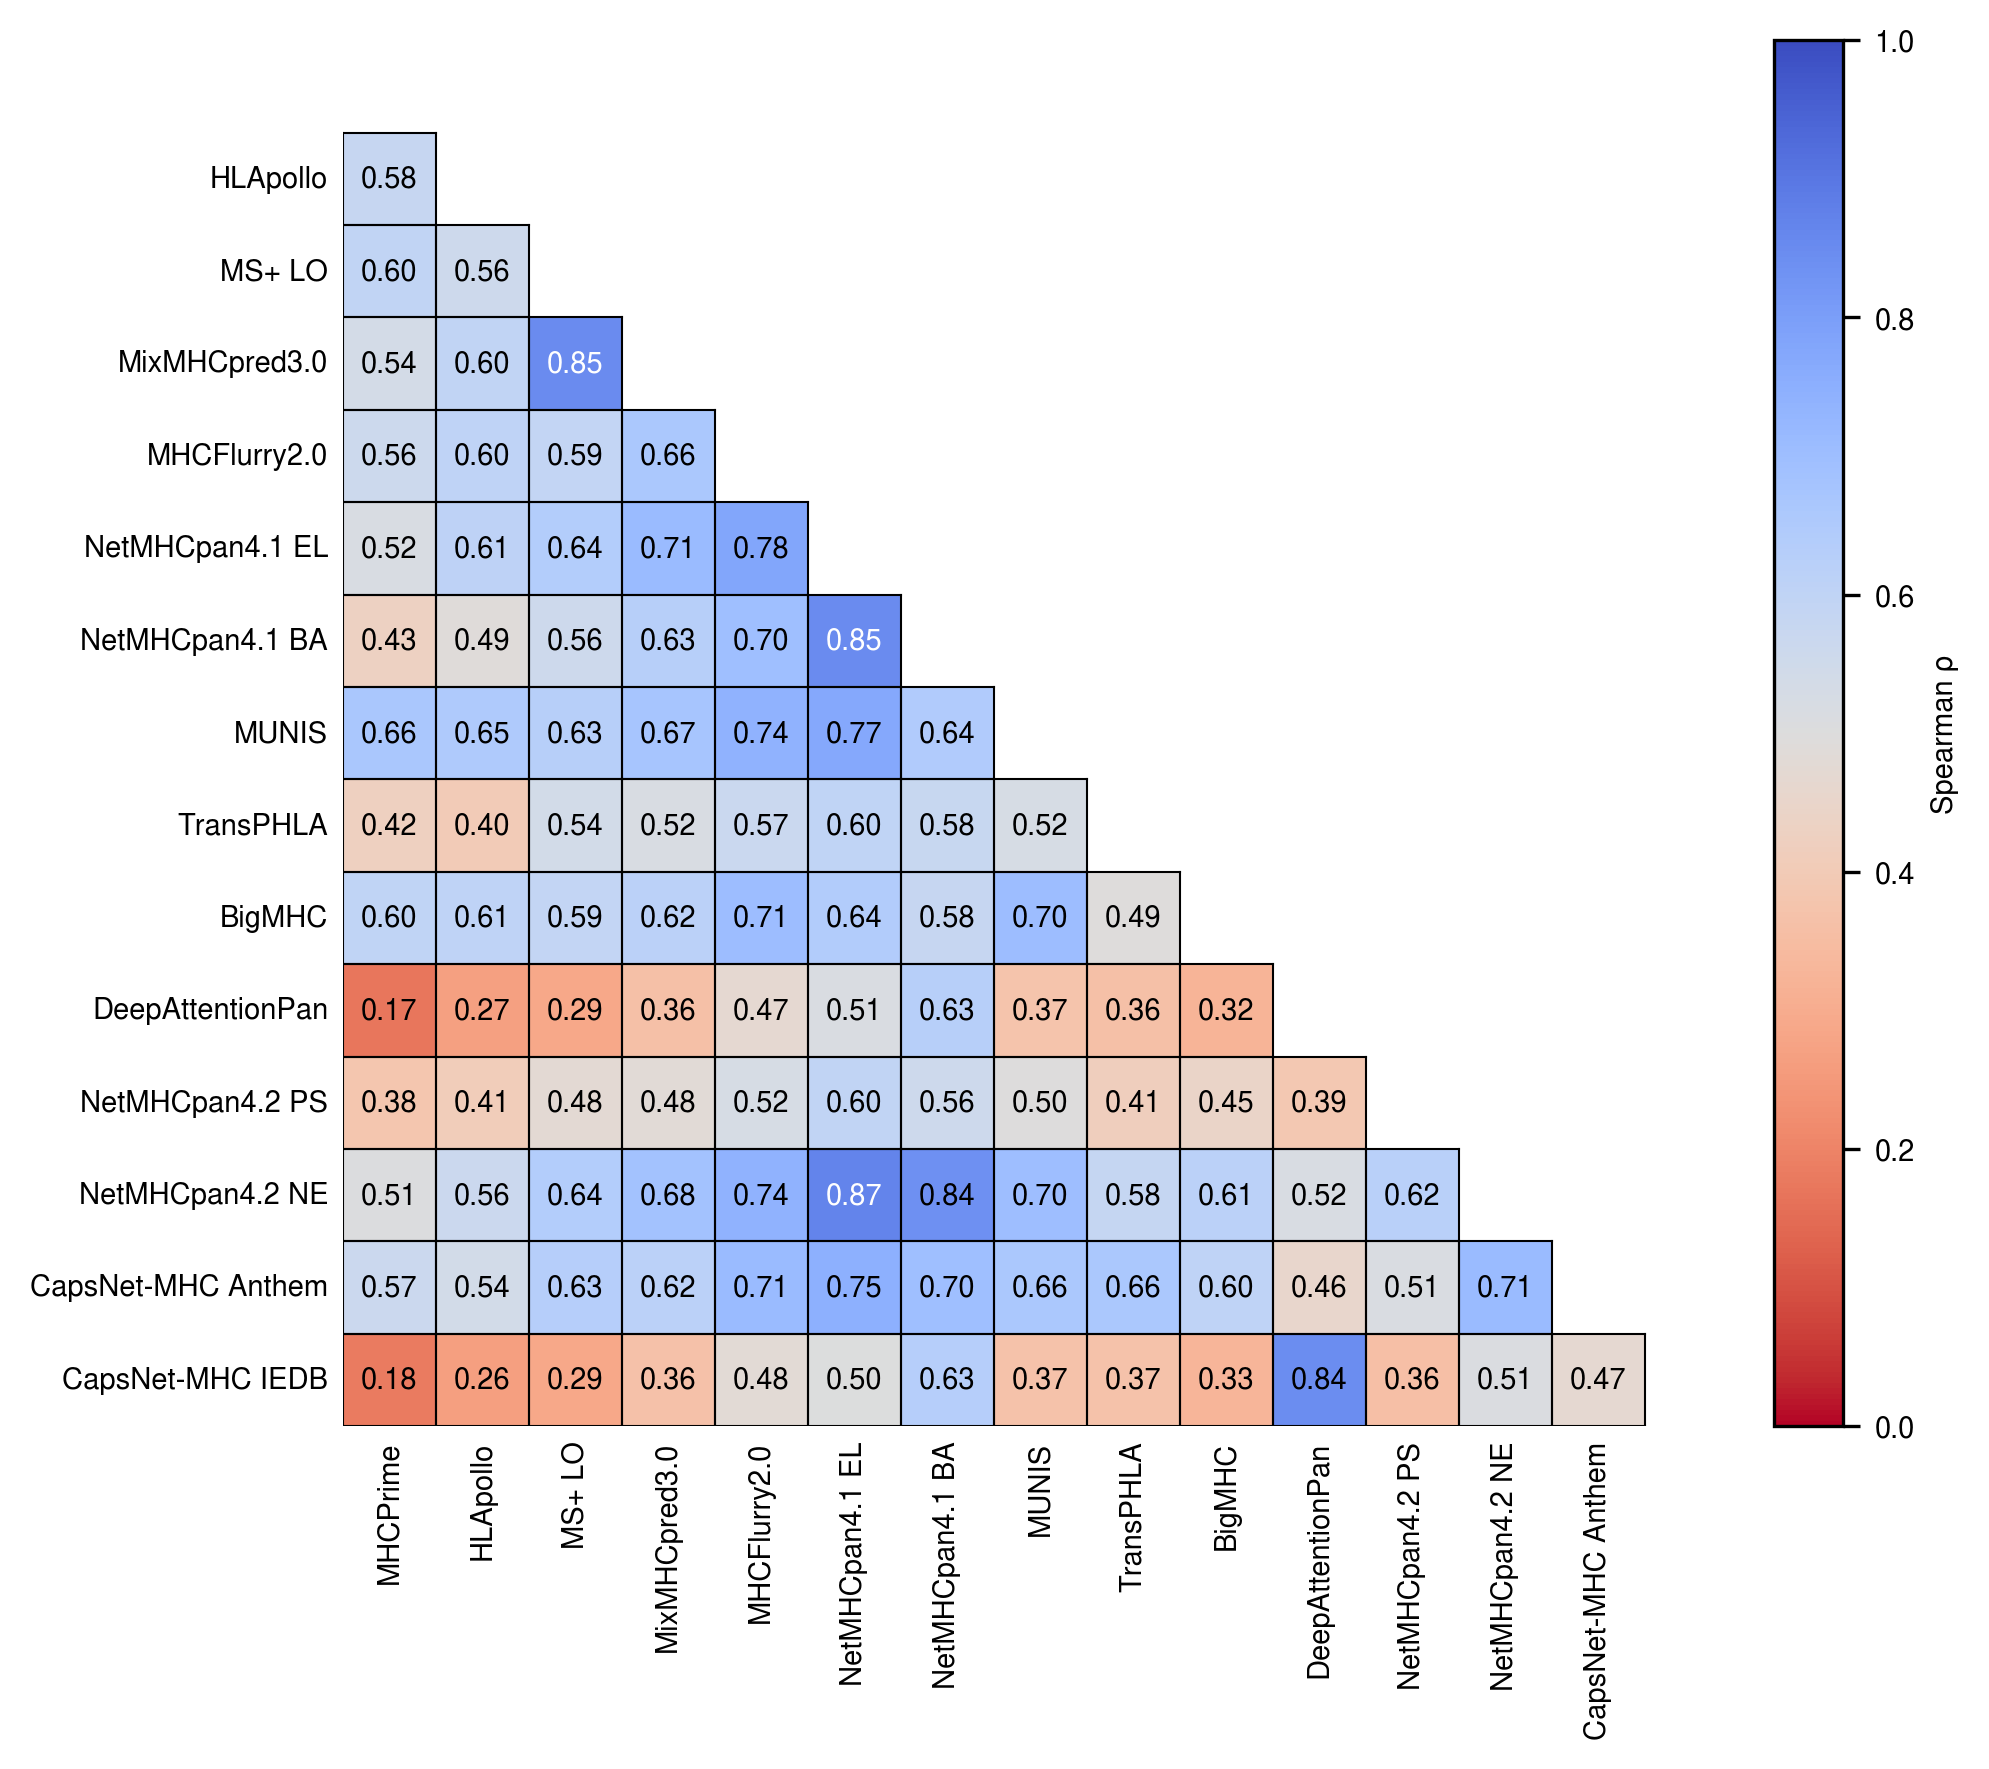

In [ ]:
# correlation across all models heatmap
col_label_map = {
    'mhcprime': 'MHCPrime',
    'mhc_pred_0': 'HLApollo',
    'ms_log_odds': 'MS+ LO',
    'munis': 'MUNIS',
    'bigmhc': 'BigMHC',
    'score': 'MixMHCpred3.0',
    'presentation_score': 'MHCFlurry2.0',
    'capsnetmhc_anthem': 'CapsNet-MHC Anthem',
    'EL_score': 'NetMHCpan4.1 EL',
    'Neo_score_nmp42': 'NetMHCpan4.2 NE',
    'BA_score': 'NetMHCpan4.1 BA',
    'Pathogen_score_nmp42': 'NetMHCpan4.2 PS',
    'transphla': 'TransPHLA',
    'capsnetmhc_iedb': 'CapsNet-MHC IEDB',
    'deepattentionpan': 'DeepAttentionPan',
}

_=plot_heatmap(
    df=ms_pos_avg_spearman_corr_per_allele_matrix,
    lower_triangle_only=True,
    exclude_diagonal=True,
    cmap='coolwarm_r',
    vmin=0.0,
    vmax=1.0,
    x_col_labels=col_label_map,
    y_col_labels=col_label_map,
    xtick_rotation=90,
    annot=True,
    annot_fontsize=7,
    annot_decimals=2,
    cell_outline_color='black',
    cell_outline_width=0.5,
    cbar_label='Spearman ρ',
    figsize=(6, 6),
    dpi=300,
    default_font='Nimbus Sans',
    xtick_labelsize=7,
    ytick_labelsize=7,
    cbar_label_fontsize=7,
    cbar_labelsize=7,
    save_path=None,
    # save_path=f"{central_figure_dir}/suppfig3_c_ms_pos_cross_model_score_correlation_heatmap",

)

In [ ]:
"""
Save dataframes associated with figures.
"""
save_dfs=False
# save_dfs=True

if save_dfs:
    ms_pos_spearman_corr_to_mhcprime.to_csv(f"{associated_data_dir}/suppfig3_a_ms_pos_spearman_corr_to_mhcprime.csv")
    ms_allele_ap_matrix.to_csv(f"{associated_data_dir}/suppfig3_b_ms_allele_ap_matrix.csv")
    ms_pos_avg_spearman_corr_per_allele_matrix.to_csv(f"{associated_data_dir}/suppfig3_c_ms_pos_avg_spearman_corr_per_allele_matrix.csv")

### Supplementary Figure 4: AP distributions for non-MS datasets

In [ ]:
%%time
# get the major collected dfs

# yd train and test sets
holec_datasets_dir = DATA_DIR / "Training_Datasets" / "Processed" / "Holec_et_al_2025"
holec_test_set_with_benchmarking_model_scores  = pd.read_csv(f"{holec_datasets_dir}/holec_test_set_with_benchmarking_model_scores.csv", index_col=0)

# episcan train and test sets
episcan_train_test_dir = DATA_DIR / "Training_Datasets" / "Processed" / "EpiScan"
episcan_r9_test_set_with_benchmarking_model_scores=pd.read_csv(f"{episcan_train_test_dir}/episcan_r9_test_set_with_benchmarking_model_scores.csv", index_col=0)
episcan_rt_test_set_with_benchmarking_model_scores=pd.read_csv(f"{episcan_train_test_dir}/episcan_rt_test_set_with_benchmarking_model_scores.csv", index_col=0)

# ba test sets
nmp_ba_data_hla_data_with_benchmarking_model_scores=pd.read_csv(f"{DATA_DIR}/Training_Datasets/Processed/BA/nmp_ba_data_hla_data_with_benchmarking_model_scores.csv", index_col=0)
ba_full_cls_test_set=pd.read_csv(f"{DATA_DIR}/Training_Datasets/Processed/BA/ba_full_cls_test_set.csv", index_col=0)

# escape seq test set
escape_seq_datasets_dir = DATA_DIR / "Training_Datasets/Processed/ESCAPE_seq"
escape_seq_full_cls_test_set_with_benchmarking_model_scores=pd.read_csv(f"{escape_seq_datasets_dir}/escape_seq_full_cls_test_set_with_benchmarking_model_scores.csv", index_col=0)

CPU times: user 2.64 s, sys: 147 ms, total: 2.78 s
Wall time: 2.78 s


In [ ]:
%%time
# process all
holec_test_set_with_benchmarking_model_scores=full_process_data(holec_test_set_with_benchmarking_model_scores, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
holec_test_set_with_benchmarking_model_scores=create_seq_allele_column(holec_test_set_with_benchmarking_model_scores)

episcan_r9_test_set_with_benchmarking_model_scores=full_process_data(episcan_r9_test_set_with_benchmarking_model_scores, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
episcan_r9_test_set_with_benchmarking_model_scores=create_seq_allele_column(episcan_r9_test_set_with_benchmarking_model_scores)

episcan_rt_test_set_with_benchmarking_model_scores=full_process_data(episcan_rt_test_set_with_benchmarking_model_scores, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
episcan_rt_test_set_with_benchmarking_model_scores=create_seq_allele_column(episcan_rt_test_set_with_benchmarking_model_scores)

ba_full_cls_test_set=full_process_data(ba_full_cls_test_set, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
ba_full_cls_test_set=create_seq_allele_column(ba_full_cls_test_set)

nmp_ba_data_hla_data_with_benchmarking_model_scores=full_process_data(nmp_ba_data_hla_data_with_benchmarking_model_scores, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
nmp_ba_data_hla_data_with_benchmarking_model_scores=create_seq_allele_column(nmp_ba_data_hla_data_with_benchmarking_model_scores)

escape_seq_full_cls_test_set_with_benchmarking_model_scores=full_process_data(escape_seq_full_cls_test_set_with_benchmarking_model_scores, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
escape_seq_full_cls_test_set_with_benchmarking_model_scores=create_seq_allele_column(escape_seq_full_cls_test_set_with_benchmarking_model_scores)

CPU times: user 909 ms, sys: 52.2 ms, total: 962 ms
Wall time: 959 ms


In [ ]:
# isolate ba set
ba_full_cls_test_set_with_benchmarking_model_scores=nmp_ba_data_hla_data_with_benchmarking_model_scores[nmp_ba_data_hla_data_with_benchmarking_model_scores.seq_allele.isin(ba_full_cls_test_set.seq_allele.tolist())].copy()
print_data_stats(ba_full_cls_test_set_with_benchmarking_model_scores)

Total: 111,500
Pos: 1,115 | 1.00%
Neg: 110,385 | 99.00%
N alleles: 71


In [ ]:
# add seq len
holec_test_set_with_benchmarking_model_scores["seq_len"]=holec_test_set_with_benchmarking_model_scores.seq.str.replace("$", "").apply(len)
episcan_r9_test_set_with_benchmarking_model_scores["seq_len"]=episcan_r9_test_set_with_benchmarking_model_scores.seq.str.replace("$", "").apply(len)
episcan_rt_test_set_with_benchmarking_model_scores["seq_len"]=episcan_rt_test_set_with_benchmarking_model_scores.seq.str.replace("$", "").apply(len)
ba_full_cls_test_set_with_benchmarking_model_scores["seq_len"]=ba_full_cls_test_set_with_benchmarking_model_scores.seq.str.replace("$", "").apply(len)
escape_seq_full_cls_test_set_with_benchmarking_model_scores["seq_len"]=escape_seq_full_cls_test_set_with_benchmarking_model_scores.seq.str.replace("$", "").apply(len)

In [ ]:
%%time
# compute metrics
score_cols=["mhcprime", "mhc_pred_0", "ms_log_odds", "score", "presentation_score", "EL_score", "BA_score", "munis", "transphla", "bigmhc", "deepattentionpan", "Pathogen_score_nmp42", "Neo_score_nmp42", "capsnetmhc_anthem", "capsnetmhc_iedb"]

holec_allele_ap_matrix=compute_ap_matrix_optimized(holec_test_set_with_benchmarking_model_scores, score_cols, label_col='label', allele_col='allele', disable_tqdm=False)

episcan_r9_allele_ap_matrix=compute_ap_matrix_optimized(episcan_r9_test_set_with_benchmarking_model_scores, score_cols, label_col='label', allele_col='allele', disable_tqdm=False)

episcan_rt_allele_ap_matrix=compute_ap_matrix_optimized(episcan_rt_test_set_with_benchmarking_model_scores, score_cols, label_col='label', allele_col='allele', disable_tqdm=False)

ba_cls_allele_ap_matrix=compute_ap_matrix_optimized(ba_full_cls_test_set_with_benchmarking_model_scores, score_cols, label_col='label', allele_col='allele', disable_tqdm=False)

escape_cls_allele_ap_matrix=compute_ap_matrix_optimized(escape_seq_full_cls_test_set_with_benchmarking_model_scores, score_cols, label_col='label', allele_col='allele', disable_tqdm=False)

  0%|          | 0/16 [00:00<?, ?it/s]

100%|██████████| 44/44 [00:00<00:00, 128.62it/s]

CPU times: user 1.8 s, sys: 9.88 ms, total: 1.81 s
Wall time: 1.8 s


In [ ]:
# p-values
print("Holec")
holec_allele_ap_matrix_pval_df=compute_pairwise_pvalues_general(holec_allele_ap_matrix[score_cols])
display(holec_allele_ap_matrix_pval_df)
display(pval_to_stars(holec_allele_ap_matrix_pval_df))

print("EpiScan R9")
episcan_r9_allele_ap_matrix_pval_df=compute_pairwise_pvalues_general(episcan_r9_allele_ap_matrix[score_cols])
display(episcan_r9_allele_ap_matrix_pval_df)
display(pval_to_stars(episcan_r9_allele_ap_matrix_pval_df))

print("EpiScan RT")
episcan_rt_allele_ap_matrix_pval_df=compute_pairwise_pvalues_general(episcan_rt_allele_ap_matrix[score_cols])
display(episcan_rt_allele_ap_matrix_pval_df)
display(pval_to_stars(episcan_rt_allele_ap_matrix_pval_df))

print("BA")
ba_cls_allele_ap_matrix_pval_df=compute_pairwise_pvalues_general(ba_cls_allele_ap_matrix[score_cols])
display(ba_cls_allele_ap_matrix_pval_df)
display(pval_to_stars(ba_cls_allele_ap_matrix_pval_df))

print("ESCAPE-seq")
escape_cls_allele_ap_matrix_pval_df=compute_pairwise_pvalues_general(escape_cls_allele_ap_matrix[score_cols])
display(escape_cls_allele_ap_matrix_pval_df)
display(pval_to_stars(escape_cls_allele_ap_matrix_pval_df))

Holec


,mhcprime,mhc_pred_0,ms_log_odds,score,presentation_score,EL_score,BA_score,munis,transphla,bigmhc,deepattentionpan,Pathogen_score_nmp42,Neo_score_nmp42,capsnetmhc_anthem,capsnetmhc_iedb
mhcprime,1.000000,0.231201,0.002136,0.009186,0.561890,0.006287,0.000214,0.057678,0.001312,0.252228,0.050659,0.010986,0.021393,0.104584,0.065399
mhc_pred_0,0.231201,1.000000,0.057678,0.192810,0.403748,0.073914,0.001312,0.433197,0.001312,0.860260,0.050659,0.005157,0.297852,0.596588,0.143860
ms_log_odds,0.002136,0.057678,1.000000,0.083252,0.028992,0.705719,0.057678,0.010986,0.000031,0.322510,0.860260,0.000031,0.231201,0.297852,0.781952
score,0.009186,0.192810,0.083252,1.000000,0.021393,0.528168,0.050659,0.038635,0.000031,0.297852,0.705719,0.000153,0.297852,0.252228,0.979950
presentation_score,0.561890,0.403748,0.028992,0.021393,1.000000,0.000061,0.000153,0.495422,0.001007,0.528168,0.007629,0.002686,0.015503,0.083252,0.028992
EL_score,0.006287,0.073914,0.705719,0.528168,0.000061,1.000000,0.001007,0.013092,0.000031,0.129730,0.668549,0.000427,0.211426,0.006287,0.860260
BA_score,0.000214,0.001312,0.057678,0.050659,0.000153,0.001007,1.000000,0.000153,0.000031,0.009186,0.001678,0.000031,0.000092,0.000092,0.003357
munis,0.057678,0.433197,0.010986,0.038635,0.495422,0.013092,0.000153,1.000000,0.000092,0.668549,0.083252,0.000580,0.104584,0.322510,0.211426
transphla,0.001312,0.001312,0.000031,0.000031,0.001007,0.000031,0.000031,0.000092,1.000000,0.010986,0.000061,0.083252,0.000061,0.000061,0.000214
bigmhc,0.252228,0.860260,0.322510,0.297852,0.528168,0.129730,0.009186,0.668549,0.010986,1.000000,0.083252,0.000305,0.561890,0.403748,0.192810


,mhcprime,mhc_pred_0,ms_log_odds,score,presentation_score,EL_score,BA_score,munis,transphla,bigmhc,deepattentionpan,Pathogen_score_nmp42,Neo_score_nmp42,capsnetmhc_anthem,capsnetmhc_iedb
mhcprime,ns,ns,**,**,ns,**,***,ns,**,ns,ns,*,*,ns,ns
mhc_pred_0,ns,ns,ns,ns,ns,ns,**,ns,**,ns,ns,**,ns,ns,ns
ms_log_odds,**,ns,ns,ns,*,ns,ns,*,****,ns,ns,****,ns,ns,ns
score,**,ns,ns,ns,*,ns,ns,*,****,ns,ns,***,ns,ns,ns
presentation_score,ns,ns,*,*,ns,****,***,ns,**,ns,**,**,*,ns,*
EL_score,**,ns,ns,ns,****,ns,**,*,****,ns,ns,***,ns,**,ns
BA_score,***,**,ns,ns,***,**,ns,***,****,**,**,****,****,****,**
munis,ns,ns,*,*,ns,*,***,ns,****,ns,ns,***,ns,ns,ns
transphla,**,**,****,****,**,****,****,****,ns,*,****,ns,****,****,***
bigmhc,ns,ns,ns,ns,ns,ns,**,ns,*,ns,ns,***,ns,ns,ns


EpiScan R9


,mhcprime,mhc_pred_0,ms_log_odds,score,presentation_score,EL_score,BA_score,munis,transphla,bigmhc,deepattentionpan,Pathogen_score_nmp42,Neo_score_nmp42,capsnetmhc_anthem,capsnetmhc_iedb
mhcprime,1.000,0.125,0.125,0.875,0.125,0.875,1.000,0.125,0.125,0.125,1.000,0.125,0.375,0.625,1.000
mhc_pred_0,0.125,1.000,0.875,0.250,0.625,0.250,0.125,0.125,0.125,0.125,0.125,0.250,0.625,0.125,0.125
ms_log_odds,0.125,0.875,1.000,0.125,0.875,0.250,0.125,0.125,0.125,0.125,0.125,0.250,0.625,0.250,0.125
score,0.875,0.250,0.125,1.000,0.250,1.000,0.875,0.250,0.125,0.250,0.875,0.250,0.625,0.625,0.875
presentation_score,0.125,0.625,0.875,0.250,1.000,0.125,0.125,0.375,0.250,0.250,0.125,0.125,0.250,0.375,0.125
EL_score,0.875,0.250,0.250,1.000,0.125,1.000,0.375,0.875,0.125,0.875,0.375,0.125,0.625,0.625,0.625
BA_score,1.000,0.125,0.125,0.875,0.125,0.375,1.000,0.125,0.125,0.250,0.625,0.125,0.125,0.250,0.375
munis,0.125,0.125,0.125,0.250,0.375,0.875,0.125,1.000,0.125,0.375,0.375,0.250,1.000,0.875,0.375
transphla,0.125,0.125,0.125,0.125,0.250,0.125,0.125,0.125,1.000,0.125,0.125,0.375,0.125,0.125,0.125
bigmhc,0.125,0.125,0.125,0.250,0.250,0.875,0.250,0.375,0.125,1.000,0.625,0.250,0.875,1.000,0.625


...

,mhcprime,mhc_pred_0,ms_log_odds,score,presentation_score,EL_score,BA_score,munis,transphla,bigmhc,deepattentionpan,Pathogen_score_nmp42,Neo_score_nmp42,capsnetmhc_anthem,capsnetmhc_iedb
mhcprime,1.000000e+00,1.017096e-01,5.901204e-02,3.067658e-03,4.367393e-01,1.245802e-10,3.919879e-12,2.599769e-02,1.672143e-10,2.635031e-01,1.779011e-10,5.380048e-01,5.772406e-09,9.352328e-02,9.601515e-09
mhc_pred_0,1.017096e-01,1.000000e+00,8.906229e-01,4.807510e-02,5.842525e-01,9.953955e-09,3.255690e-12,4.234454e-01,5.037111e-10,5.928869e-01,2.701244e-09,9.713830e-01,1.939978e-08,5.639574e-01,2.445023e-08
ms_log_odds,5.901204e-02,8.906229e-01,1.000000e+00,3.423886e-02,3.652941e-01,2.865249e-10,8.731881e-13,7.809953e-01,2.942992e-12,7.536005e-01,3.928474e-11,8.032557e-01,6.137571e-10,4.059310e-01,3.700075e-10
score,3.067658e-03,4.807510e-02,3.423886e-02,1.000000e+00,1.202666e-02,7.516109e-08,6.121753e-12,3.267338e-01,2.977384e-12,2.182335e-01,4.169158e-10,2.291200e-01,1.767560e-07,4.864472e-01,1.755790e-08
presentation_score,4.367393e-01,5.842525e-01,3.652941e-01,1.202666e-02,1.000000e+00,2.575993e-11,1.025804e-12,1.426297e-01,1.879864e-12,3.297558e-01,2.127044e-11,4.494427e-01,6.959380e-11,5.308775e-02,4.401343e-10
EL_score,1.245802e-10,9.953955e-09,2.865249e-10,7.516109e-08,2.575993e-11,1.000000e+00,3.670616e-11,5.171683e-09,3.136319e-13,1.693394e-08,3.174075e-08,7.958664e-06,8.044591e-02,3.375939e-08,2.730455e-05
BA_score,3.919879e-12,3.255690e-12,8.731881e-13,6.121753e-12,1.025804e-12,3.670616e-11,1.000000e+00,1.369432e-11,2.428672e-13,5.648803e-11,5.858364e-03,8.634665e-12,3.187490e-12,7.655791e-12,9.516082e-01
munis,2.599769e-02,4.234454e-01,7.809953e-01,3.267338e-01,1.426297e-01,5.171683e-09,1.369432e-11,1.000000e+00,9.198404e-12,6.403225e-01,1.417312e-08,2.756945e-01,1.391230e-06,8.040346e-01,1.599596e-07
transphla,1.672143e-10,5.037111e-10,2.942992e-12,2.977384e-12,1.879864e-12,3.136319e-13,2.428672e-13,9.198404e-12,1.000000e+00,6.295157e-10,5.249357e-13,6.937345e-08,6.783969e-13,2.820003e-12,1.228213e-12
bigmhc,2.635031e-01,5.928869e-01,7.536005e-01,2.182335e-01,3.297558e-01,1.693394e-08,5.648803e-11,6.403225e-01,6.295157e-10,1.000000e+00,6.079277e-10,9.119250e-01,1.635423e-07,6.239326e-01,1.300565e-08


,mhcprime,mhc_pred_0,ms_log_odds,score,presentation_score,EL_score,BA_score,munis,transphla,bigmhc,deepattentionpan,Pathogen_score_nmp42,Neo_score_nmp42,capsnetmhc_anthem,capsnetmhc_iedb
mhcprime,ns,ns,ns,**,ns,****,****,*,****,ns,****,ns,****,ns,****
mhc_pred_0,ns,ns,ns,*,ns,****,****,ns,****,ns,****,ns,****,ns,****
ms_log_odds,ns,ns,ns,*,ns,****,****,ns,****,ns,****,ns,****,ns,****
score,**,*,*,ns,*,****,****,ns,****,ns,****,ns,****,ns,****
presentation_score,ns,ns,ns,*,ns,****,****,ns,****,ns,****,ns,****,ns,****
EL_score,****,****,****,****,****,ns,****,****,****,****,****,****,ns,****,****
BA_score,****,****,****,****,****,****,ns,****,****,****,**,****,****,****,ns
munis,*,ns,ns,ns,ns,****,****,ns,****,ns,****,ns,****,ns,****
transphla,****,****,****,****,****,****,****,****,ns,****,****,****,****,****,****
bigmhc,ns,ns,ns,ns,ns,****,****,ns,****,ns,****,ns,****,ns,****


ESCAPE-seq


,mhcprime,mhc_pred_0,ms_log_odds,score,presentation_score,EL_score,BA_score,munis,transphla,bigmhc,deepattentionpan,Pathogen_score_nmp42,Neo_score_nmp42,capsnetmhc_anthem,capsnetmhc_iedb
mhcprime,1.000000e+00,8.760647e-01,7.309076e-03,9.115527e-03,0.187220,2.741127e-04,3.585553e-06,8.238859e-07,3.032758e-02,0.921780,5.938544e-06,9.716973e-05,1.028581e-04,2.439096e-02,1.358492e-03
mhc_pred_0,8.760647e-01,1.000000e+00,1.065027e-01,3.223157e-02,0.267965,3.328387e-05,5.920338e-07,3.127450e-05,6.226057e-02,0.598826,4.596546e-07,1.994994e-04,1.649540e-05,1.345348e-02,1.028581e-04
ms_log_odds,7.309076e-03,1.065027e-01,1.000000e+00,3.450202e-01,0.520870,3.126742e-02,4.806012e-05,3.210361e-03,7.718520e-05,0.327444,2.341047e-04,6.434971e-07,9.798667e-03,5.514294e-01,1.763652e-02
score,9.115527e-03,3.223157e-02,3.450202e-01,1.000000e+00,0.171966,2.834133e-01,2.396931e-03,2.250672e-01,2.280245e-05,0.031267,6.051695e-03,1.743578e-07,1.144425e-01,6.562950e-01,1.646893e-01
presentation_score,1.872202e-01,2.679654e-01,5.208696e-01,1.719658e-01,1.000000,1.772853e-03,6.836333e-06,2.288777e-02,3.210361e-03,0.369353,6.836333e-06,8.420941e-06,1.088507e-04,1.719658e-01,1.553304e-03
EL_score,2.741127e-04,3.328387e-05,3.126742e-02,2.834133e-01,0.001773,1.000000e+00,2.471426e-06,8.578830e-01,1.442520e-06,0.000987,2.019836e-03,2.178012e-09,1.171880e-01,6.747004e-02,2.295809e-01
BA_score,3.585553e-06,5.920338e-07,4.806012e-05,2.396931e-03,0.000007,2.471426e-06,1.000000e+00,8.789812e-03,3.172659e-09,0.000012,9.769610e-01,2.353318e-11,4.988712e-03,6.372811e-06,3.743385e-02
munis,8.238859e-07,3.127450e-05,3.210361e-03,2.250672e-01,0.022888,8.578830e-01,8.789812e-03,1.000000e+00,5.531829e-06,0.002608,1.090689e-02,1.437627e-08,5.670263e-01,2.295809e-01,3.104485e-01
transphla,3.032758e-02,6.226057e-02,7.718520e-05,2.280245e-05,0.003210,1.442520e-06,3.172659e-09,5.531829e-06,1.000000e+00,0.089640,2.499987e-07,3.126742e-02,1.909621e-07,1.909621e-07,4.794684e-06
bigmhc,9.217798e-01,5.988265e-01,3.274443e-01,3.126742e-02,0.369353,9.866294e-04,1.183596e-05,2.608098e-03,8.964014e-02,1.000000,7.330912e-06,1.241130e-03,1.606244e-04,5.582617e-02,5.044430e-04


,mhcprime,mhc_pred_0,ms_log_odds,score,presentation_score,EL_score,BA_score,munis,transphla,bigmhc,deepattentionpan,Pathogen_score_nmp42,Neo_score_nmp42,capsnetmhc_anthem,capsnetmhc_iedb
mhcprime,ns,ns,**,**,ns,***,****,****,*,ns,****,****,***,*,**
mhc_pred_0,ns,ns,ns,*,ns,****,****,****,ns,ns,****,***,****,*,***
ms_log_odds,**,ns,ns,ns,ns,*,****,**,****,ns,***,****,**,ns,*
score,**,*,ns,ns,ns,ns,**,ns,****,*,**,****,ns,ns,ns
presentation_score,ns,ns,ns,ns,ns,**,****,*,**,ns,****,****,***,ns,**
EL_score,***,****,*,ns,**,ns,****,ns,****,***,**,****,ns,ns,ns
BA_score,****,****,****,**,****,****,ns,**,****,****,ns,****,**,****,*
munis,****,****,**,ns,*,ns,**,ns,****,**,*,****,ns,ns,ns
transphla,*,ns,****,****,**,****,****,****,ns,ns,****,*,****,****,****
bigmhc,ns,ns,ns,*,ns,***,****,**,ns,ns,****,**,***,ns,***


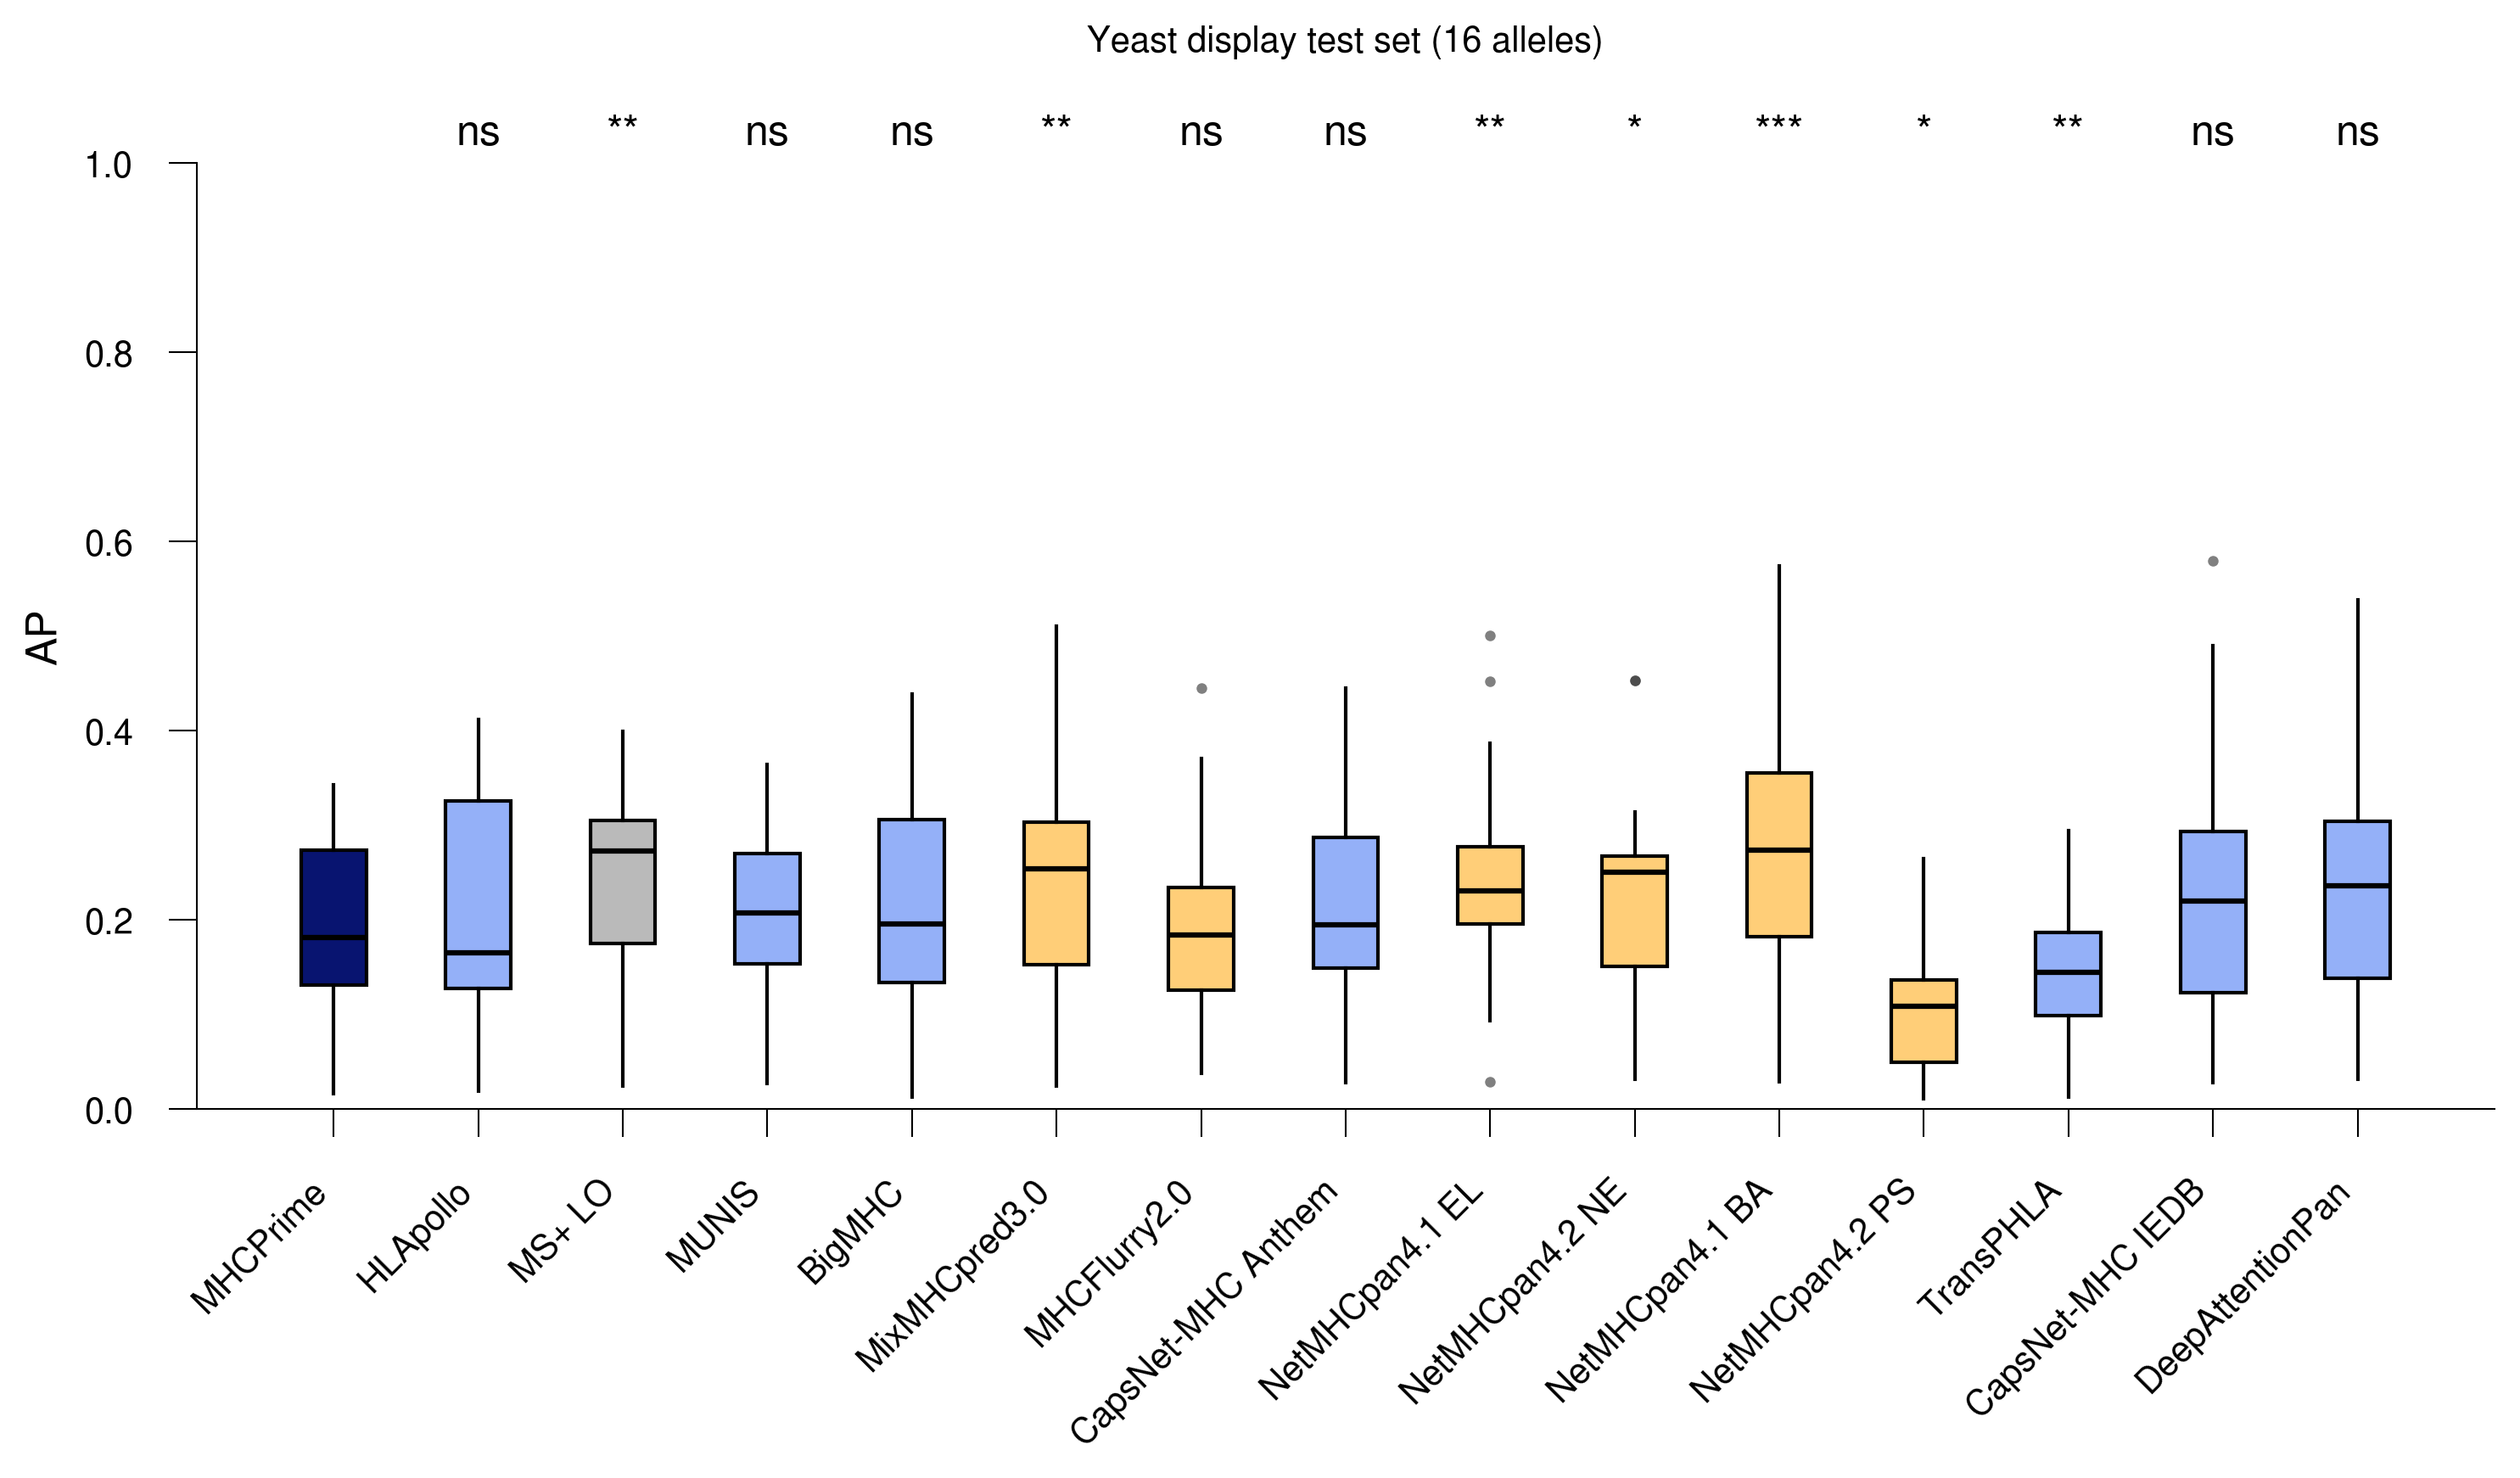

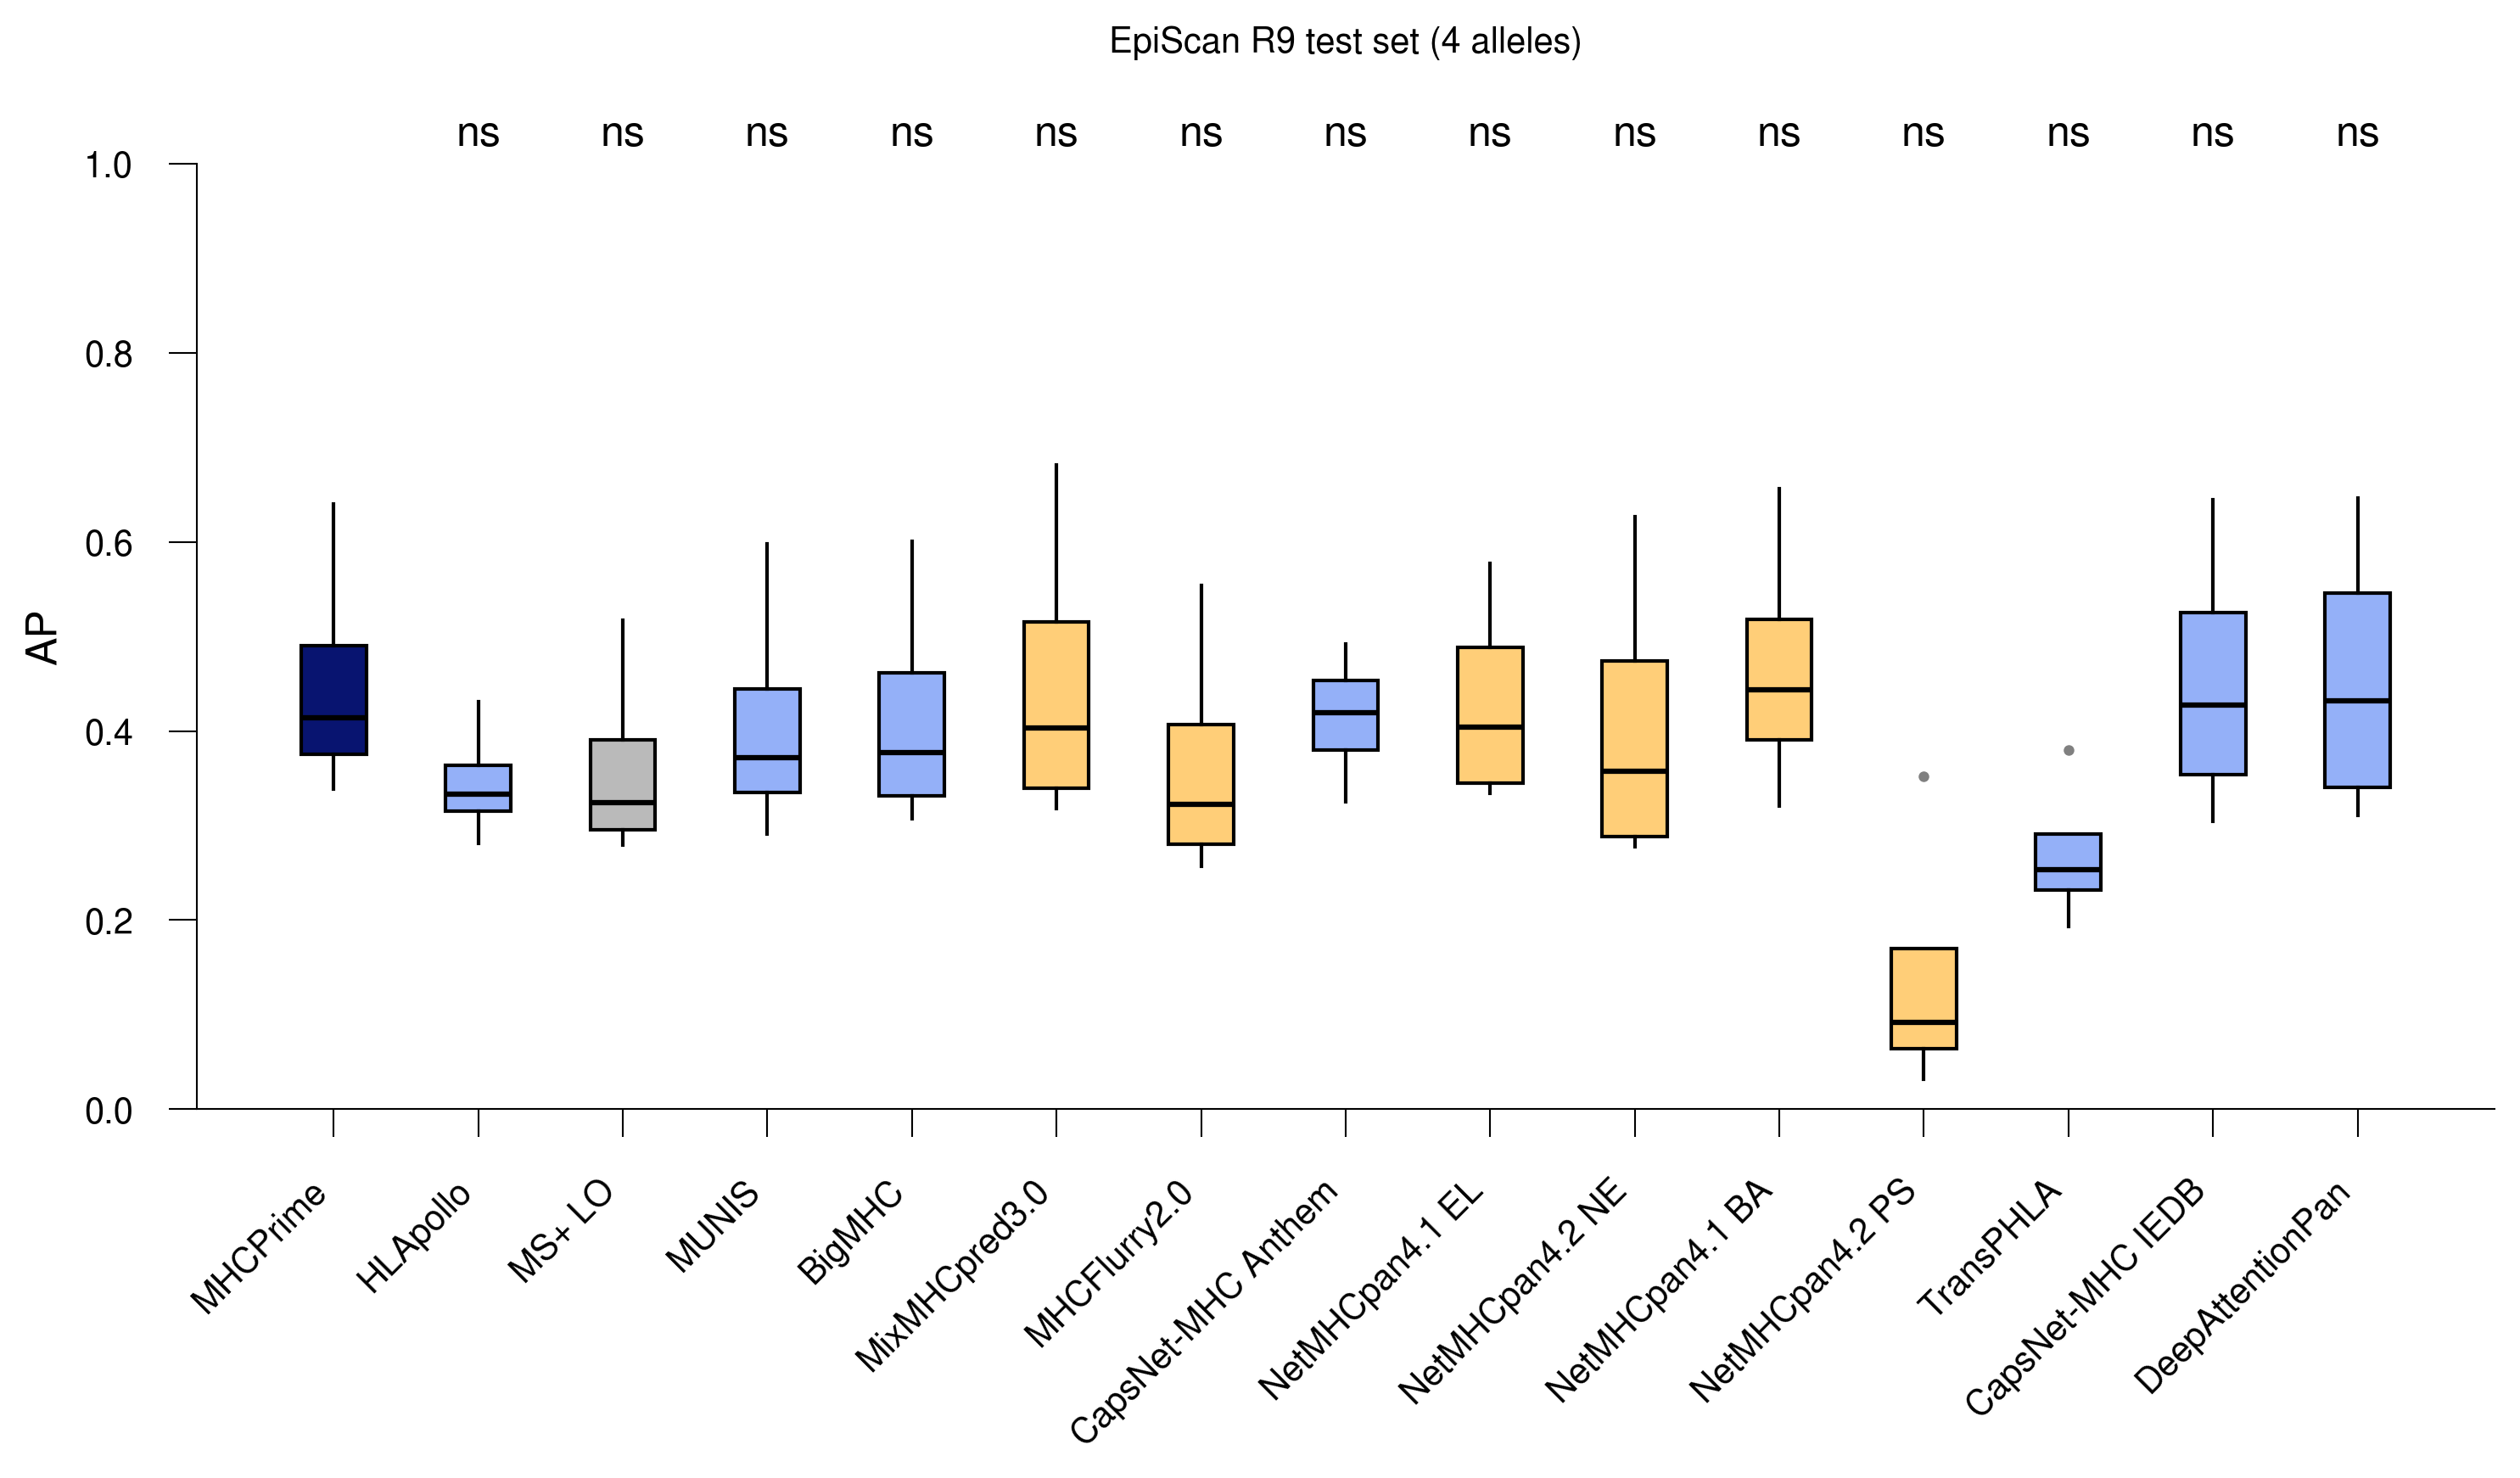

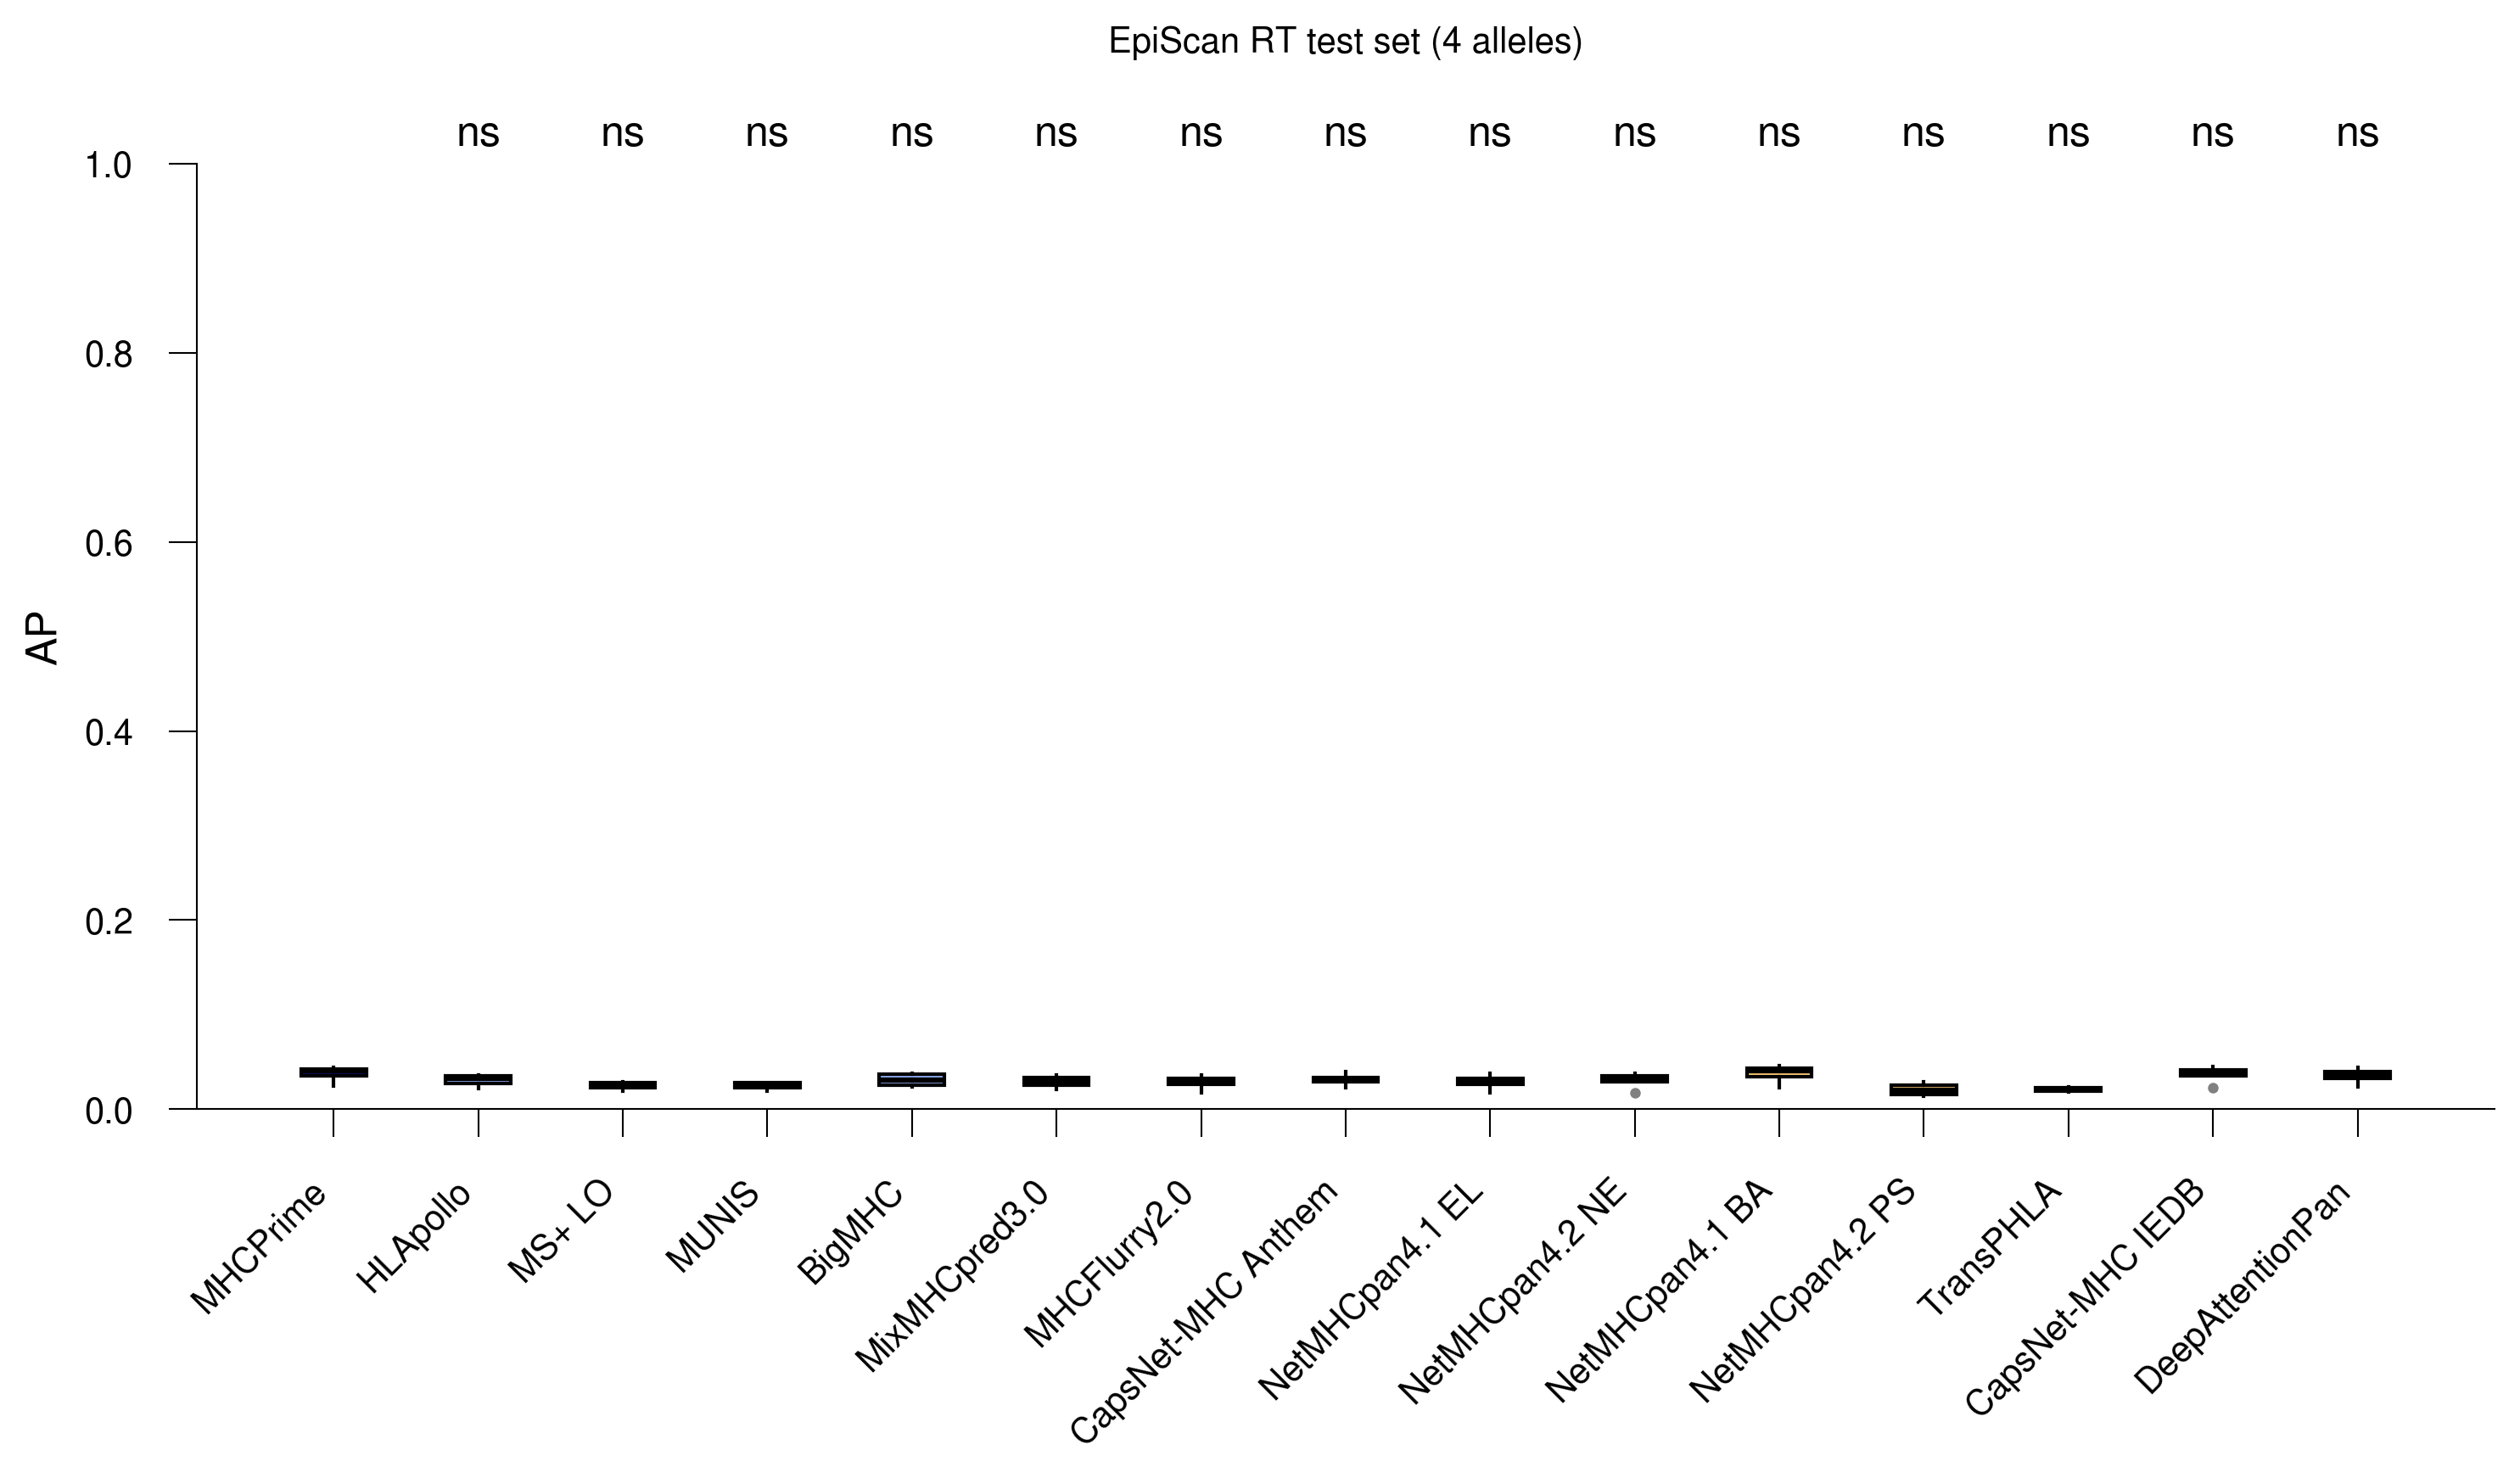

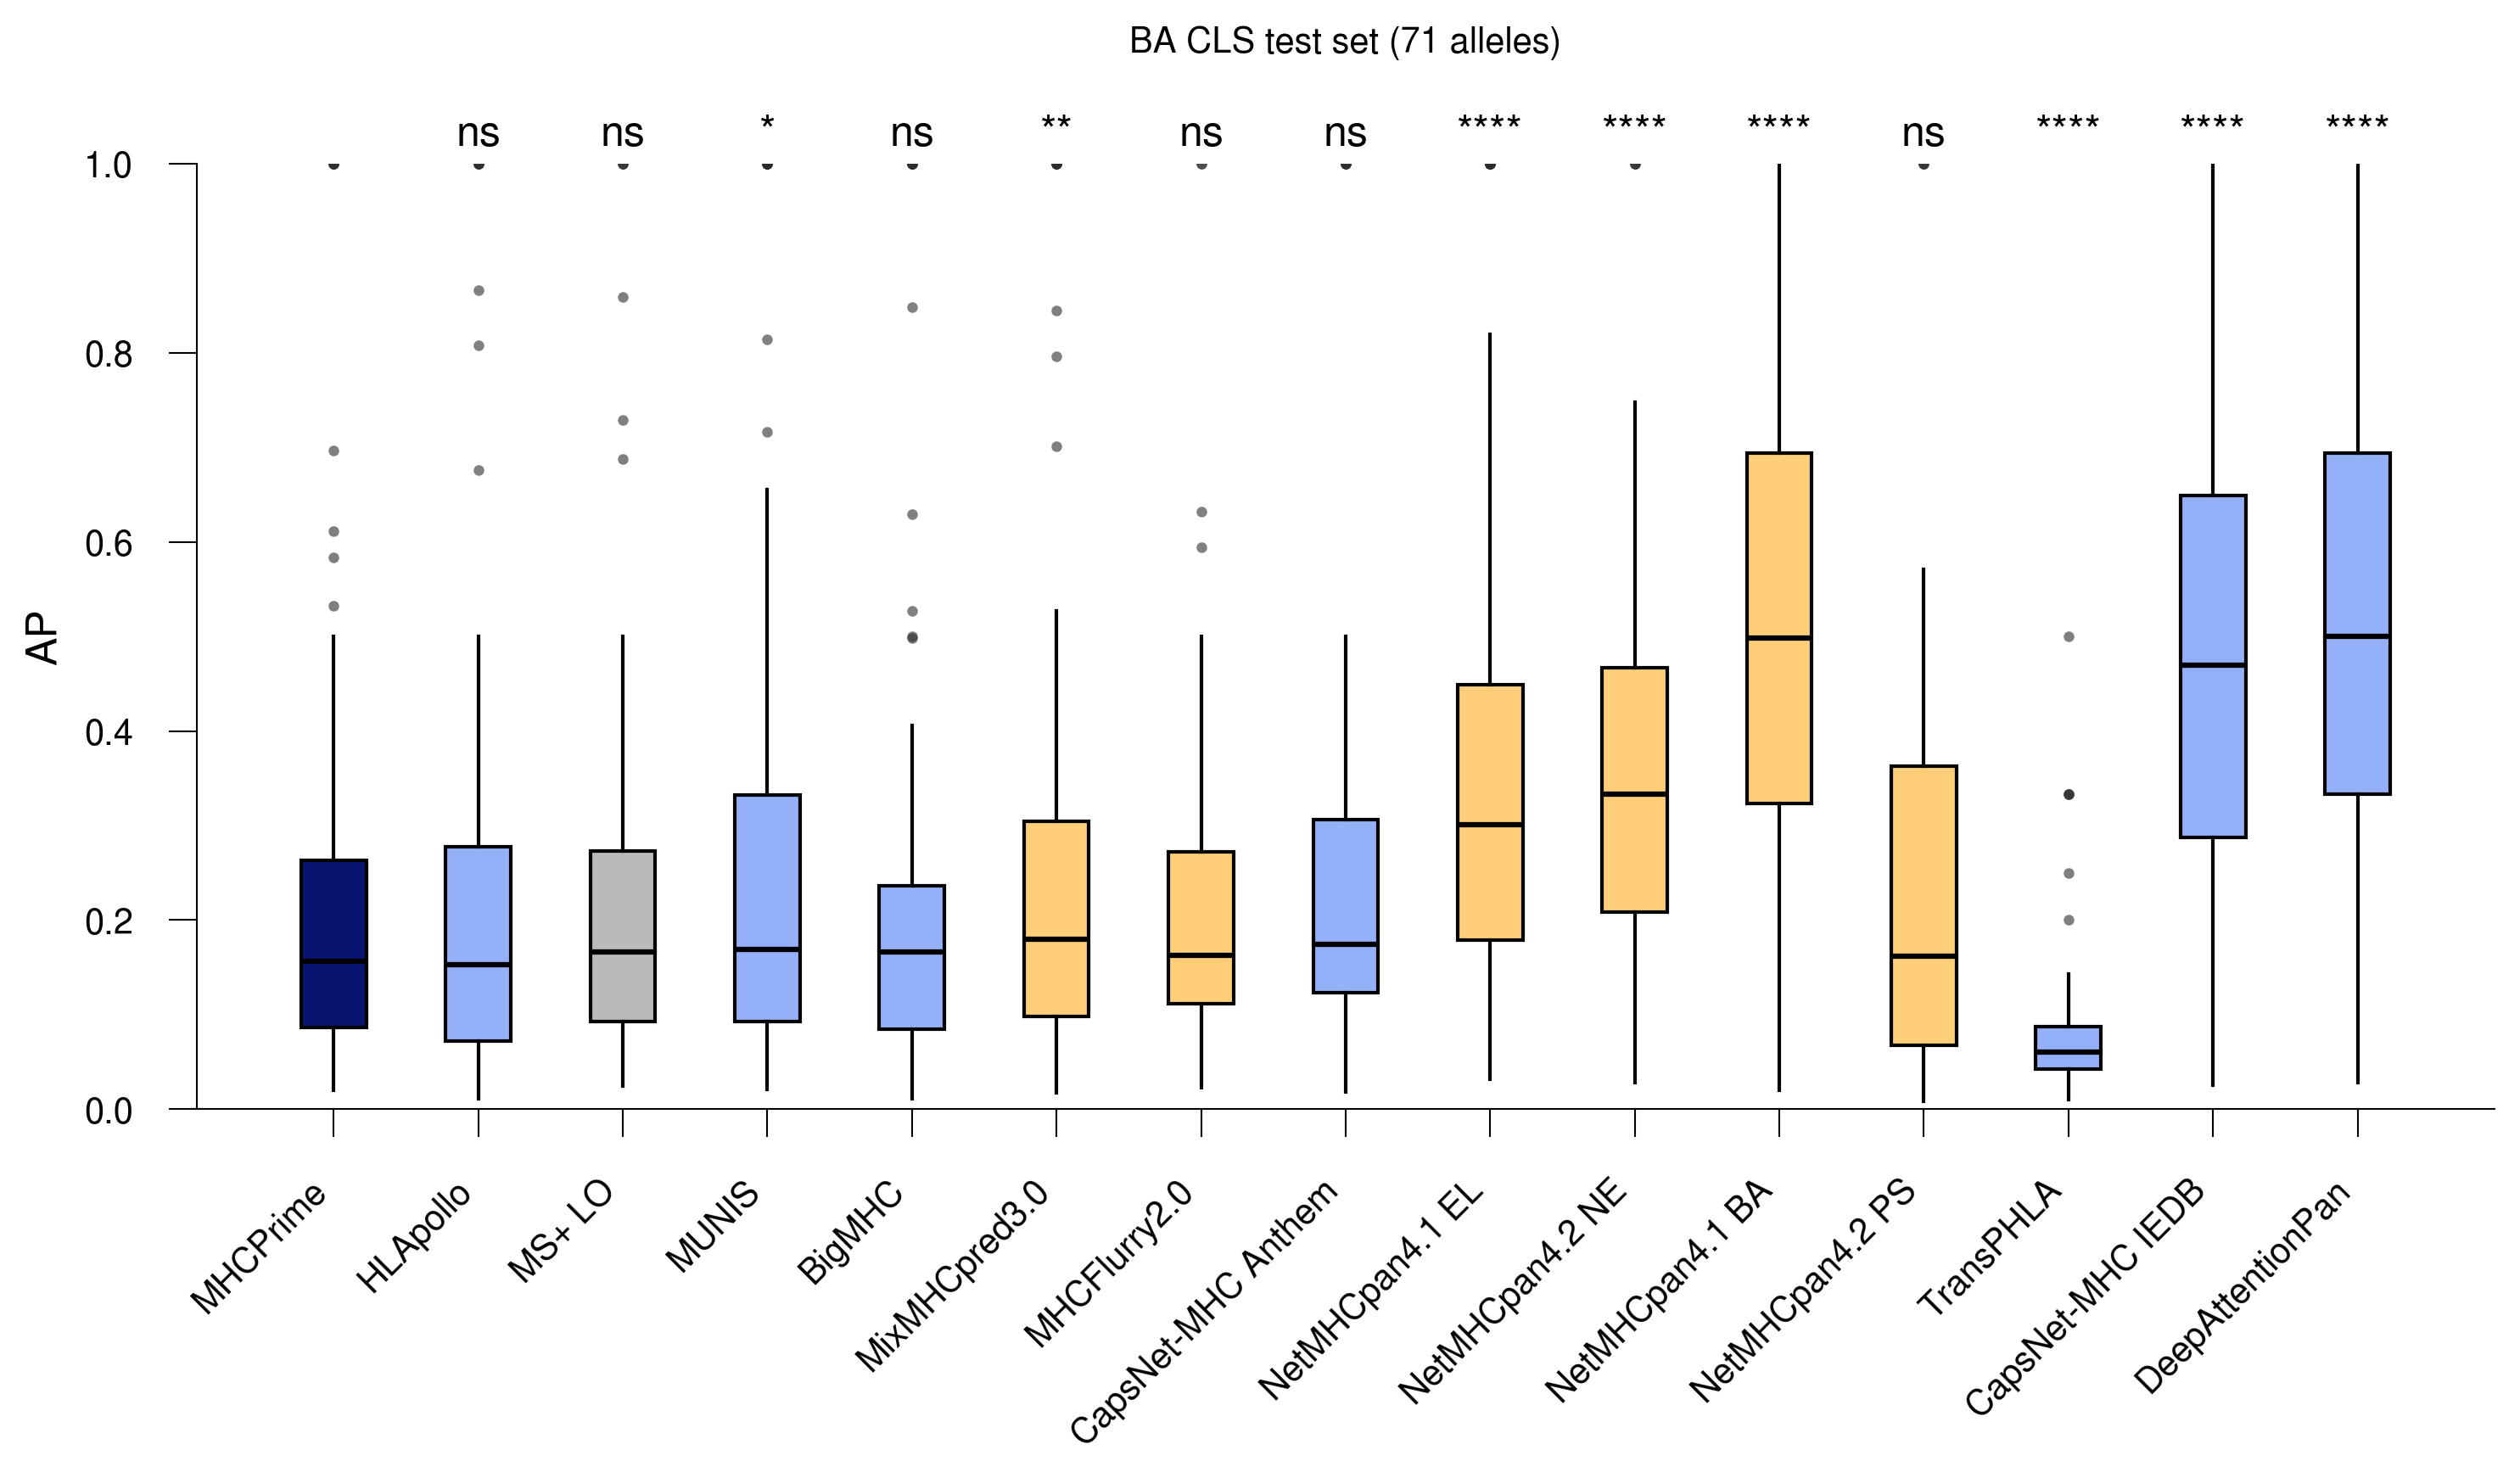

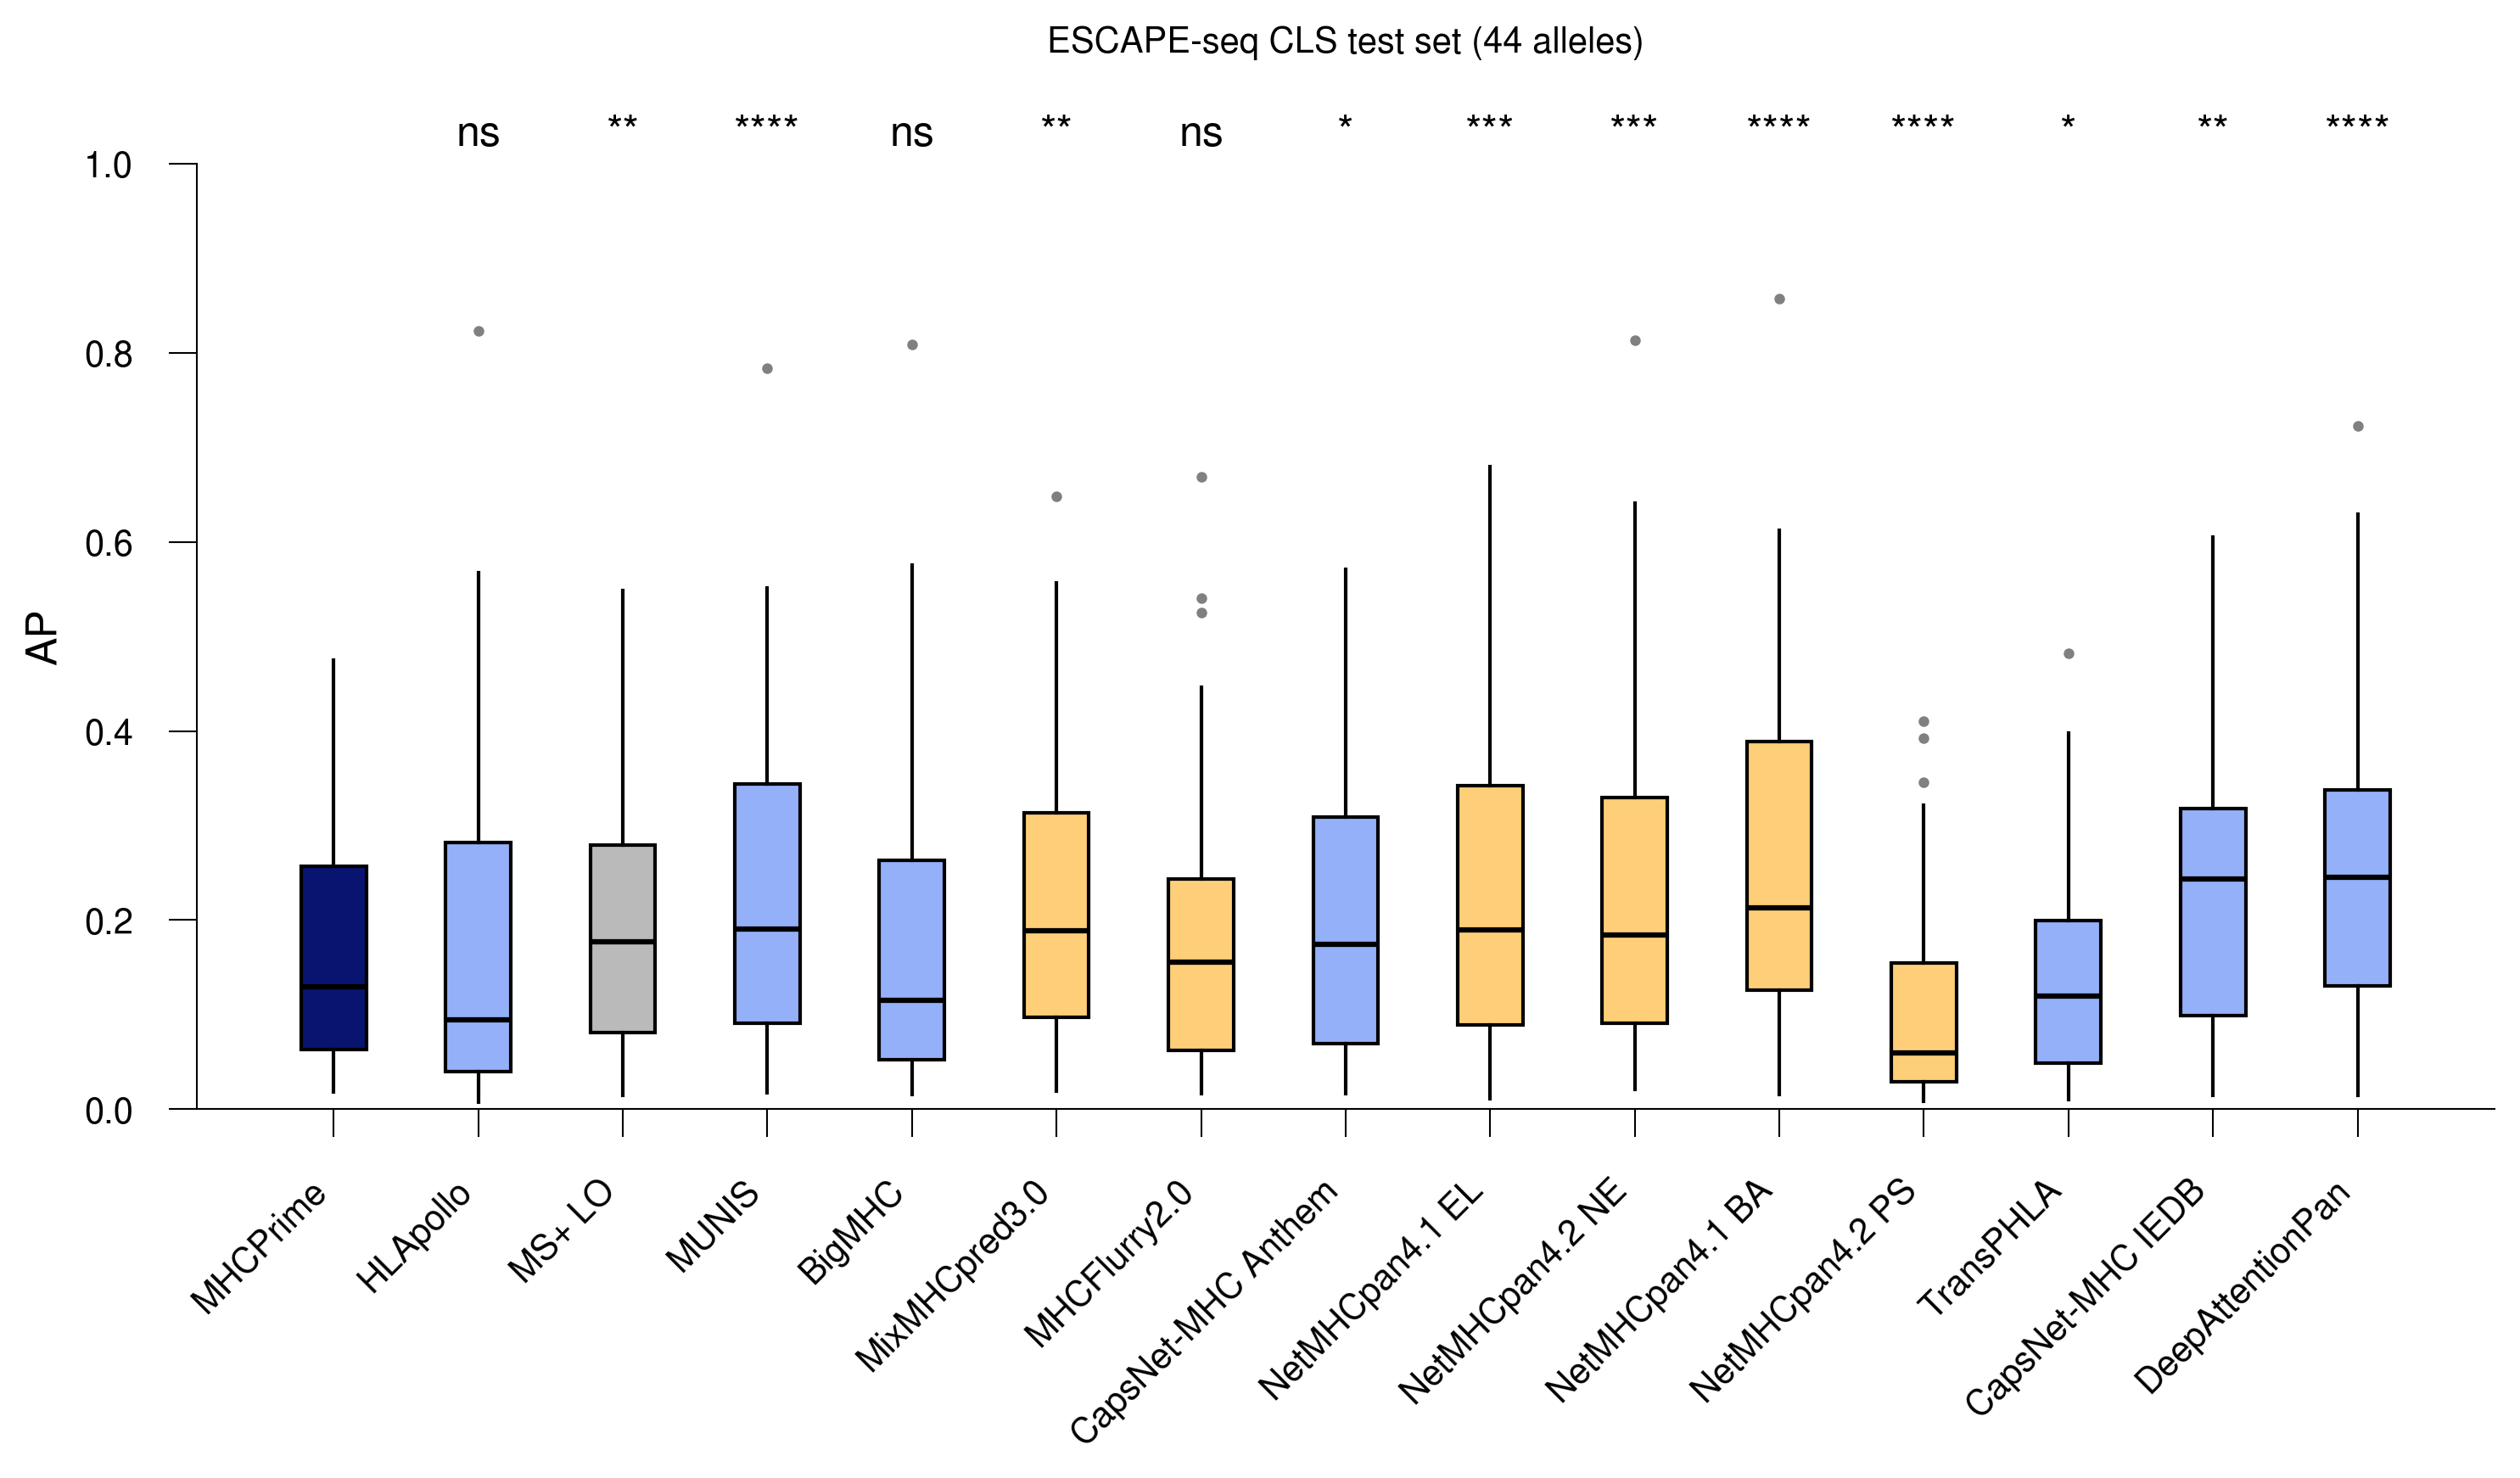

In [ ]:
# ms performance boxplots
def replace_boxplot_df(boxplot_groups, new_df):
    return {
        label: [(new_df, col) for _, col in pairs]
        for label, pairs in boxplot_groups.items()
    }

boxplot_groups={
    "MHCPrime": [(holec_allele_ap_matrix, 'mhcprime')],
    "HLApollo": [(holec_allele_ap_matrix, 'mhc_pred_0')],
    "MS+ LO": [(holec_allele_ap_matrix, 'ms_log_odds')],
    "MUNIS": [(holec_allele_ap_matrix, 'munis')],
    "BigMHC": [(holec_allele_ap_matrix, 'bigmhc')],
    "MixMHCpred3.0": [(holec_allele_ap_matrix, 'score')],
    "MHCFlurry2.0": [(holec_allele_ap_matrix, 'presentation_score')],
    "CapsNet-MHC Anthem": [(holec_allele_ap_matrix, 'capsnetmhc_anthem')],
    "NetMHCpan4.1 EL": [(holec_allele_ap_matrix, 'EL_score')],
    "NetMHCpan4.2 NE": [(holec_allele_ap_matrix, 'Neo_score_nmp42')],
    "NetMHCpan4.1 BA": [(holec_allele_ap_matrix, 'BA_score')],
    "NetMHCpan4.2 PS": [(holec_allele_ap_matrix, 'Pathogen_score_nmp42')],
    "TransPHLA": [(holec_allele_ap_matrix, 'transphla')],
    "CapsNet-MHC IEDB": [(holec_allele_ap_matrix, 'capsnetmhc_iedb')],
    "DeepAttentionPan": [(holec_allele_ap_matrix, 'deepattentionpan')],
}


transformer_based_color="#94B0F8"
nn_based_color="#ffce78"
lo_color="#bababa"
colors={
    "mhcprime": "#081470",
    "mhc_pred_0": transformer_based_color,
    "ms_log_odds": lo_color,
    "presentation_score":nn_based_color, 
    "score":nn_based_color, 
    "EL_score": nn_based_color,
    "BA_score": nn_based_color,
    "munis": transformer_based_color, 
    "transphla": transformer_based_color,
    "bigmhc": transformer_based_color, 
    "deepattentionpan": transformer_based_color,
    "Pathogen_score_nmp42":nn_based_color, 
    "Neo_score_nmp42":nn_based_color, 
    "capsnetmhc_anthem": transformer_based_color,
    "capsnetmhc_iedb": transformer_based_color, 
}

plot_params = {
    'title': '',
    'title_fontsize': 10,
    'title_bold': False,
    'xlabel': '',
    'ylabel': 'AP',
    'xlabel_fontsize': 12,
    'ylabel_fontsize': 12,
    'figsize': (10, 6),
    'dpi': 300,
    'legend_fontsize': 12,
    'legend_cols': 5,
    'legend_handle_size': 0.9,
    'marker_size': 3,
    'axis_linewidth': 0.5,
    'tick_length': 8.0,
    'xlabel_pad': 5.0,
    'ylabel_pad': 5.0,
    'xtick_labelsize': 10,
    'ytick_labelsize': 10,
    'xtick_rotation': 45,
    'title_y': 1.1,
    'title_pad': 5,

}

plotting_params=dict(
    colors=colors,
    legend=None,
    plot_params=plot_params,
    grid_alpha=0.0,
    default_font='Nimbus Sans',
    box_width=0.1,
    group_spacing=0.1,
    box_spacing=0.05,
    box_outline_color='black',
    box_outline_width=1.0,
    box_flier_marker='o',
    box_flier_size=3,
    box_flier_color="#2B2B2B",
    box_flier_alpha=0.6,
    box_flier_edge_width=0,
    box_median_color='black',
    box_median_width=1.5,
    box_whisker_style='-',
    box_whisker_width=1.0,
    box_notch=False,
    box_patch_alpha=1.0,
    hline_y=None,
    hline_label=None,
    hline_color='gray',
    hline_width=1.0,
    hline_style='--',
    hline_text=None,
    hline_text_position='above',
    hline_text_color=None,
    hline_text_fontsize=10,
    hline_text_offset=0.01,
    hline_text_x_offset=0.05,
    hline_in_legend=True,
    reference_hlines=None,
    legend_mode=None,
    legend_loc='lower center',
    legend_bbox=None,
    legend_ncol=None,
    ylim=(0, 1.0),
    compute_pvalues=False,
    pvalue_test='wilcoxon', 
    cluster_col='louvain_id',
    # sort_by ="median",
    sort_ascending=False, 
    pval_df=None,
    pval_ref_col="mhcprime",
    pval_ref_stars_only=True,
    pval_format='stars',
    pval_fontsize=12,
    pval_color='black',
    pval_star_y=None,
    pval_star_y_frac=1.01,
    pval_star_text_offset=0.0,
)

plot_params["title"]="Yeast display test set (16 alleles)"
plotting_params["plot_params"]=plot_params
plotting_params["pval_df"]=holec_allele_ap_matrix_pval_df
boxplot_groups=replace_boxplot_df(boxplot_groups, holec_allele_ap_matrix)
_=plot_grouped_boxplots(
    groups=boxplot_groups,
    save_path=None,
    # save_path=f"{central_figure_dir}/suppfig4_a_yeast_display_baseline_allele_ap_performance_boxplots_per_model", 
    **plotting_params
)


plot_params["title"]="EpiScan R9 test set (4 alleles)"
plotting_params["plot_params"]=plot_params
plotting_params["pval_df"]=episcan_r9_allele_ap_matrix_pval_df
boxplot_groups=replace_boxplot_df(boxplot_groups, episcan_r9_allele_ap_matrix)
_=plot_grouped_boxplots(
    groups=boxplot_groups,
    save_path=None,
    # save_path=f"{central_figure_dir}/suppfig4_b_episcan_r9_baseline_allele_ap_performance_boxplots_per_model", 
    **plotting_params
)


plot_params["title"]="EpiScan RT test set (4 alleles)"
plotting_params["plot_params"]=plot_params
plotting_params["pval_df"]=episcan_rt_allele_ap_matrix_pval_df
boxplot_groups=replace_boxplot_df(boxplot_groups, episcan_rt_allele_ap_matrix)
_=plot_grouped_boxplots(
    groups=boxplot_groups,
    save_path=None,
    # save_path=f"{central_figure_dir}/suppfig4_c_episcan_rt_baseline_allele_ap_performance_boxplots_per_model", 
    **plotting_params
)

plot_params["title"]="BA CLS test set (71 alleles)"
plotting_params["plot_params"]=plot_params
plotting_params["pval_df"]=ba_cls_allele_ap_matrix_pval_df
boxplot_groups=replace_boxplot_df(boxplot_groups, ba_cls_allele_ap_matrix)
_=plot_grouped_boxplots(
    groups=boxplot_groups,
    save_path=None,
    # save_path=f"{central_figure_dir}/suppfig4_d_ba_cls_baseline_allele_ap_performance_boxplots_per_model", 
    **plotting_params
)

plot_params["title"]="ESCAPE-seq CLS test set (44 alleles)"
plotting_params["plot_params"]=plot_params
plotting_params["pval_df"]=escape_cls_allele_ap_matrix_pval_df
boxplot_groups=replace_boxplot_df(boxplot_groups, escape_cls_allele_ap_matrix)
_=plot_grouped_boxplots(
    groups=boxplot_groups,
    save_path=None,
    # save_path=f"{central_figure_dir}/suppfig4_e_escape_seq_cls_baseline_allele_ap_performance_boxplots_per_model", 
    **plotting_params
)


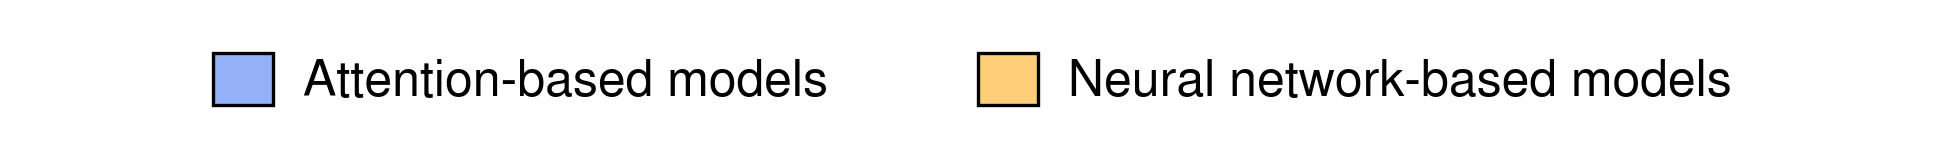

In [ ]:
# legend resized and formatted in illustrator
plot_horizontal_legend(
    legend_dict={
        'Attention-based models': '#94B0F8',
        'Neural network-based models': '#ffce78',
    },
    swatch_size=12,
    text_size=12,
    item_spacing=30,
    swatch_text_gap=6,
    swatch_outline_color='black',
    swatch_outline_width=0.8,
    figsize=None,
    dpi=300,
    default_font='Nimbus Sans',
    save_path=None,
    # save_path=f"{central_figure_dir}/suppfig4_legend",
)

In [ ]:
"""
Save dataframes associated with figures.
"""
save_dfs=False
# save_dfs=True

if save_dfs:
    holec_allele_ap_matrix.to_csv(f"{associated_data_dir}/suppfig4_a_holec_allele_ap_matrix.csv")
    holec_allele_ap_matrix_pval_df.to_csv(f"{associated_data_dir}/suppfig4_a_holec_allele_ap_matrix_pval_df.csv")

    episcan_r9_allele_ap_matrix.to_csv(f"{associated_data_dir}/suppfig4_b_episcan_r9_allele_ap_matrix.csv")
    episcan_r9_allele_ap_matrix_pval_df.to_csv(f"{associated_data_dir}/suppfig4_b_episcan_r9_allele_ap_matrix_pval_df.csv")

    episcan_rt_allele_ap_matrix.to_csv(f"{associated_data_dir}/suppfig4_c_episcan_rt_allele_ap_matrix.csv")
    episcan_rt_allele_ap_matrix_pval_df.to_csv(f"{associated_data_dir}/suppfig4_c_episcan_rt_allele_ap_matrix_pval_df.csv")

    ba_cls_allele_ap_matrix.to_csv(f"{associated_data_dir}/suppfig4_d_ba_cls_allele_ap_matrix.csv")
    ba_cls_allele_ap_matrix_pval_df.to_csv(f"{associated_data_dir}/suppfig4_d_ba_cls_allele_ap_matrix_pval_df.csv")

    escape_cls_allele_ap_matrix.to_csv(f"{associated_data_dir}/suppfig4_e_escape_cls_allele_ap_matrix.csv")
    escape_cls_allele_ap_matrix_pval_df.to_csv(f"{associated_data_dir}/suppfig4_e_escape_cls_allele_ap_matrix_pval_df.csv")


### Supplementary Figure 5: BA and ESCAPE-seq continuous test set model correlations

In [ ]:
%%time
# get the major collected dfs

# ba test sets
nmp_ba_data_hla_data_with_benchmarking_model_scores=pd.read_csv(f"{DATA_DIR}/Training_Datasets/Processed/BA/nmp_ba_data_hla_data_with_benchmarking_model_scores.csv", index_col=0)
ba_full_con_test_set=pd.read_csv(f"{DATA_DIR}/Training_Datasets/Processed/BA/ba_full_con_test_set.csv", index_col=0)

# escape seq test set
escape_seq_datasets_dir = DATA_DIR / "Training_Datasets/Processed/ESCAPE_seq"
escape_seq_full_con_test_set_with_benchmarking_model_scores=pd.read_csv(f"{escape_seq_datasets_dir}/escape_seq_full_con_test_set_with_benchmarking_model_scores.csv", index_col=0)

CPU times: user 933 ms, sys: 83.3 ms, total: 1.02 s
Wall time: 1.01 s


In [ ]:
%%time
# process all
ba_full_cls_test_set=full_process_data(ba_full_cls_test_set, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
ba_full_cls_test_set=create_seq_allele_column(ba_full_cls_test_set)

nmp_ba_data_hla_data_with_benchmarking_model_scores=full_process_data(nmp_ba_data_hla_data_with_benchmarking_model_scores, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
nmp_ba_data_hla_data_with_benchmarking_model_scores=create_seq_allele_column(nmp_ba_data_hla_data_with_benchmarking_model_scores)

escape_seq_full_con_test_set_with_benchmarking_model_scores=full_process_data(escape_seq_full_con_test_set_with_benchmarking_model_scores, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
escape_seq_full_con_test_set_with_benchmarking_model_scores=create_seq_allele_column(escape_seq_full_con_test_set_with_benchmarking_model_scores)

CPU times: user 521 ms, sys: 56.2 ms, total: 577 ms
Wall time: 575 ms


In [ ]:
# isolate ba set
ba_full_con_test_set_with_benchmarking_model_scores=nmp_ba_data_hla_data_with_benchmarking_model_scores[nmp_ba_data_hla_data_with_benchmarking_model_scores.seq_allele.isin(ba_full_con_test_set.seq_allele.tolist())].copy()
ba_full_con_test_set_with_benchmarking_model_scores=create_seq_allele_column(ba_full_con_test_set_with_benchmarking_model_scores)
seq_allele_to_ba_value=dict(zip(ba_full_con_test_set.seq_allele, ba_full_con_test_set.ba_value))
ba_full_con_test_set_with_benchmarking_model_scores["ba_value"]=ba_full_con_test_set_with_benchmarking_model_scores.seq_allele.map(seq_allele_to_ba_value)
print_data_stats(ba_full_con_test_set_with_benchmarking_model_scores)


Total: 79,578
Pos: 39,789 | 50.00%
Neg: 39,789 | 50.00%
N alleles: 76


In [ ]:
%%time
# compute metrics
score_cols=["mhcprime", "mhc_pred_0", "ms_log_odds", "score", "presentation_score", "EL_score", "BA_score", "munis", "transphla", "bigmhc", "deepattentionpan", "Pathogen_score_nmp42", "Neo_score_nmp42", "capsnetmhc_anthem", "capsnetmhc_iedb"]

ba_con_allele_spearman_matrix=compute_spearman_matrix_optimized(ba_full_con_test_set_with_benchmarking_model_scores, score_cols, "ba_value", allele_col='allele', return_float64=True, disable_tqdm=False)

escape_con_allele_spearman_matrix=compute_spearman_matrix_optimized(escape_seq_full_con_test_set_with_benchmarking_model_scores, score_cols, "escore", allele_col='allele', return_float64=True, disable_tqdm=False)

100%|██████████| 44/44 [00:00<00:00, 74.21it/s]

CPU times: user 2.26 s, sys: 31.4 ms, total: 2.29 s
Wall time: 2.28 s


In [ ]:
# p-values
print("BA")
ba_con_allele_spearman_matrix_pval_df=compute_pairwise_pvalues_general(ba_con_allele_spearman_matrix[score_cols])
display(ba_con_allele_spearman_matrix_pval_df)
display(pval_to_stars(ba_con_allele_spearman_matrix_pval_df))

print("ESCAPE-seq")
escape_con_allele_spearman_matrix_pval_df=compute_pairwise_pvalues_general(escape_con_allele_spearman_matrix[score_cols])
display(escape_con_allele_spearman_matrix_pval_df)
display(pval_to_stars(escape_con_allele_spearman_matrix_pval_df))

BA


,mhcprime,mhc_pred_0,ms_log_odds,score,presentation_score,EL_score,BA_score,munis,transphla,bigmhc,deepattentionpan,Pathogen_score_nmp42,Neo_score_nmp42,capsnetmhc_anthem,capsnetmhc_iedb
mhcprime,1.000000e+00,2.300674e-03,3.105002e-09,3.558663e-09,1.899274e-10,1.881877e-13,1.658752e-13,2.451767e-10,NaN,1.084667e-05,1.962612e-13,8.928644e-01,1.730075e-13,1.281155e-10,2.523542e-13
mhc_pred_0,2.300674e-03,1.000000e+00,2.444698e-10,3.173239e-11,4.387696e-13,1.132500e-13,1.132500e-13,1.063074e-12,NaN,6.423239e-07,1.393358e-13,1.701755e-01,1.132500e-13,5.929526e-11,1.336853e-13
ms_log_odds,3.105002e-09,2.444698e-10,1.000000e+00,3.273861e-04,2.478885e-02,5.328865e-13,1.962612e-13,4.487033e-01,NaN,1.297326e-01,2.860336e-13,1.419423e-02,2.743437e-13,6.202547e-05,3.827322e-13
score,3.558663e-09,3.173239e-11,3.273861e-04,1.000000e+00,8.223934e-01,4.334093e-13,1.658752e-13,1.048506e-01,NaN,1.157421e-03,3.241175e-13,3.820215e-04,1.310643e-12,3.951007e-02,5.786757e-13
presentation_score,1.899274e-10,4.387696e-13,2.478885e-02,8.223934e-01,1.000000e+00,2.420182e-13,1.658752e-13,4.255321e-01,NaN,2.941513e-03,2.523542e-13,9.614225e-05,3.415997e-13,5.545394e-03,3.378865e-13
EL_score,1.881877e-13,1.132500e-13,5.328865e-13,4.334093e-13,2.420182e-13,1.000000e+00,3.578822e-12,2.982124e-13,NaN,6.821424e-13,2.198034e-10,3.241175e-13,7.754720e-04,1.903655e-10,1.790719e-09
BA_score,1.658752e-13,1.132500e-13,1.962612e-13,1.658752e-13,1.658752e-13,3.578822e-12,1.000000e+00,1.658752e-13,NaN,2.225784e-13,9.080255e-04,1.730075e-13,3.109001e-13,1.282601e-13,5.333516e-01
munis,2.451767e-10,1.063074e-12,4.487033e-01,1.048506e-01,4.255321e-01,2.982124e-13,1.658752e-13,1.000000e+00,NaN,9.442162e-03,3.378865e-13,6.585027e-04,2.982124e-13,2.474809e-03,5.786757e-13
transphla,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN
bigmhc,1.084667e-05,6.423239e-07,1.297326e-01,1.157421e-03,2.941513e-03,6.821424e-13,2.225784e-13,9.442162e-03,NaN,1.000000e+00,3.522295e-13,8.192489e-02,2.982124e-13,3.174735e-06,4.517232e-13


,mhcprime,mhc_pred_0,ms_log_odds,score,presentation_score,EL_score,BA_score,munis,transphla,bigmhc,deepattentionpan,Pathogen_score_nmp42,Neo_score_nmp42,capsnetmhc_anthem,capsnetmhc_iedb
mhcprime,ns,**,****,****,****,****,****,****,,****,****,ns,****,****,****
mhc_pred_0,**,ns,****,****,****,****,****,****,,****,****,ns,****,****,****
ms_log_odds,****,****,ns,***,*,****,****,ns,,ns,****,*,****,****,****
score,****,****,***,ns,ns,****,****,ns,,**,****,***,****,*,****
presentation_score,****,****,*,ns,ns,****,****,ns,,**,****,****,****,**,****
EL_score,****,****,****,****,****,ns,****,****,,****,****,****,***,****,****
BA_score,****,****,****,****,****,****,ns,****,,****,***,****,****,****,ns
munis,****,****,ns,ns,ns,****,****,ns,,**,****,***,****,**,****
transphla,,,,,,,,,ns,,,,,,
bigmhc,****,****,ns,**,**,****,****,**,,ns,****,ns,****,****,****


ESCAPE-seq


,mhcprime,mhc_pred_0,ms_log_odds,score,presentation_score,EL_score,BA_score,munis,transphla,bigmhc,deepattentionpan,Pathogen_score_nmp42,Neo_score_nmp42,capsnetmhc_anthem,capsnetmhc_iedb
mhcprime,1.000000e+00,3.743385e-02,2.273737e-13,5.684342e-13,2.213494e-08,2.876277e-11,5.684342e-13,1.136868e-13,5.444140e-07,1.136868e-13,2.842171e-12,3.483988e-03,7.958079e-13,1.000444e-11,7.958079e-12
mhc_pred_0,3.743385e-02,1.000000e+00,2.273737e-13,5.684342e-13,2.313527e-10,5.684342e-13,1.136868e-13,1.136868e-13,2.802381e-09,4.888534e-12,7.958079e-13,6.104291e-05,5.684342e-13,4.888534e-12,2.273737e-13
ms_log_odds,2.273737e-13,2.273737e-13,1.000000e+00,8.943107e-01,2.460354e-08,4.208290e-02,2.589805e-05,5.920338e-07,5.920338e-07,1.065027e-01,5.938544e-06,1.137799e-06,3.080854e-03,3.104485e-01,9.798667e-03
score,5.684342e-13,5.684342e-13,8.943107e-01,1.000000e+00,5.795869e-09,2.941160e-02,2.664530e-06,5.444140e-07,2.983274e-07,1.378448e-01,8.937627e-07,1.204412e-07,2.500525e-03,5.133655e-01,3.344688e-03
presentation_score,2.213494e-08,2.313527e-10,2.460354e-08,5.795869e-09,1.000000e+00,1.027729e-10,1.136868e-13,2.160050e-12,7.771068e-01,1.358492e-03,6.252776e-12,4.553778e-01,1.136868e-12,8.622010e-10,5.795869e-09
EL_score,2.876277e-11,5.684342e-13,4.208290e-02,2.941160e-02,1.027729e-10,1.000000e+00,4.888534e-12,1.909621e-07,3.872868e-07,4.210558e-01,9.887344e-10,9.716973e-05,3.872868e-07,6.781010e-03,3.585553e-06
BA_score,5.684342e-13,1.136868e-13,2.589805e-05,2.664530e-06,1.136868e-13,4.888534e-12,1.000000e+00,7.948862e-01,2.842171e-12,2.589805e-05,9.115527e-03,5.684342e-13,7.281813e-05,1.232007e-06,3.322051e-02
munis,1.136868e-13,1.136868e-13,5.920338e-07,5.444140e-07,2.160050e-12,1.909621e-07,7.948862e-01,1.000000e+00,2.842171e-12,1.333413e-06,1.144425e-01,1.685976e-10,3.032758e-02,1.420838e-03,6.231837e-01
transphla,5.444140e-07,2.802381e-09,5.920338e-07,2.983274e-07,7.771068e-01,3.872868e-07,2.842171e-12,2.842171e-12,1.000000e+00,3.127450e-05,1.685976e-10,5.592020e-01,3.652758e-10,1.916305e-09,1.977014e-10
bigmhc,1.136868e-13,4.888534e-12,1.065027e-01,1.378448e-01,1.358492e-03,4.210558e-01,2.589805e-05,1.333413e-06,3.127450e-05,1.000000e+00,4.461282e-06,3.344688e-03,3.080854e-03,8.474303e-03,2.019836e-03


,mhcprime,mhc_pred_0,ms_log_odds,score,presentation_score,EL_score,BA_score,munis,transphla,bigmhc,deepattentionpan,Pathogen_score_nmp42,Neo_score_nmp42,capsnetmhc_anthem,capsnetmhc_iedb
mhcprime,ns,*,****,****,****,****,****,****,****,****,****,**,****,****,****
mhc_pred_0,*,ns,****,****,****,****,****,****,****,****,****,****,****,****,****
ms_log_odds,****,****,ns,ns,****,*,****,****,****,ns,****,****,**,ns,**
score,****,****,ns,ns,****,*,****,****,****,ns,****,****,**,ns,**
presentation_score,****,****,****,****,ns,****,****,****,ns,**,****,ns,****,****,****
EL_score,****,****,*,*,****,ns,****,****,****,ns,****,****,****,**,****
BA_score,****,****,****,****,****,****,ns,ns,****,****,**,****,****,****,*
munis,****,****,****,****,****,****,ns,ns,****,****,ns,****,*,**,ns
transphla,****,****,****,****,ns,****,****,****,ns,****,****,ns,****,****,****
bigmhc,****,****,ns,ns,**,ns,****,****,****,ns,****,**,**,**,**


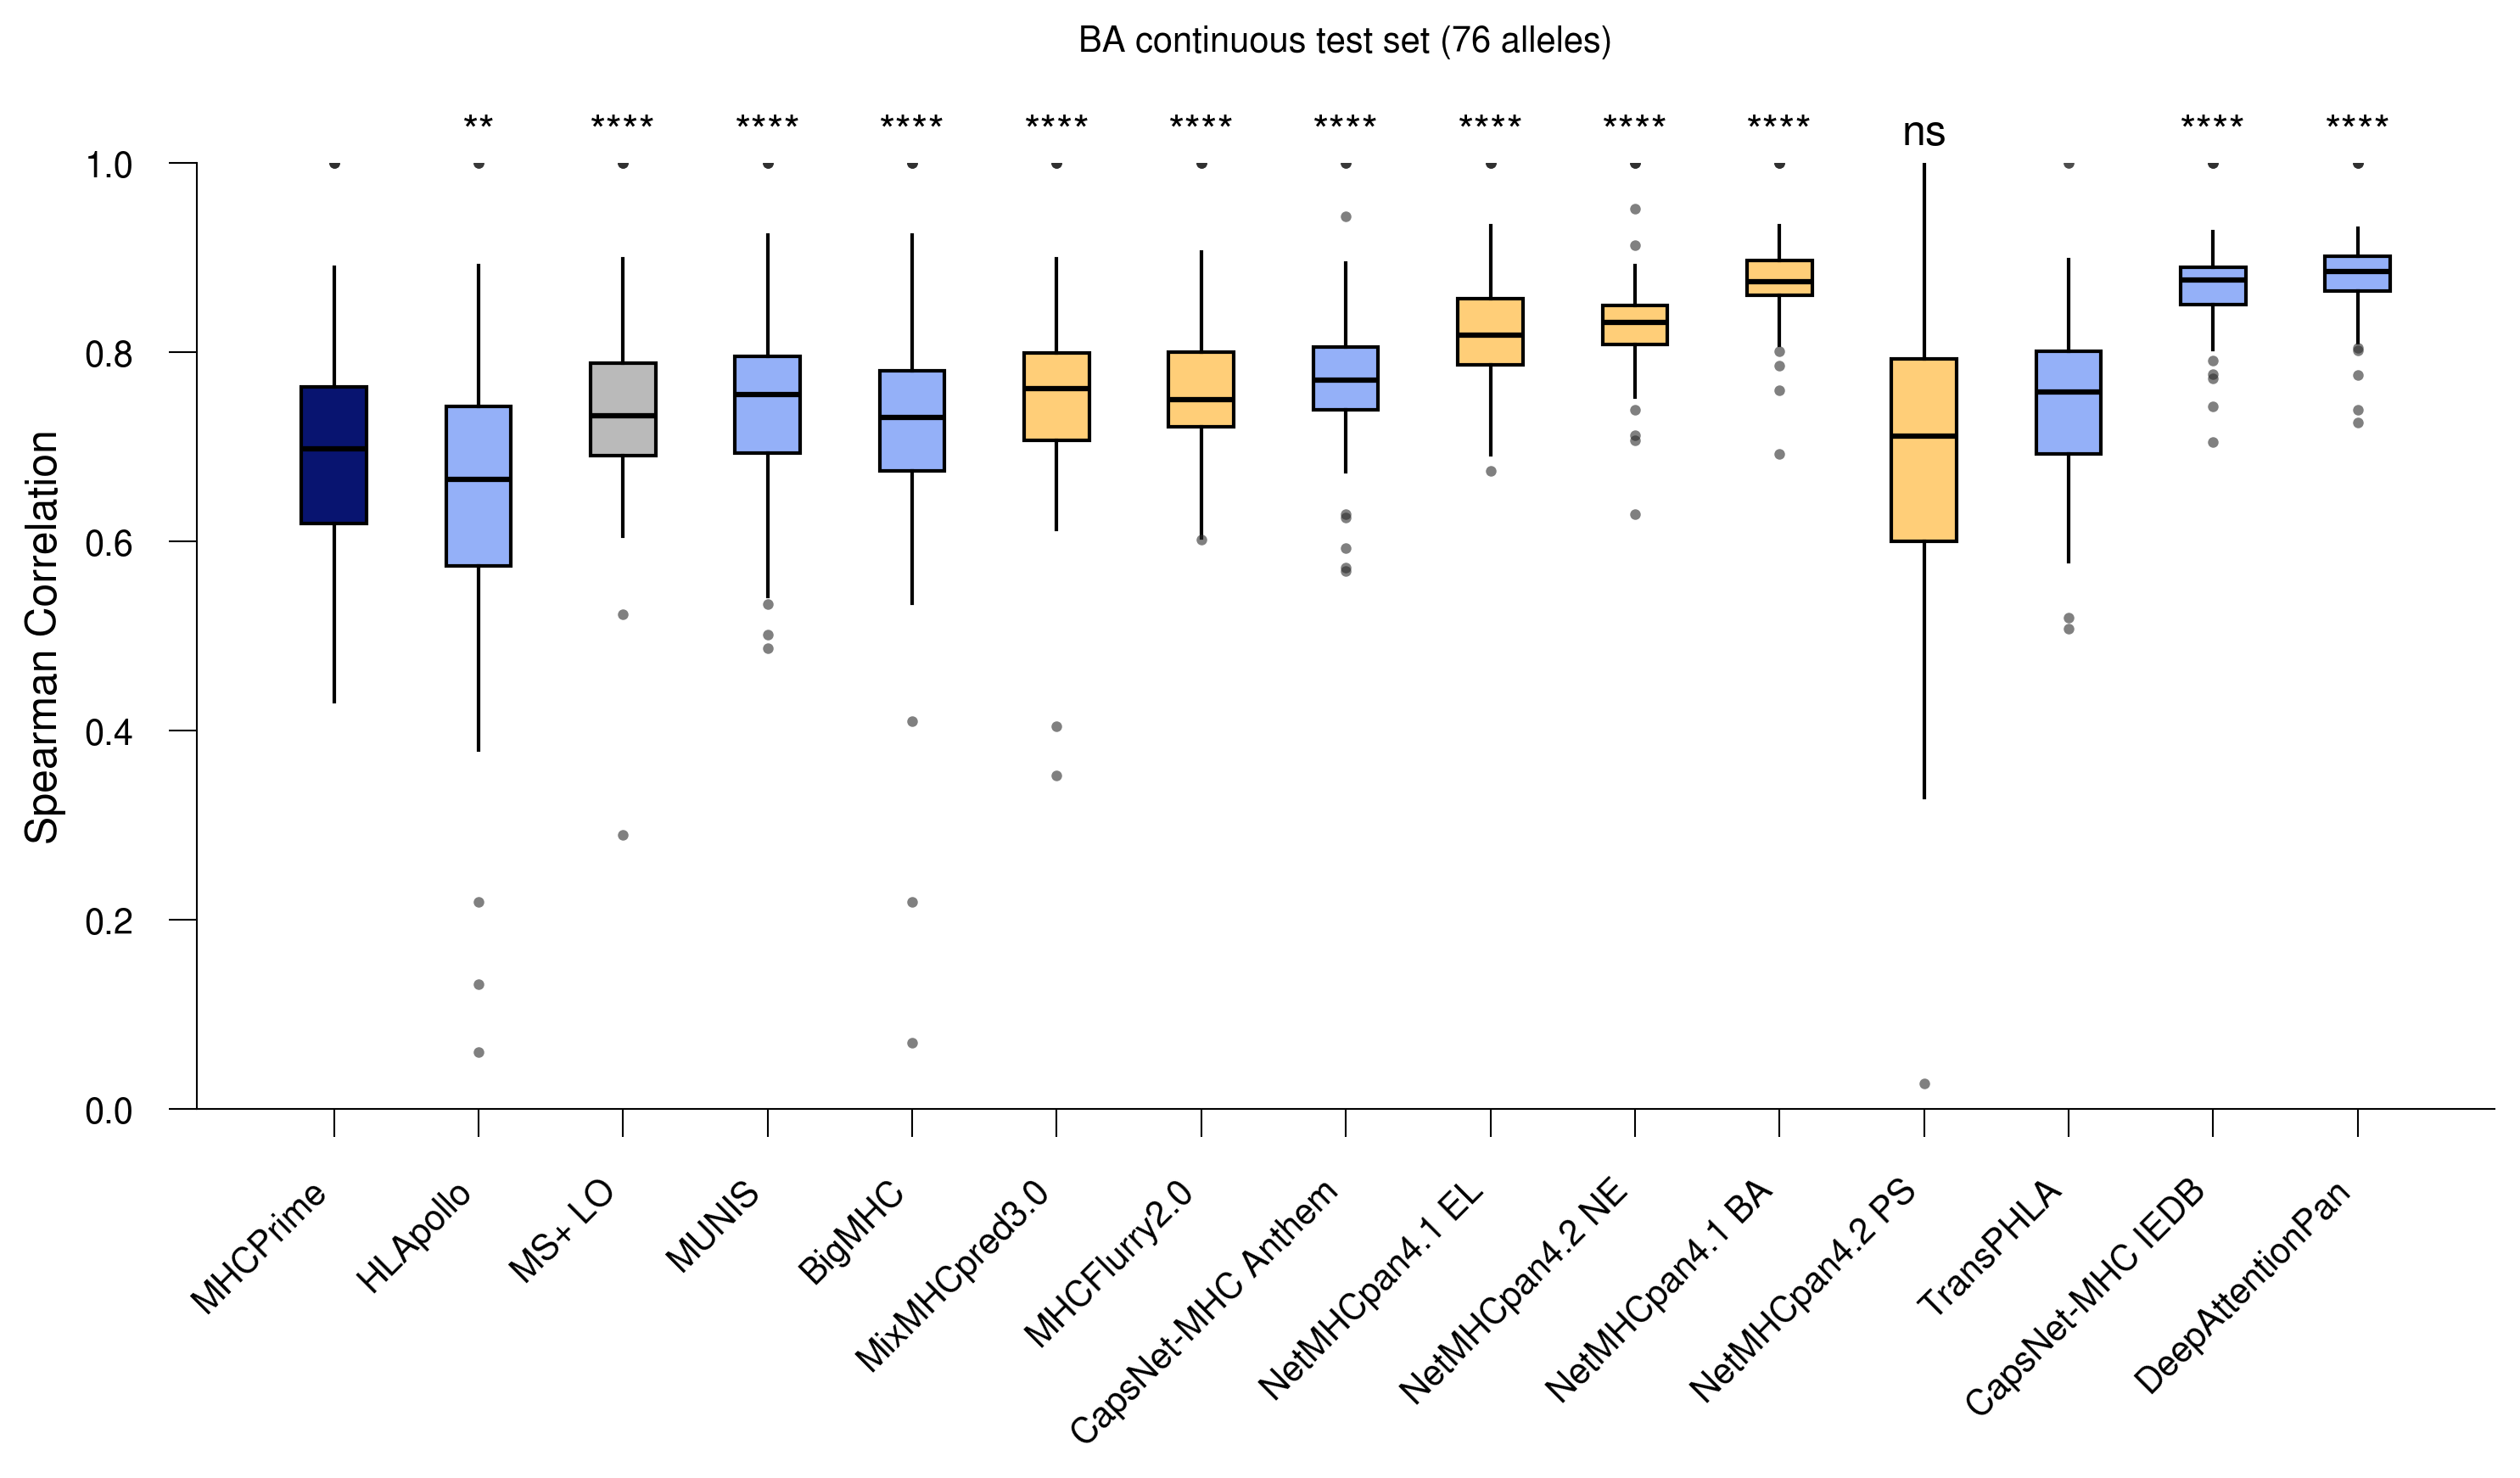

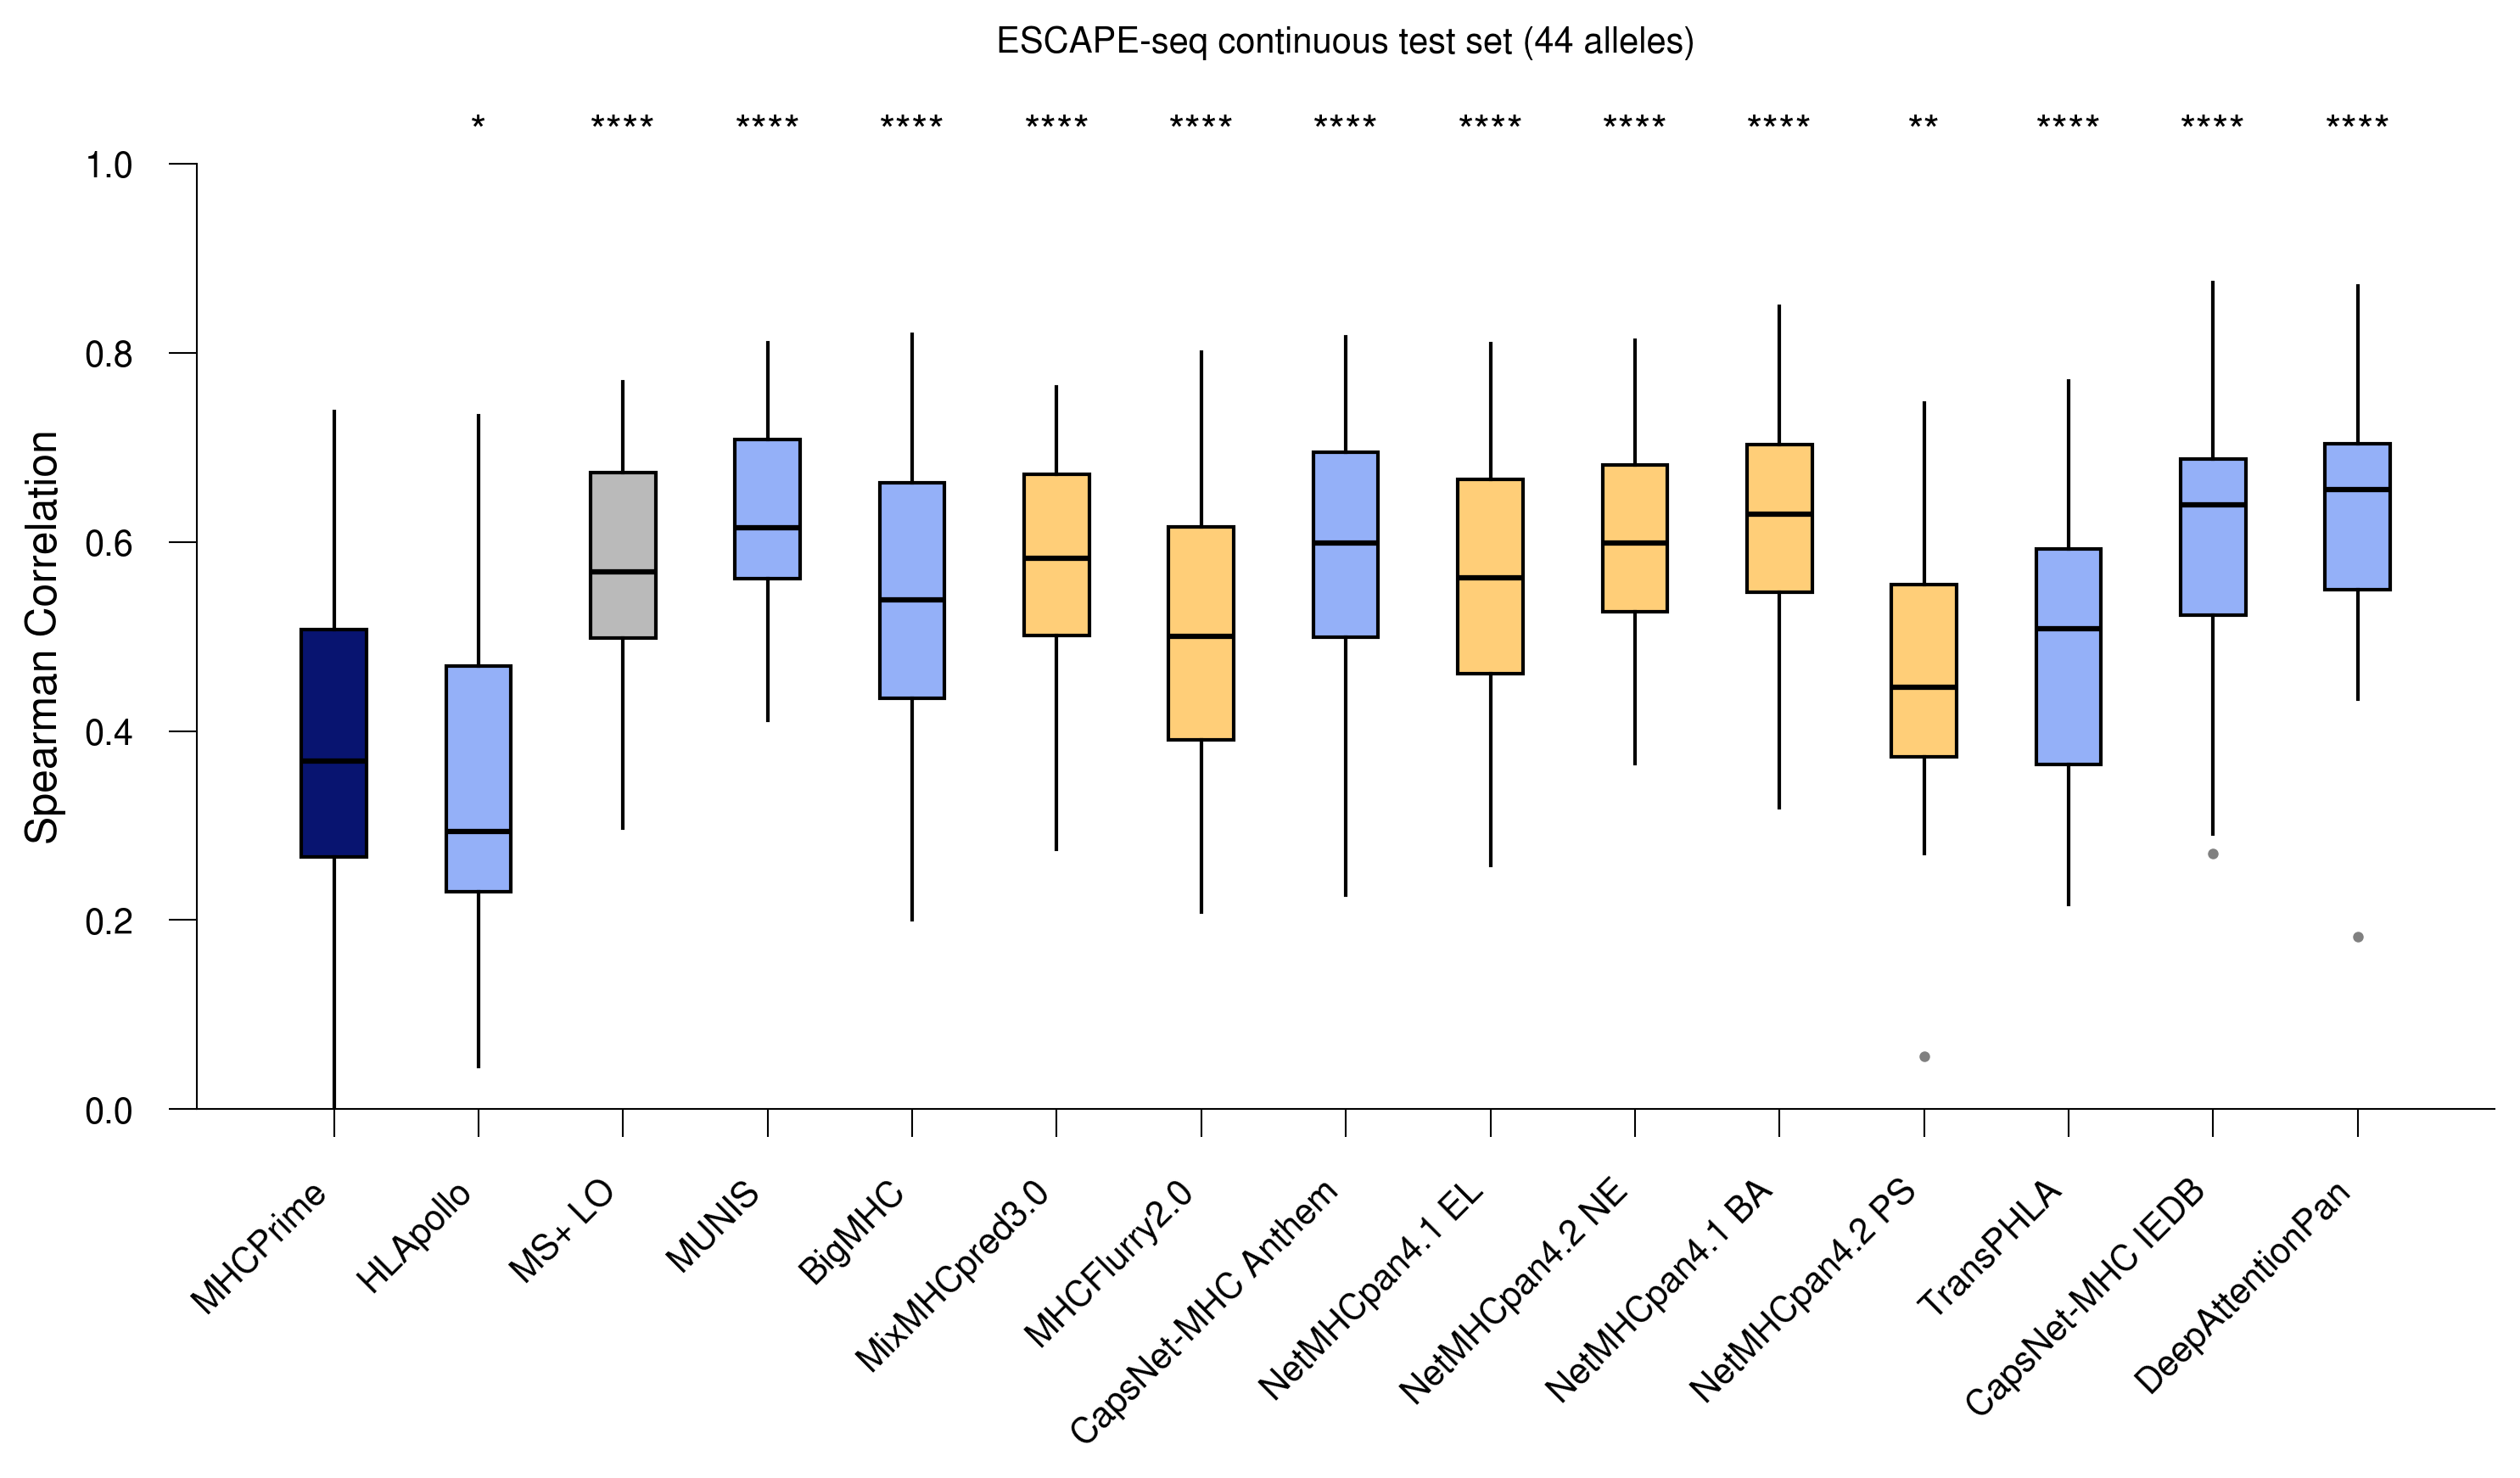

In [ ]:
# ms performance boxplots
def replace_boxplot_df(boxplot_groups, new_df):
    return {
        label: [(new_df, col) for _, col in pairs]
        for label, pairs in boxplot_groups.items()
    }

boxplot_groups={
    "MHCPrime": [(ba_con_allele_spearman_matrix, 'mhcprime')],
    "HLApollo": [(ba_con_allele_spearman_matrix, 'mhc_pred_0')],
    "MS+ LO": [(ba_con_allele_spearman_matrix, 'ms_log_odds')],
    "MUNIS": [(ba_con_allele_spearman_matrix, 'munis')],
    "BigMHC": [(ba_con_allele_spearman_matrix, 'bigmhc')],
    "MixMHCpred3.0": [(ba_con_allele_spearman_matrix, 'score')],
    "MHCFlurry2.0": [(ba_con_allele_spearman_matrix, 'presentation_score')],
    "CapsNet-MHC Anthem": [(ba_con_allele_spearman_matrix, 'capsnetmhc_anthem')],
    "NetMHCpan4.1 EL": [(ba_con_allele_spearman_matrix, 'EL_score')],
    "NetMHCpan4.2 NE": [(ba_con_allele_spearman_matrix, 'Neo_score_nmp42')],
    "NetMHCpan4.1 BA": [(ba_con_allele_spearman_matrix, 'BA_score')],
    "NetMHCpan4.2 PS": [(ba_con_allele_spearman_matrix, 'Pathogen_score_nmp42')],
    "TransPHLA": [(ba_con_allele_spearman_matrix, 'transphla')],
    "CapsNet-MHC IEDB": [(ba_con_allele_spearman_matrix, 'capsnetmhc_iedb')],
    "DeepAttentionPan": [(ba_con_allele_spearman_matrix, 'deepattentionpan')],
}


transformer_based_color="#94B0F8"
nn_based_color="#ffce78"
lo_color="#bababa"
colors={
    "mhcprime": "#081470",
    "mhc_pred_0": transformer_based_color,
    "ms_log_odds": lo_color,
    "presentation_score":nn_based_color, 
    "score":nn_based_color, 
    "EL_score": nn_based_color,
    "BA_score": nn_based_color,
    "munis": transformer_based_color, 
    "transphla": transformer_based_color,
    "bigmhc": transformer_based_color, 
    "deepattentionpan": transformer_based_color,
    "Pathogen_score_nmp42":nn_based_color, 
    "Neo_score_nmp42":nn_based_color, 
    "capsnetmhc_anthem": transformer_based_color,
    "capsnetmhc_iedb": transformer_based_color, 
}

plot_params = {
    'title': '',
    'title_fontsize': 10,
    'title_bold': False,
    'xlabel': '',
    'ylabel': 'Spearman Correlation',
    'xlabel_fontsize': 12,
    'ylabel_fontsize': 12,
    'figsize': (10, 6),
    'dpi': 300,
    'legend_fontsize': 12,
    'legend_cols': 5,
    'legend_handle_size': 0.9,
    'marker_size': 3,
    'axis_linewidth': 0.5,
    'tick_length': 8.0,
    'xlabel_pad': 5.0,
    'ylabel_pad': 5.0,
    'xtick_labelsize': 10,
    'ytick_labelsize': 10,
    'xtick_rotation': 45,
    'title_y': 1.1,
    'title_pad': 5,
}

plotting_params=dict(
    colors=colors,
    legend=None,
    plot_params=plot_params,
    grid_alpha=0.0,
    default_font='Nimbus Sans',
    box_width=0.1,
    group_spacing=0.1,
    box_spacing=0.05,
    box_outline_color='black',
    box_outline_width=1.0,
    box_flier_marker='o',
    box_flier_size=3,
    box_flier_color="#2B2B2B",
    box_flier_alpha=0.6,
    box_flier_edge_width=0,
    box_median_color='black',
    box_median_width=1.5,
    box_whisker_style='-',
    box_whisker_width=1.0,
    box_notch=False,
    box_patch_alpha=1.0,
    hline_y=None,
    hline_label=None,
    hline_color='gray',
    hline_width=1.0,
    hline_style='--',
    hline_text=None,
    hline_text_position='above',
    hline_text_color=None,
    hline_text_fontsize=10,
    hline_text_offset=0.01,
    hline_text_x_offset=0.05,
    hline_in_legend=True,
    reference_hlines=None,
    legend_mode=None,
    legend_loc='lower center',
    legend_bbox=None,
    legend_ncol=None,
    ylim=(0, 1.0),
    compute_pvalues=False,
    pvalue_test='wilcoxon', 
    cluster_col='louvain_id',
    # sort_by ="median",
    sort_ascending=False, 
    pval_df=None,
    pval_ref_col="mhcprime",
    pval_ref_stars_only=True,
    pval_format='stars',
    pval_fontsize=12,
    pval_color='black',
    pval_star_y=None,
    pval_star_y_frac=1.01,
    pval_star_text_offset=0.0,

)

plot_params["title"]="BA continuous test set (76 alleles)"
plotting_params["plot_params"]=plot_params
plotting_params["pval_df"]=ba_con_allele_spearman_matrix_pval_df
boxplot_groups=replace_boxplot_df(boxplot_groups, ba_con_allele_spearman_matrix)
_=plot_grouped_boxplots(
    groups=boxplot_groups,
    save_path=None,
    # save_path=f"{central_figure_dir}/suppfig5_a_ba_con_spearman_corr_per_allele_per_model", 
    **plotting_params
)


plot_params["title"]="ESCAPE-seq continuous test set (44 alleles)"
plotting_params["plot_params"]=plot_params
plotting_params["pval_df"]=escape_con_allele_spearman_matrix_pval_df
boxplot_groups=replace_boxplot_df(boxplot_groups, escape_con_allele_spearman_matrix)
_=plot_grouped_boxplots(
    groups=boxplot_groups,
    save_path=None,
    # save_path=f"{central_figure_dir}/suppfig5_b_escape_seq_con_spearman_corr_per_allele_per_model", 
    **plotting_params
)

In [ ]:
"""
Save dataframes associated with figures.
"""
save_dfs=False
# save_dfs=True

if save_dfs:
    ba_con_allele_spearman_matrix.to_csv(f"{associated_data_dir}/suppfig5_a_ba_con_allele_spearman_matrix.csv")
    ba_con_allele_spearman_matrix_pval_df.to_csv(f"{associated_data_dir}/suppfig5_a_ba_con_allele_spearman_matrix_pval_df.csv")

    escape_con_allele_spearman_matrix.to_csv(f"{associated_data_dir}/suppfig5_b_escape_con_allele_spearman_matrix.csv")
    escape_con_allele_spearman_matrix_pval_df.to_csv(f"{associated_data_dir}/suppfig5_b_escape_con_allele_spearman_matrix_pval_df.csv")

### Supplementary Figure 6: Synthetic MS cluster-specific performance

In [ ]:
# for general background cluster performances
allele_specific_clusters={
    'A0201': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16], 
    'A0301': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15], 
    'B2705': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13], 
    'B4002': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18], 
    'C0501': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15], 
    'C1202': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
}

cluster_specific_allele_ap_matrix_dict={}

for allele in allele_specific_clusters.keys():
    jt_df=pd.read_csv(f"{DATA_DIR}/Training_Datasets/Processed/MS_Train_Test_Sets/Cluster_Specific_Analysis/{allele}/cluster_specific_test_set.csv", index_col=0)

    score_cols=[f"mhcprime_holdout_{allele.lower()}_{str(lid)}" for lid in allele_specific_clusters[allele]]
    score_cols+=[f"mhcprime_holdout_{allele.lower()}_full", f"mhcprime_holdout_{allele.lower()}_null"]

    score_cols+=[f"model_ft_{allele.lower()}_{str(lid)}" for lid in allele_specific_clusters[allele]]
    score_cols+=[f"model_pepcl_{allele.lower()}_{str(lid)}_lambda_1eN4" for lid in allele_specific_clusters[allele]]

    # print(len(score_cols), score_cols)

    allele_ap_matrix=compute_ap_matrix_optimized(jt_df, score_cols, label_col='label', allele_col='louvain_id')
    allele_ap_matrix.index=allele_ap_matrix.index.astype(int)
    cluster_specific_allele_ap_matrix_dict[allele]=allele_ap_matrix


100%|██████████| 15/15 [00:00<00:00, 21.29it/s]


In [ ]:
# for hard negatives background cluster performances
allele_specific_clusters={
    'A0201': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16], 
    'A0301': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15], 
    'B2705': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13], 
    'B4002': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18], 
    'C0501': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15], 
    'C1202': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
}

cluster_specific_allele_ap_matrix_hard_negatives_dict={}

for allele in allele_specific_clusters.keys():
    jt_df=pd.read_csv(f"{DATA_DIR}/Training_Datasets/Processed/MS_Train_Test_Sets/Cluster_Specific_Analysis/{allele}/cluster_specific_test_set_hard_negatives.csv", index_col=0)

    score_cols=[f"mhcprime_holdout_{allele.lower()}_{str(lid)}" for lid in allele_specific_clusters[allele]]
    score_cols+=[f"mhcprime_holdout_{allele.lower()}_full", f"mhcprime_holdout_{allele.lower()}_null"]

    score_cols+=[f"model_ft_{allele.lower()}_{str(lid)}" for lid in allele_specific_clusters[allele]]
    score_cols+=[f"model_pepcl_{allele.lower()}_{str(lid)}_lambda_1eN4" for lid in allele_specific_clusters[allele]]

    # print(len(score_cols), score_cols)

    allele_ap_matrix=compute_ap_matrix_optimized(jt_df, score_cols, label_col='label', allele_col='louvain_id')
    allele_ap_matrix.index=allele_ap_matrix.index.astype(int)
    cluster_specific_allele_ap_matrix_hard_negatives_dict[allele]=allele_ap_matrix


100%|██████████| 15/15 [00:00<00:00, 20.71it/s]


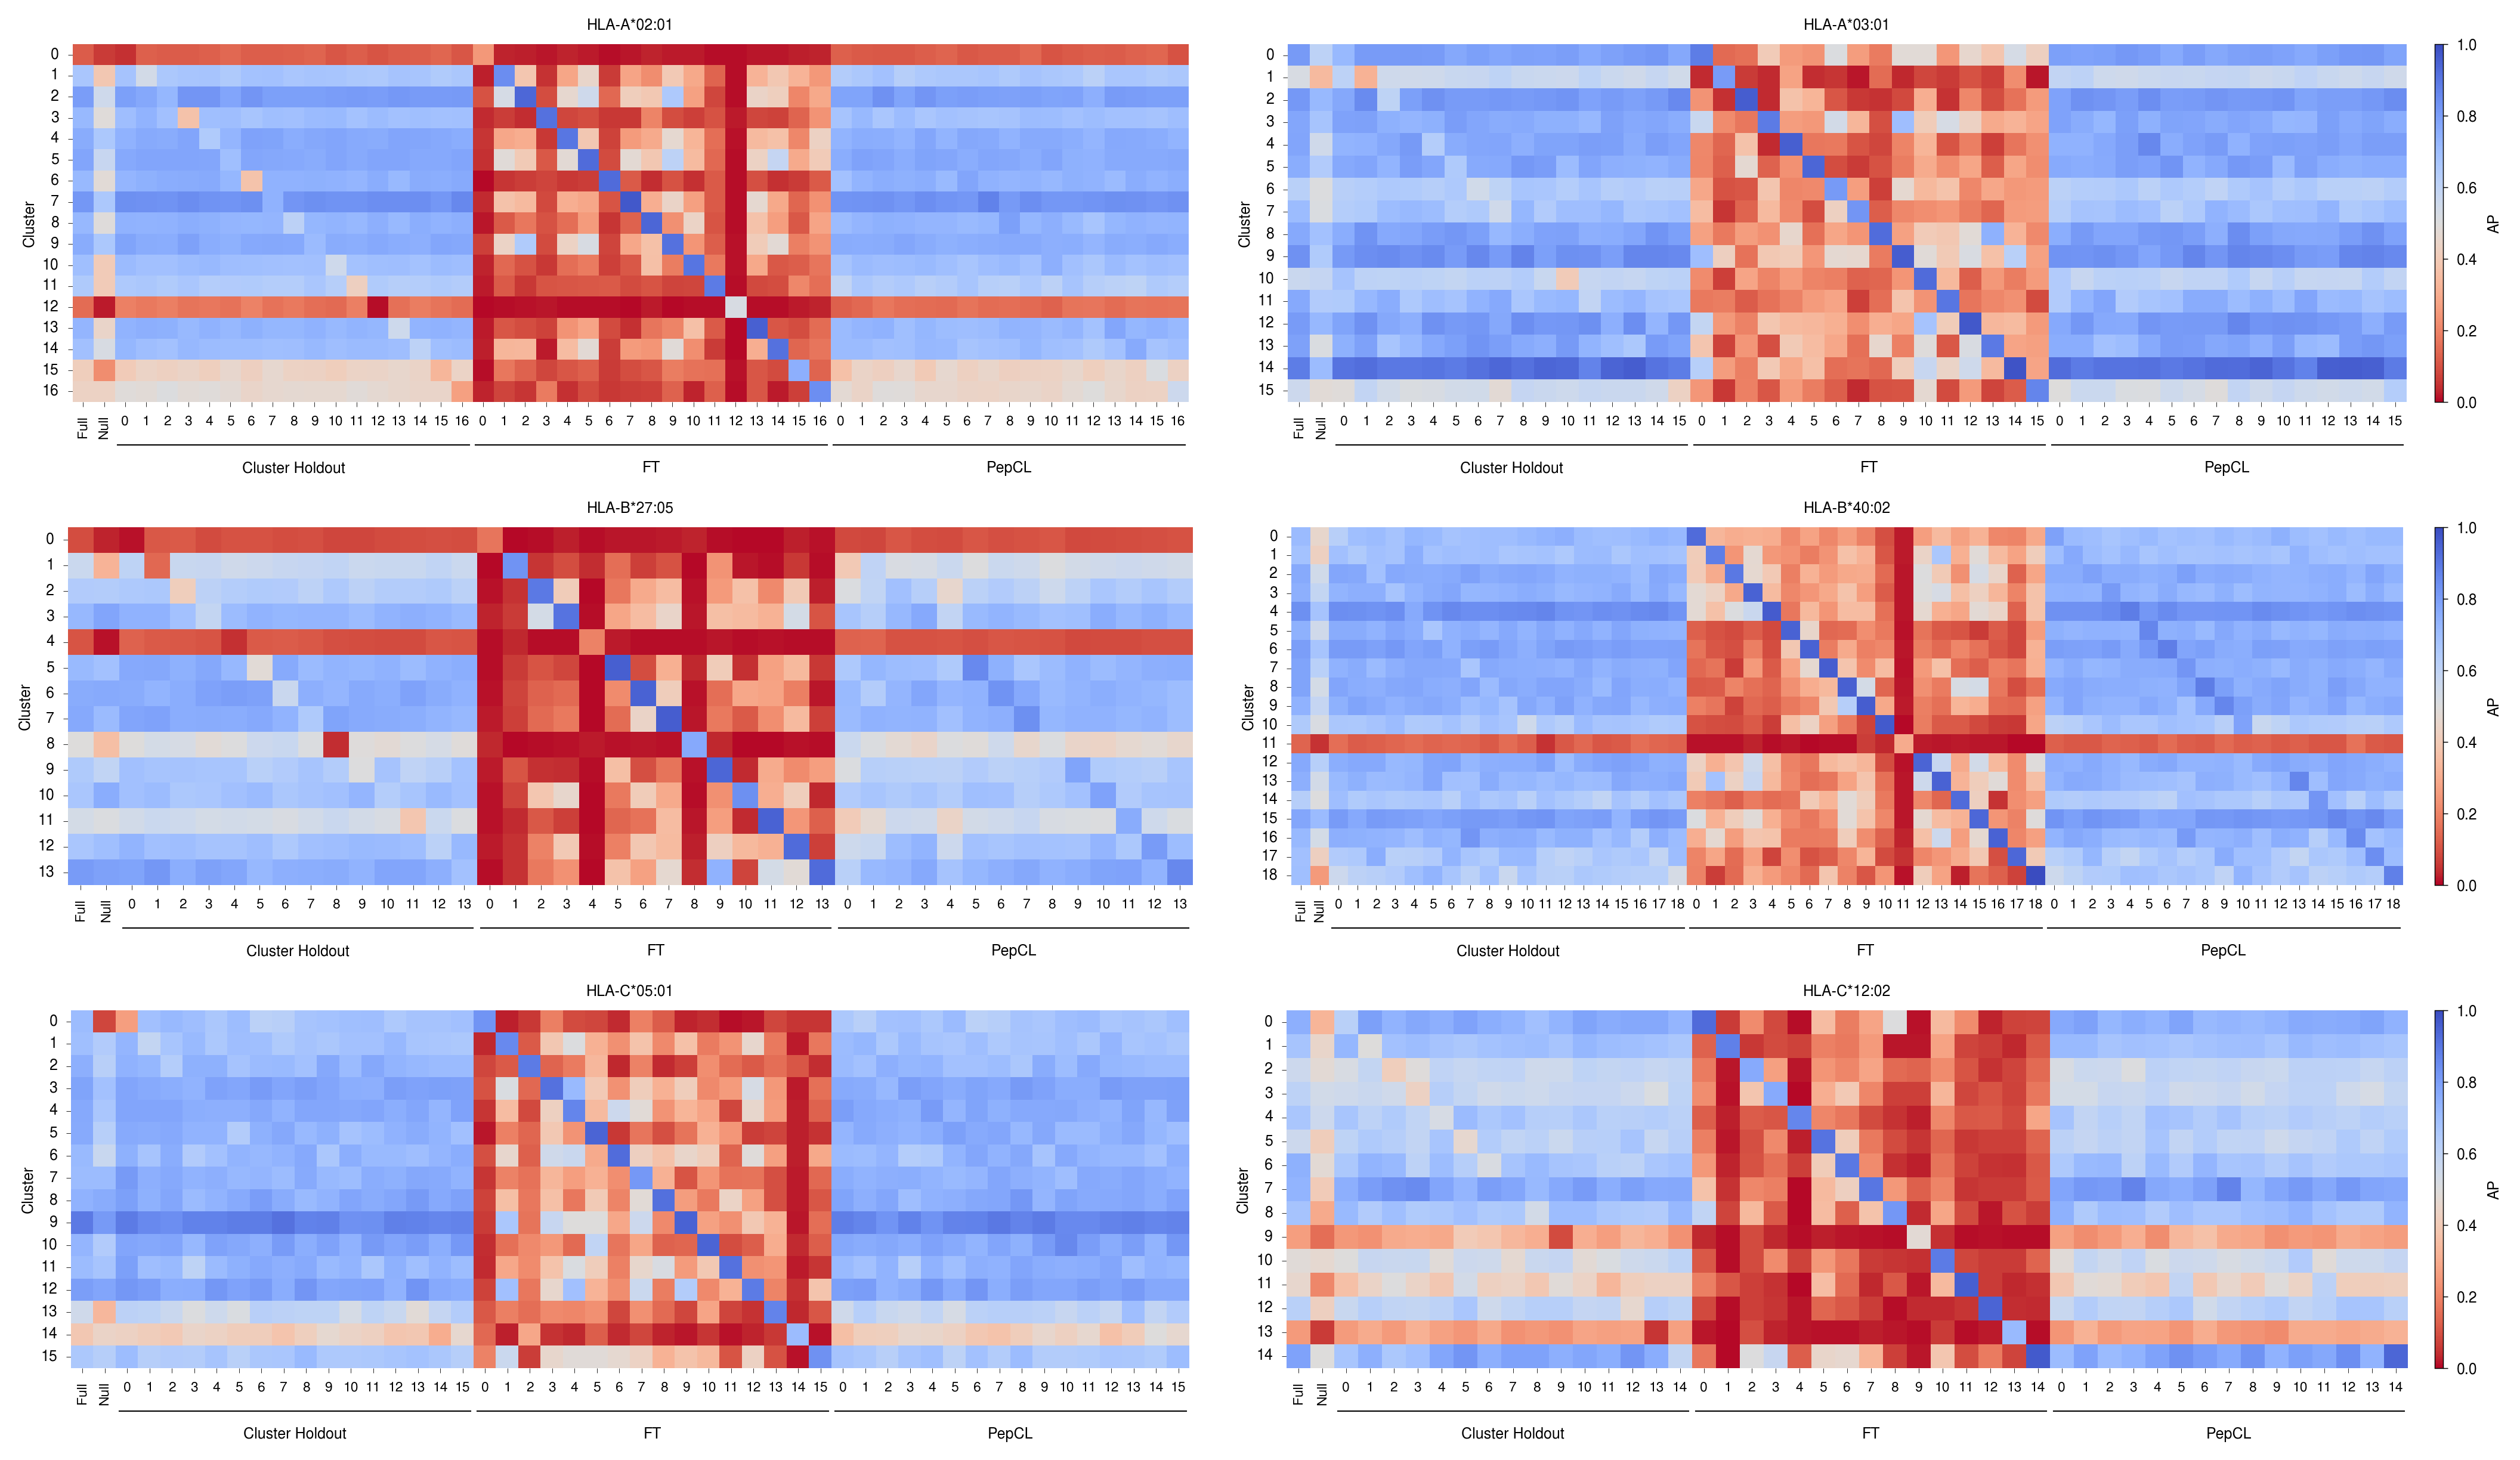

In [ ]:
# for general negative background
heatmap_kwargs = dict(
    aspect="equal",

    title_fontsize=6,
    title_bold=False,

    xtick_labelsize=5.5,
    ytick_labelsize=6,
    ylabel_fontsize=6,
    ylabel_pad=2,
    group_label_fontsize=6,

    full_null_xtick_rotation=90,
    full_null_xtick_ha="right",
    full_null_xtick_va="center",
    full_null_xtick_x_offset=-3.0,
    full_null_xtick_y_offset=0.0,

    cluster_xtick_rotation=0,
    cluster_xtick_ha="center",
    cluster_xtick_va="top",

    cell_outline_width=0.0,
    group_line_width=0.5,
    group_line_to_xtick_gap=0.12,
    group_label_to_line_gap=0.045,

    show_xticks=True,
    show_yticks=True,
    xtick_length=2,
    ytick_length=2,
    xtick_width=0.2,
    ytick_width=0.2,
)

fig, axes = plot_cluster_holdout_ap_heatmap_grid_manual(
    cluster_specific_allele_ap_matrix_dict,
    allele_specific_clusters=allele_specific_clusters,
    allele_order=["A0201", "A0301", "B2705", "B4002", "C0501", "C1202"],
    ncols=2,
    panel_width=6.45,
    panel_height=2.0,
    left_margin=0.45,
    right_margin=0.20,
    top_margin=0.25,
    bottom_margin=0.30,
    col_gap=0.35,
    row_gap=0.70,
    dpi=300,
    model_group_labels=["Cluster Holdout", "FT", "PepCL"],
    cmap="coolwarm_r",
    vmin=0,
    vmax=1,
    heatmap_kwargs=heatmap_kwargs,
    row_cbar=True,
    cbar_label="AP",
    cbar_label_fontsize=6,
    cbar_labelsize=6,
    cbar_tick_length=2.0,
    cbar_tick_width=0.35,
    cbar_outline_width=0.35,
    cbar_width=0.045,
    cbar_pad=0.06,
    cbar_height_frac=1.0,
    show=True,
    save_path=None,
    # save_path=f"{central_figure_dir}/suppfig6_a_cluster_specific_performance_general_negative_background", 
)

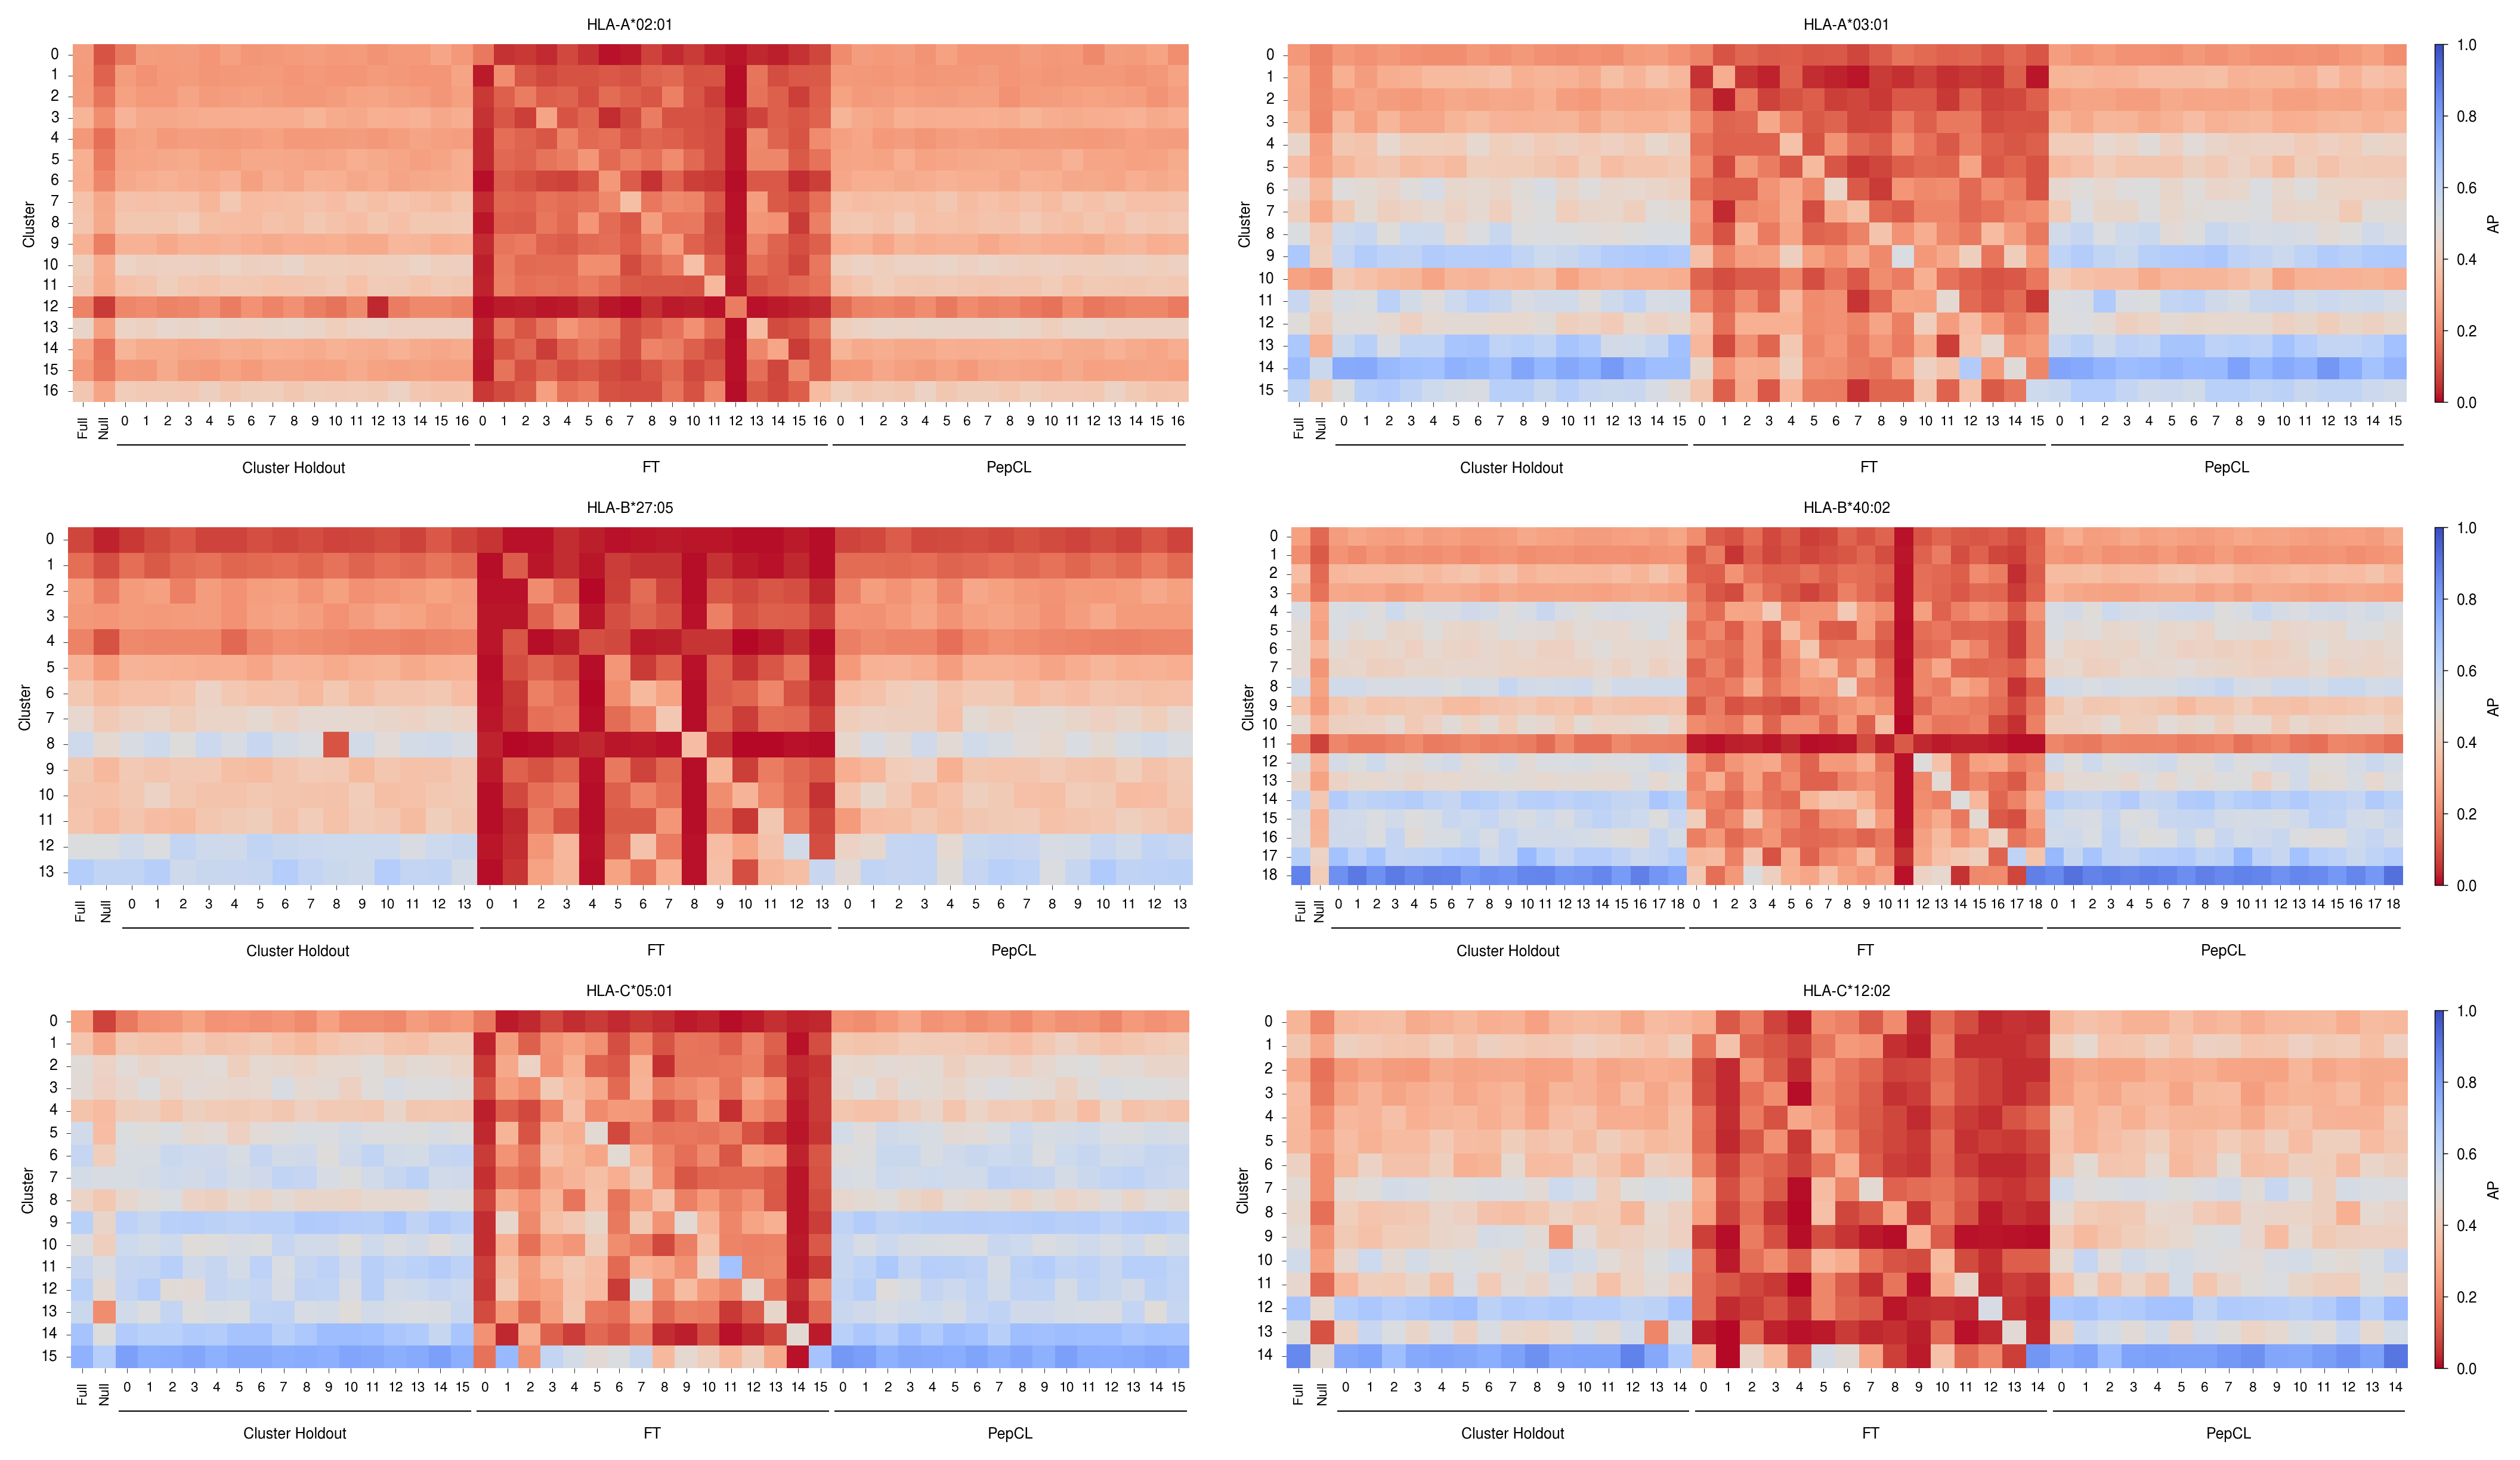

In [ ]:
# for hard negatives
fig, axes = plot_cluster_holdout_ap_heatmap_grid_manual(
    cluster_specific_allele_ap_matrix_hard_negatives_dict,
    allele_specific_clusters=allele_specific_clusters,
    allele_order=["A0201", "A0301", "B2705", "B4002", "C0501", "C1202"],
    ncols=2,
    panel_width=6.45,
    panel_height=2.0,
    left_margin=0.45,
    right_margin=0.20,
    top_margin=0.25,
    bottom_margin=0.30,
    col_gap=0.35,
    row_gap=0.70,
    dpi=300,
    model_group_labels=["Cluster Holdout", "FT", "PepCL"],
    cmap="coolwarm_r",
    vmin=0,
    vmax=1,
    heatmap_kwargs=heatmap_kwargs,
    row_cbar=True,
    cbar_label="AP",
    cbar_label_fontsize=6,
    cbar_labelsize=6,
    cbar_tick_length=2.0,
    cbar_tick_width=0.35,
    cbar_outline_width=0.35,
    cbar_width=0.045,
    cbar_pad=0.06,
    cbar_height_frac=1.0,
    show=True,
    save_path=None,
    # save_path=f"{central_figure_dir}/suppfig6_b_cluster_specific_performance_hard_negative_background", 
)

In [ ]:
"""
Save dataframes associated with figures.
"""
save_dfs=False
# save_dfs=True

if save_dfs:
    save_dict_pickle(cluster_specific_allele_ap_matrix_dict, f"{associated_data_dir}/suppfig6_a_cluster_specific_allele_ap_matrix_dict.pkl")
    save_dict_pickle(cluster_specific_allele_ap_matrix_hard_negatives_dict, f"{associated_data_dir}/suppfig6_b_cluster_specific_allele_ap_matrix_hard_negatives_dict.pkl")

### Supplementary Figure 7: MS pathogen set ranking and recovery

In [ ]:
# get the pathogen sets
pathogen_set_datasets_dir= DATA_DIR / "Training_Datasets" / "Processed" / "MS_Train_Test_Sets" / "Pathogen_Sets"
ms_cov_set=pd.read_csv(f"{pathogen_set_datasets_dir}/ms_cov_set.csv", index_col=0)
ms_zika_set=pd.read_csv(f"{pathogen_set_datasets_dir}/ms_zika_set.csv", index_col=0)
ms_mtb_set=pd.read_csv(f"{pathogen_set_datasets_dir}/ms_mtb_set.csv", index_col=0)

In [ ]:
%%time
# for ranking (gz extension)
chp_background_10k_per_allele_x_len_processed=pd.read_csv(f"{DATA_DIR}/chp_background_10k_per_allele_x_len_processed.csv.gz")

CPU times: user 38.6 s, sys: 6.17 s, total: 44.8 s
Wall time: 44.7 s


In [ ]:
%%time
# cov set
score_cols=["mhcprime", "holec_ft", "holec_pepcl"]

df_to_use=ms_cov_set.copy()
# donor_split_col="group"
    
df_to_use["all"]=1
donor_split_col="all"

above_threshold_df_cov=pd.DataFrame()
for score_col in score_cols:
    score_col+="_rank_r_chp"
    df_to_use_max_bg_chp=keep_max_score_per_id(df_to_use, score_col, "peptide_id")
    df_to_use_max_bg_chp_above_threshold=pct_above_threshold_per_subject_single(df_to_use_max_bg_chp, donor_split_col, score_col, threshold=98)
    above_threshold_df_cov=pd.concat([above_threshold_df_cov, df_to_use_max_bg_chp_above_threshold], axis = 1)

above_threshold_df_cov=above_threshold_df_cov.T.reset_index()
above_threshold_df_cov.columns=["model", "pct_recovery_above_2"]

CPU times: user 14.7 ms, sys: 3.85 ms, total: 18.6 ms
Wall time: 17.5 ms


In [ ]:
%%time
# zika set
score_cols=["mhcprime", "holec_ft", "holec_pepcl"]

df_to_use=ms_zika_set.copy()
# donor_split_col="group"
    
df_to_use["all"]=1
donor_split_col="all"

above_threshold_df_zika=pd.DataFrame()
for score_col in score_cols:
    score_col+="_rank_r_chp"
    df_to_use_max_bg_chp=keep_max_score_per_id(df_to_use, score_col, "peptide_id")
    df_to_use_max_bg_chp_above_threshold=pct_above_threshold_per_subject_single(df_to_use_max_bg_chp, donor_split_col, score_col, threshold=98)
    above_threshold_df_zika=pd.concat([above_threshold_df_zika, df_to_use_max_bg_chp_above_threshold], axis = 1)

above_threshold_df_zika=above_threshold_df_zika.T.reset_index()
above_threshold_df_zika.columns=["model", "pct_recovery_above_2"]

CPU times: user 18.5 ms, sys: 547 µs, total: 19 ms
Wall time: 17.9 ms


In [ ]:
%%time
# mtb set
score_cols=["mhcprime", "holec_ft", "holec_pepcl"]

df_to_use=ms_mtb_set.copy()
donor_split_col="group"
    
df_to_use["all"]=1
donor_split_col="all"

above_threshold_df_mtb=pd.DataFrame()
for score_col in score_cols:
    score_col+="_rank_r_chp"
    df_to_use_max_bg_chp=keep_max_score_per_id(df_to_use, score_col, "peptide_id")
    df_to_use_max_bg_chp_above_threshold=pct_above_threshold_per_subject_single(df_to_use_max_bg_chp, donor_split_col, score_col, threshold=98)
    above_threshold_df_mtb=pd.concat([above_threshold_df_mtb, df_to_use_max_bg_chp_above_threshold], axis = 1)

above_threshold_df_mtb=above_threshold_df_mtb.T.reset_index()
above_threshold_df_mtb.columns=["model", "pct_recovery_above_2"]

CPU times: user 19.9 ms, sys: 48 µs, total: 20 ms
Wall time: 18.4 ms


In [ ]:
# merged version
score_cols=["mhcprime", "holec_ft", "holec_pepcl"]
donor_split_col="all"
above_threshold_df_total=pd.DataFrame()
for score_col in score_cols:
    score_col+="_rank_r_chp"
    ms_cov_set_max_scored=keep_max_score_per_id(ms_cov_set, score_col, "peptide_id")
    ms_zika_set_max_scored=keep_max_score_per_id(ms_zika_set, score_col, "peptide_id")
    ms_mtb_set_max_scored=keep_max_score_per_id(ms_mtb_set, score_col, "peptide_id")
    ms_path_set_max_scored=pd.concat([ms_cov_set_max_scored, ms_zika_set_max_scored, ms_mtb_set_max_scored])
    ms_path_set_max_scored["all"]=1
    df_to_use_max_bg_chp=ms_path_set_max_scored.copy()
    df_to_use_max_bg_chp_above_threshold=pct_above_threshold_per_subject_single(df_to_use_max_bg_chp, donor_split_col, score_col, threshold=98)
    above_threshold_df_total=pd.concat([above_threshold_df_total, df_to_use_max_bg_chp_above_threshold], axis = 1)

above_threshold_df_total=above_threshold_df_total.T.reset_index()
above_threshold_df_total.columns=["model", "pct_recovery_above_2"]

In [ ]:
# get avg rank for ms pathogen set
score_cols=["mhcprime", "holec_ft", "holec_pepcl"]
rank_score_cols=[score_col+"_rank_r_chp" for score_col in score_cols]

ms_pathogen_set=merge_with_unique_peptide_ids([ms_cov_set, ms_zika_set, ms_mtb_set], "peptide_id")# to keep peptide ids unique
# ms_path_set_max_scored=pd.concat([ms_cov_set_max_scored, ms_zika_set_max_scored, ms_mtb_set_max_scored])
# ms_pathogen_set_avg_rank=pd.DataFrame(ms_path_set_max_scored[rank_score_cols].mean())
ms_pathogen_set_avg_rank=pd.DataFrame(ms_pathogen_set[rank_score_cols].mean())
ms_pathogen_set_avg_rank.reset_index(inplace=True)
ms_pathogen_set_avg_rank.columns=["model", "avg_rank"]

# ms_cov_set_avg_rank=pd.DataFrame(ms_cov_set_max_scored[rank_score_cols].mean())
ms_cov_set_avg_rank=pd.DataFrame(ms_cov_set[rank_score_cols].mean())
ms_cov_set_avg_rank.reset_index(inplace=True)
ms_cov_set_avg_rank.columns=["model", "avg_rank"]

# ms_zika_set_avg_rank=pd.DataFrame(ms_zika_set_max_scored[rank_score_cols].mean())
ms_zika_set_avg_rank=pd.DataFrame(ms_zika_set[rank_score_cols].mean())
ms_zika_set_avg_rank.reset_index(inplace=True)
ms_zika_set_avg_rank.columns=["model", "avg_rank"]

# ms_mtb_set_avg_rank=pd.DataFrame(ms_mtb_set_max_scored[rank_score_cols].mean())
ms_mtb_set_avg_rank=pd.DataFrame(ms_mtb_set[rank_score_cols].mean())
ms_mtb_set_avg_rank.reset_index(inplace=True)
ms_mtb_set_avg_rank.columns=["model", "avg_rank"]

In [ ]:
from src.plotting import *

{'MHCPrime': ['mhcprime_rank_r_chp'], 'FT': ['holec_ft_rank_r_chp'], 'PepCL': ['holec_pepcl_rank_r_chp']}


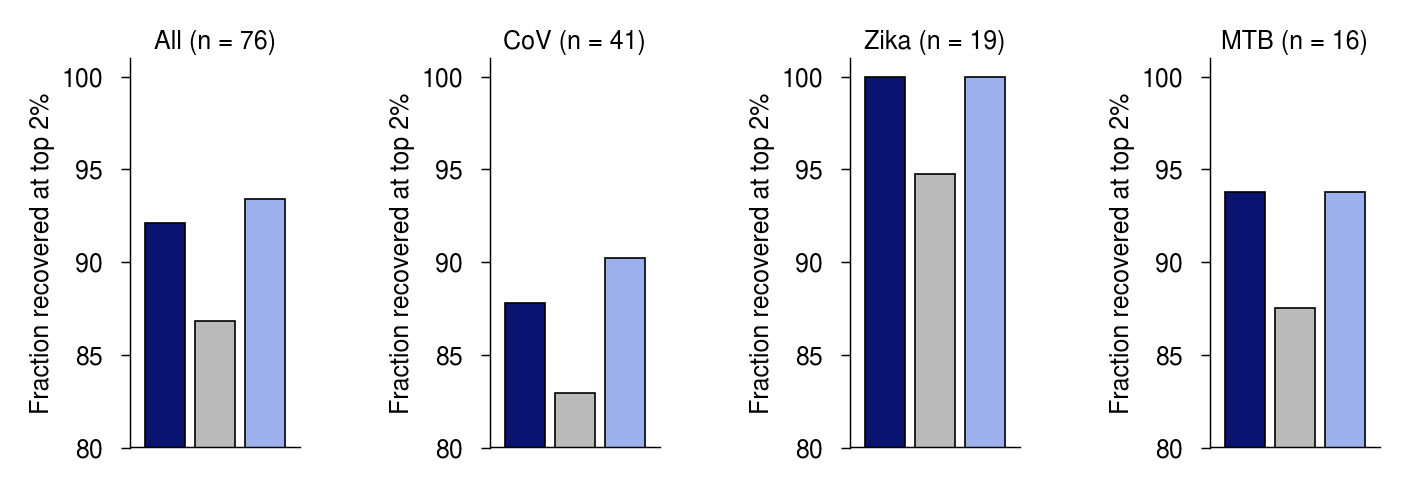

In [ ]:
"""
Plotting parameters for boxplots.
"""
score_cols=["mhcprime_rank_r_chp", "holec_ft_rank_r_chp", "holec_pepcl_rank_r_chp"]

model_groups = {
    "MHCPrime": ["mhcprime_rank_r_chp"],
    "FT": ["holec_ft_rank_r_chp"],
    "PepCL": ["holec_pepcl_rank_r_chp"],
}

x_ticks = ['']
print(model_groups)

colors = {
    'MHCPrime': '#081470',
    'FT': '#bababa',
    'PepCL': '#9bb0ed',
}

plot_params = {
    'title': '',
    'title_y': 1.04,
    'title_bbox': None,

    # 'title_fontsize': 7,
    'title_fontsize': 6,
    'title_bold': False,
    'xlabel': '',
    'ylabel': 'Fraction recovered at top 2%',
    # 'xlabel_fontsize': 7,
    # 'ylabel_fontsize': 7,
    'xlabel_fontsize': 6,
    'ylabel_fontsize': 6,
    'figsize': (1.20, 1.65),
    'dpi': 300,
    'legend_fontsize': 6,
    'legend_cols': 3,
    'legend_handle_size': 0.7,
    'axis_linewidth': 0.35,
    # 'axis_linewidth': 0.30,
    # 'axis_linewidth': 0.25,
    'tick_length': 2.2,
    'xlabel_pad': 1,
    'ylabel_pad': 1.5,
    'xtick_labelsize': 5.5,
    'ytick_labelsize': 6,
}

plotting_parameters = dict(
    model_col='model',
    score_col='pct_recovery_above_2',
    model_groups=model_groups,
    x_ticks=[''],
    colors=colors,
    plot_params=plot_params,
    ylim=(80.0, 101.0),
    grid_alpha=0,
    default_font='Nimbus Sans',
    mode='bar',
    bar_width=0.32,
    bar_spacing=0.08,
    group_spacing=0.10,
    x_margin=0.12,
    bar_outline_color='black',
    box_median_width=0.60,
    # bar_outline_width=0.35,
    # box_whisker_width=0.30,
    bar_outline_width=0.40,
    box_whisker_width=0.40,
    box_flier_size=0,
    legend_mode=None,
    xtick_rotation=0,
    pval_df=None,
    pval_fontsize=4,
    pval_linewidth=0.35,
    pval_color='black',
    pval_bar_offset=1.2,
    pval_bar_spacing=2.0,
    pval_text_offset=0.25,
    pval_star_text_offset=-0.35,
    pval_ns_text_offset=0.25,
    pval_merge_nonoverlapping=False
)

# plot all together
plot_dict = {

    'all': {
        'title': f'All (n = {ms_pathogen_set.peptide_id.nunique()})',
        'df': above_threshold_df_total,
    },
    'cov': {
        'title': f'CoV (n = {ms_cov_set.peptide_id.nunique()})',
        'df': above_threshold_df_cov,
    },
    'zika': {
        'title': f'Zika (n = {ms_zika_set.peptide_id.nunique()})',
        'df': above_threshold_df_zika,
    },
    'mtb': {
        'title': f'MTB (n = {ms_mtb_set.peptide_id.nunique()})',
        'df': above_threshold_df_mtb,
    },
    
}

fig, axes = plot_model_performance_box_grid_v2(
    plot_dict=plot_dict,
    save_path=None,
    # save_path=f"{central_figure_dir}/suppfig7_a_ms_pathogen_set_pct_recovered_barplots",
    panel_gap=0.00,
    grid_dpi=300,
    **plotting_parameters,
)


In [ ]:
rank_score_cols=["mhcprime_rank_r_chp", "holec_ft_rank_r_chp", "holec_pepcl_rank_r_chp"]

ms_pathogen_set_pval_df=compute_pairwise_pvalues_general(ms_pathogen_set[rank_score_cols])
display(ms_pathogen_set_pval_df)
display(pval_to_stars(ms_pathogen_set_pval_df))

ms_cov_set_pval_df=compute_pairwise_pvalues_general(ms_cov_set[rank_score_cols])
display(ms_cov_set_pval_df)
display(pval_to_stars(ms_cov_set_pval_df))

ms_zika_set_pval_df=compute_pairwise_pvalues_general(ms_zika_set[rank_score_cols])
display(ms_zika_set_pval_df)
display(pval_to_stars(ms_zika_set_pval_df))

ms_mtb_set_pval_df=compute_pairwise_pvalues_general(ms_mtb_set[rank_score_cols])
display(ms_mtb_set_pval_df)
display(pval_to_stars(ms_mtb_set_pval_df))

,mhcprime_rank_r_chp,holec_ft_rank_r_chp,holec_pepcl_rank_r_chp
mhcprime_rank_r_chp,1.000000e+00,7.876594e-12,3.152501e-01
holec_ft_rank_r_chp,7.876594e-12,1.000000e+00,2.329018e-26
holec_pepcl_rank_r_chp,3.152501e-01,2.329018e-26,1.000000e+00


,mhcprime_rank_r_chp,holec_ft_rank_r_chp,holec_pepcl_rank_r_chp
mhcprime_rank_r_chp,ns,****,ns
holec_ft_rank_r_chp,****,ns,****
holec_pepcl_rank_r_chp,ns,****,ns


,mhcprime_rank_r_chp,holec_ft_rank_r_chp,holec_pepcl_rank_r_chp
mhcprime_rank_r_chp,1.000000,2.701206e-04,1.556515e-02
holec_ft_rank_r_chp,0.000270,1.000000e+00,1.365165e-13
holec_pepcl_rank_r_chp,0.015565,1.365165e-13,1.000000e+00


,mhcprime_rank_r_chp,holec_ft_rank_r_chp,holec_pepcl_rank_r_chp
mhcprime_rank_r_chp,ns,***,*
holec_ft_rank_r_chp,***,ns,****
holec_pepcl_rank_r_chp,*,****,ns


,mhcprime_rank_r_chp,holec_ft_rank_r_chp,holec_pepcl_rank_r_chp
mhcprime_rank_r_chp,1.000000,0.429208,0.254227
holec_ft_rank_r_chp,0.429208,1.000000,0.005905
holec_pepcl_rank_r_chp,0.254227,0.005905,1.000000


,mhcprime_rank_r_chp,holec_ft_rank_r_chp,holec_pepcl_rank_r_chp
mhcprime_rank_r_chp,ns,ns,ns
holec_ft_rank_r_chp,ns,ns,**
holec_pepcl_rank_r_chp,ns,**,ns


,mhcprime_rank_r_chp,holec_ft_rank_r_chp,holec_pepcl_rank_r_chp
mhcprime_rank_r_chp,1.000000e+00,6.406609e-11,2.833653e-02
holec_ft_rank_r_chp,6.406609e-11,1.000000e+00,3.943346e-13
holec_pepcl_rank_r_chp,2.833653e-02,3.943346e-13,1.000000e+00


,mhcprime_rank_r_chp,holec_ft_rank_r_chp,holec_pepcl_rank_r_chp
mhcprime_rank_r_chp,ns,****,*
holec_ft_rank_r_chp,****,ns,****
holec_pepcl_rank_r_chp,*,****,ns


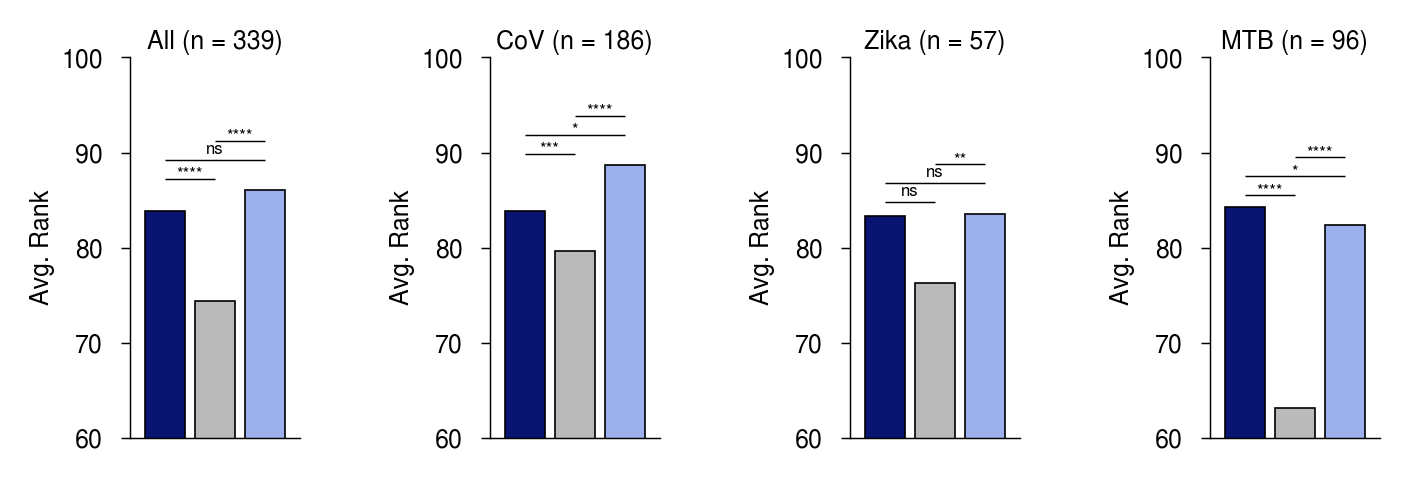

In [ ]:
# avg rank
plot_dict = {

    'all': {
        'title': f'All (n = {len(ms_pathogen_set)})',
        'df': ms_pathogen_set_avg_rank,
        'pval_df': ms_pathogen_set_pval_df,
    },
    'cov': {
        'title': f'CoV (n = {len(ms_cov_set)})',
        'df': ms_cov_set_avg_rank,
        'pval_df': ms_cov_set_pval_df,

    },
    'zika': {
        'title': f'Zika (n = {len(ms_zika_set)})',
        'df': ms_zika_set_avg_rank,
        'pval_df': ms_zika_set_pval_df,
    },
    'mtb': {
        'title': f'MTB (n = {len(ms_mtb_set)})',
        'df': ms_mtb_set_avg_rank,
        'pval_df': ms_mtb_set_pval_df,
    },
    
}

plot_params["ylabel"]="Avg. Rank"
plotting_parameters['plot_params']=plot_params
plotting_parameters["score_col"]="avg_rank"
plotting_parameters["ylim"]=(60.0, 100.0)
fig, axes = plot_model_performance_box_grid_v2(
    plot_dict=plot_dict,
    save_path=None,
    # save_path=f"{central_figure_dir}/suppfig7_b_ms_pathogen_set_avg_rank_barplots",
    panel_gap=0.00,
    grid_dpi=300,
    **plotting_parameters,
)


In [ ]:
"""
Save dataframes associated with figures.
"""
save_dfs=False
# save_dfs=True

if save_dfs:
    above_threshold_df_total.to_csv(f"{associated_data_dir}/suppfig7_a_above_threshold_df_total.csv")
    above_threshold_df_cov.to_csv(f"{associated_data_dir}/suppfig7_a_above_threshold_df_cov.csv")
    above_threshold_df_zika.to_csv(f"{associated_data_dir}/suppfig7_a_above_threshold_df_zika.csv")
    above_threshold_df_mtb.to_csv(f"{associated_data_dir}/suppfig7_a_above_threshold_df_mtb.csv")

    ms_pathogen_set_avg_rank.to_csv(f"{associated_data_dir}/suppfig7_b_ms_pathogen_set_avg_rank.csv")
    ms_cov_set_avg_rank.to_csv(f"{associated_data_dir}/suppfig7_b_ms_cov_set_avg_rank.csv")
    ms_zika_set_avg_rank.to_csv(f"{associated_data_dir}/suppfig7_b_ms_zika_set_avg_rank.csv")
    ms_mtb_set_avg_rank.to_csv(f"{associated_data_dir}/suppfig7_b_ms_mtb_set_avg_rank.csv")

    ms_pathogen_set_pval_df.to_csv(f"{associated_data_dir}/suppfig7_b_ms_pathogen_set_pval_df.csv")
    ms_cov_set_pval_df.to_csv(f"{associated_data_dir}/suppfig7_b_ms_cov_set_pval_df.csv")
    ms_zika_set_pval_df.to_csv(f"{associated_data_dir}/suppfig7_b_ms_zika_set_pval_df.csv")
    ms_mtb_set_pval_df.to_csv(f"{associated_data_dir}/suppfig7_b_ms_mtb_set_pval_df.csv")


### Supplementary Figure 8: ESCAPE-seq CLS and Ligand.MHC Atlas performance

In [ ]:
# get data

# escape seq
escape_seq_datasets_dir = DATA_DIR / "Training_Datasets" / "Processed" / "ESCAPE_seq"
escapeseq_reported_neoantigens=pd.read_csv(f"{escape_seq_datasets_dir}/escapeseq_reported_neoantigens.csv", index_col=0)
escapeseq_reported_neoantigens_expanded=pd.read_csv(f"{escape_seq_datasets_dir}/escapeseq_reported_neoantigens_expanded.csv", index_col=0)

# process
escapeseq_reported_neoantigens=full_process_data(escapeseq_reported_neoantigens, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
escapeseq_reported_neoantigens_expanded=full_process_data(escapeseq_reported_neoantigens_expanded, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)

In [ ]:
# get nmp41 escape seq predictions
escape_seq_all_data_nmp41=pd.read_csv(f"{escape_seq_datasets_dir}/escape_seq_all_data_nmp41.csv")
escape_seq_all_data_nmp41=create_seq_allele_column(escape_seq_all_data_nmp41)

# process
escape_seq_all_data_nmp41_processed=full_process_data(escape_seq_all_data_nmp41, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
escape_seq_all_data_nmp41_processed=create_seq_allele_column(escape_seq_all_data_nmp41_processed)
escape_seq_all_data_nmp41_processed["method_group"]='nonMS'
print_data_stats(escape_seq_all_data_nmp41_processed)

# map to neoants
seq_allele_to_score=dict(zip(escape_seq_all_data_nmp41_processed.seq_allele, escape_seq_all_data_nmp41_processed.BA_Rank))
escapeseq_reported_neoantigens_expanded["BA_Rank"]=escapeseq_reported_neoantigens_expanded.seq_allele.map(seq_allele_to_score)

seq_allele_to_score=dict(zip(escape_seq_all_data_nmp41_processed.seq_allele, escape_seq_all_data_nmp41_processed.EL_Rank))
escapeseq_reported_neoantigens_expanded["EL_Rank"]=escapeseq_reported_neoantigens_expanded.seq_allele.map(seq_allele_to_score)

Total: 87,267
Pos: 9,464 | 10.84%
Neg: 77,803 | 89.16%
N alleles: 50


In [ ]:
# exclude top neoantigens
escapeseq_reported_neoantigens=create_seq_allele_column(escapeseq_reported_neoantigens)
escapeseq_reported_neoantigens_expanded=create_seq_allele_column(escapeseq_reported_neoantigens_expanded)
escapeseq_reported_neoantigens_expanded_remaining=escapeseq_reported_neoantigens_expanded[~escapeseq_reported_neoantigens_expanded.seq_allele.isin(escapeseq_reported_neoantigens.seq_allele.unique())]
print(escapeseq_reported_neoantigens_expanded_remaining.shape)

# for the top neoantigens
escapeseq_reported_neoantigens=create_seq_allele_column(escapeseq_reported_neoantigens)
escapeseq_reported_neoantigens_expanded=create_seq_allele_column(escapeseq_reported_neoantigens_expanded)
escapeseq_reported_neoantigens_expanded_top=escapeseq_reported_neoantigens_expanded[escapeseq_reported_neoantigens_expanded.seq_allele.isin(escapeseq_reported_neoantigens.seq_allele.unique())]
print(escapeseq_reported_neoantigens_expanded_top.shape)

(204, 41)
(21, 41)


In [ ]:
# get recovery
score_cols=["mhcprime", "escape_seq_neoant_ft_cls", "escape_seq_neoant_pepcl_cls"]
score_cols+=["escape_seq_neoant_ft_w_more_negs_cls", "escape_seq_neoant_pepcl_w_more_negs_cls"]
score_cols_external=["EL_Rank", "BA_Rank"]

escapeseq_top_neoantigens_recovery=compute_recovery(escapeseq_reported_neoantigens_expanded_top, score_cols, score_cols_external, threshold=98)
escapeseq_remaining_neoantigens_recovery=compute_recovery(escapeseq_reported_neoantigens_expanded_remaining, score_cols, score_cols_external, threshold=98)

# adj col name
escapeseq_top_neoantigens_recovery.model_name=[f"{c}_top" for c in escapeseq_top_neoantigens_recovery.model_name]
escapeseq_remaining_neoantigens_recovery.model_name=[f"{c}_rem" for c in escapeseq_remaining_neoantigens_recovery.model_name]

# merge
escapeseq_neoantigens_recovery=pd.concat([escapeseq_top_neoantigens_recovery, escapeseq_remaining_neoantigens_recovery])

In [ ]:
# avg rank
score_cols=["mhcprime", "escape_seq_neoant_ft_cls", "escape_seq_neoant_pepcl_cls"]
score_cols+=["escape_seq_neoant_ft_w_more_negs_cls", "escape_seq_neoant_pepcl_w_more_negs_cls"]
score_cols_external=["EL_Rank", "BA_Rank"]

escapeseq_top_neoantigens_avg_rank=compute_mean_median_rank(escapeseq_reported_neoantigens_expanded_top, score_cols, score_cols_external)
escapeseq_remaining_neoantigens_avg_rank=compute_mean_median_rank(escapeseq_reported_neoantigens_expanded_remaining, score_cols, score_cols_external)

# adj col name
escapeseq_top_neoantigens_avg_rank.model_name=[f"{c}_top" for c in escapeseq_top_neoantigens_avg_rank.model_name]
escapeseq_remaining_neoantigens_avg_rank.model_name=[f"{c}_rem" for c in escapeseq_remaining_neoantigens_avg_rank.model_name]

# merge
escapeseq_neoantigens_avg_rank=pd.concat([escapeseq_top_neoantigens_avg_rank, escapeseq_remaining_neoantigens_avg_rank])

{'mhcprime': ['mhcprime_top', 'mhcprime_rem'], 'escape_seq_neoant_ft_cls': ['escape_seq_neoant_ft_cls_top', 'escape_seq_neoant_ft_cls_rem'], 'escape_seq_neoant_pepcl_cls': ['escape_seq_neoant_pepcl_cls_top', 'escape_seq_neoant_pepcl_cls_rem'], 'escape_seq_neoant_ft_w_more_negs_cls': ['escape_seq_neoant_ft_w_more_negs_cls_top', 'escape_seq_neoant_ft_w_more_negs_cls_rem'], 'escape_seq_neoant_pepcl_w_more_negs_cls': ['escape_seq_neoant_pepcl_w_more_negs_cls_top', 'escape_seq_neoant_pepcl_w_more_negs_cls_rem'], 'EL_Rank': ['EL_Rank_top', 'EL_Rank_rem'], 'BA_Rank': ['BA_Rank_top', 'BA_Rank_rem']}


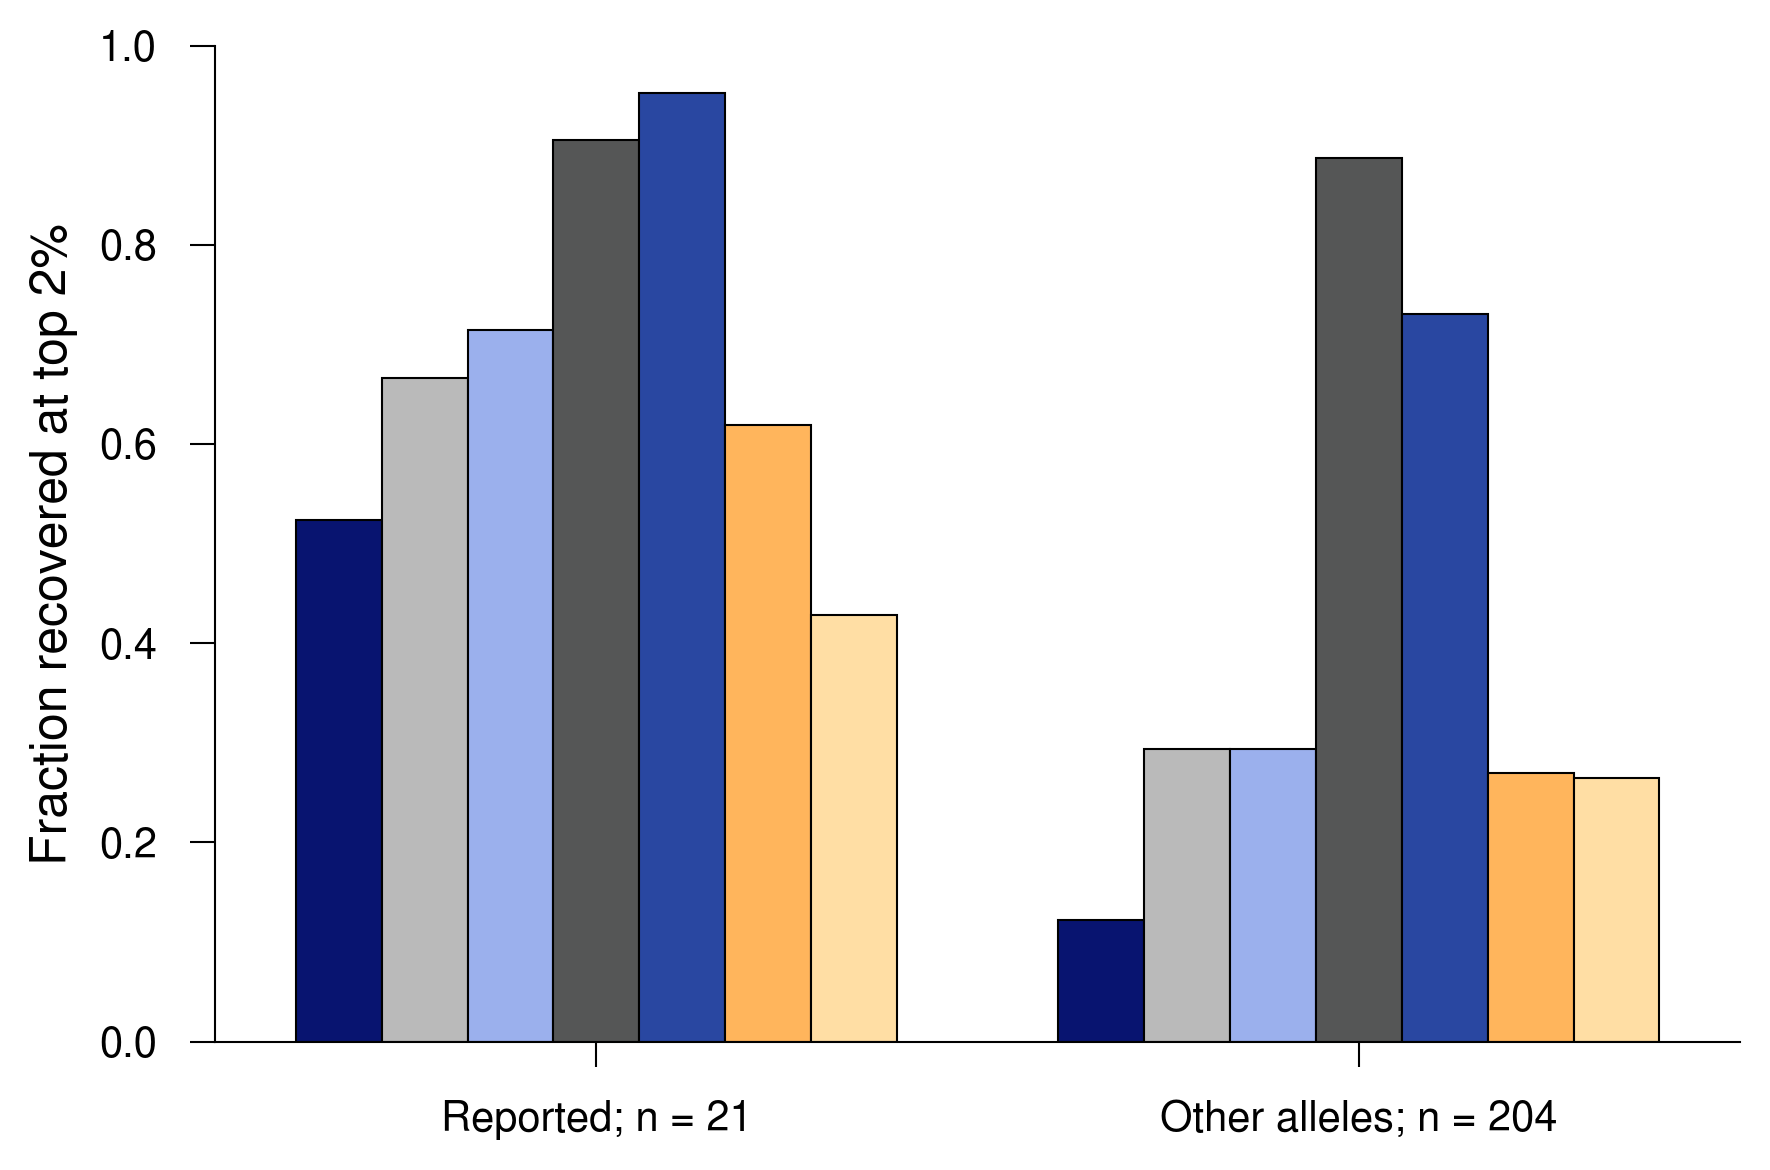

In [ ]:
# recovery barplot
model_groups = {m: [f"{m}_top", f"{m}_rem"] for m in score_cols + score_cols_external}
print(model_groups)
# x_ticks = ["(E-score > 3.8; n = 21)", "(E-score > 3.5; n = 204)"]
x_ticks = ["Reported; n = 21", "Other alleles; n = 204"]

colors = {
    'mhcprime': '#081470',
    'escape_seq_neoant_ft_cls': '#bababa',
    'escape_seq_neoant_pepcl_cls': '#9bb0ed',
    'escape_seq_neoant_ft_w_more_negs_cls': "#555656",
    'escape_seq_neoant_pepcl_w_more_negs_cls': "#2947a1",
    'EL_Rank': '#ffb55c',
    'BA_Rank': '#ffdea4'
}
plot_params = {
    'title': '',
    'title_fontsize': 16,
    'title_bold': False,
    'xlabel': '',
    'ylabel': 'Fraction recovered at top 2%',
    'xlabel_fontsize': 12,
    'ylabel_fontsize': 12,
    'figsize': (6, 4),
    'dpi': 300,
    'legend_fontsize': 12,
    'legend_cols': 5,
    'legend_handle_size': 0.9,
    'marker_size': 3,
    'axis_linewidth': 0.5,
    'tick_length': 6.0,
    'xlabel_pad': 5.0,
    'ylabel_pad': 5.0,
    'xtick_labelsize': 10,
    'ytick_labelsize': 10
}


_=plot_model_performance_bars_or_box_v2(
    df=escapeseq_neoantigens_recovery, # for the barplot
    model_col='model_name',
    score_col='recovered',
    model_groups=model_groups,
    x_ticks=x_ticks,
    colors=colors,
    plot_params=plot_params,
    ylim=(0.0, 1.0),
    grid_alpha=0.0,
    default_font='Nimbus Sans',
    bar_width=0.8,
    group_spacing=1.5,
    bar_spacing=0.0,
    bar_outline_color='black',
    bar_outline_width=0.5,
    hline_y=None,
    hline_label=None,
    hline_color='gray',
    hline_width=1.0,
    hline_style=':',
    hline_text=None,
    hline_text_position='above',
    hline_text_color=None,
    hline_text_fontsize=12,
    hline_text_offset=0.005,
    hline_text_x_offset=-0.035,
    hline_in_legend=True,
    legend_mode=None,
    mode='bar',
    box_flier_size=2,
    save_path=None,
    # save_path=f"{central_figure_dir}/suppfig8_a_top_and_remaining_neoantigen_recovery_grouped_barplot_cls_models"
)

{'mhcprime': ['mhcprime_top', 'mhcprime_rem'], 'escape_seq_neoant_ft_cls': ['escape_seq_neoant_ft_cls_top', 'escape_seq_neoant_ft_cls_rem'], 'escape_seq_neoant_pepcl_cls': ['escape_seq_neoant_pepcl_cls_top', 'escape_seq_neoant_pepcl_cls_rem'], 'escape_seq_neoant_ft_w_more_negs_cls': ['escape_seq_neoant_ft_w_more_negs_cls_top', 'escape_seq_neoant_ft_w_more_negs_cls_rem'], 'escape_seq_neoant_pepcl_w_more_negs_cls': ['escape_seq_neoant_pepcl_w_more_negs_cls_top', 'escape_seq_neoant_pepcl_w_more_negs_cls_rem'], 'EL_Rank': ['EL_Rank_top', 'EL_Rank_rem'], 'BA_Rank': ['BA_Rank_top', 'BA_Rank_rem']}


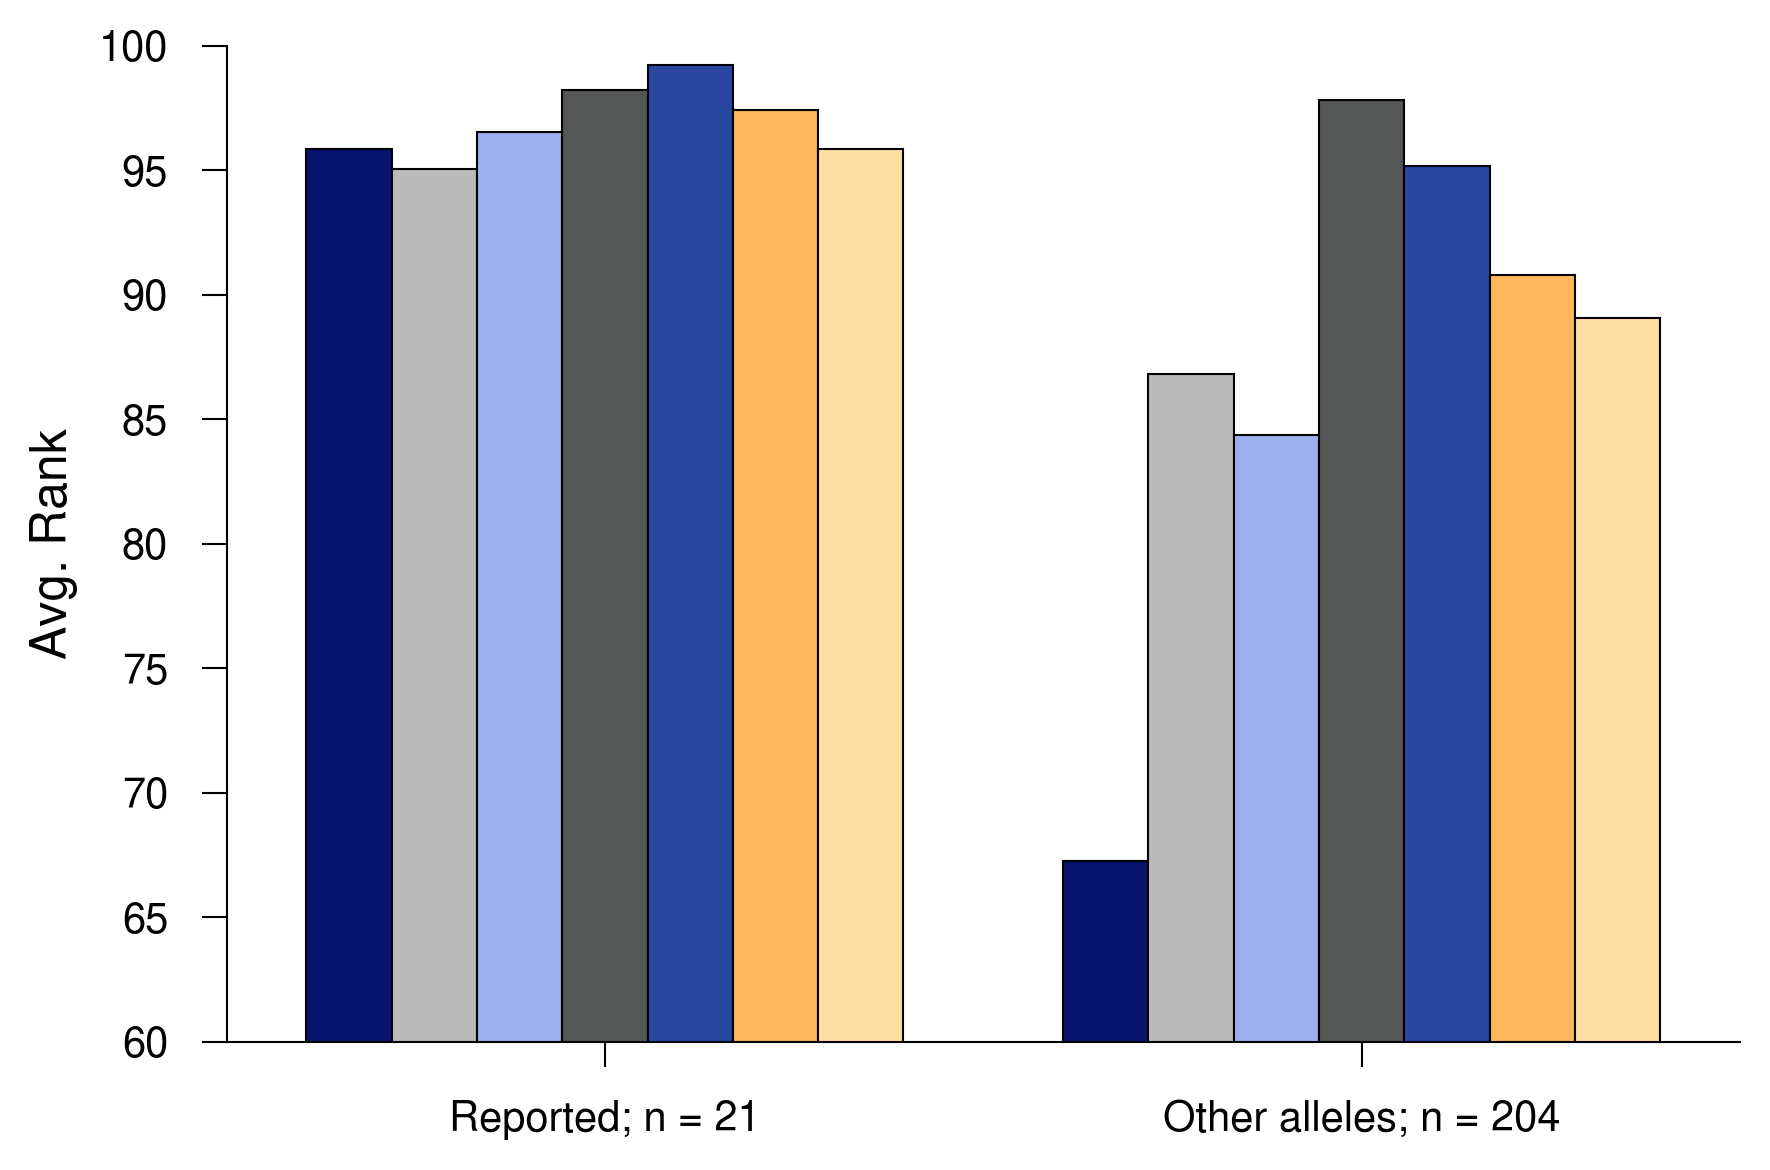

In [ ]:
# avg rank barplot
model_groups = {m: [f"{m}_top", f"{m}_rem"] for m in score_cols + score_cols_external}
print(model_groups)
# x_ticks = ["(E-score > 3.8; n = 21)", "(E-score > 3.5; n = 204)"]
x_ticks = ["Reported; n = 21", "Other alleles; n = 204"]

colors = {
    'mhcprime': '#081470',
    'escape_seq_neoant_ft_cls': '#bababa',
    'escape_seq_neoant_pepcl_cls': '#9bb0ed',
    'escape_seq_neoant_ft_w_more_negs_cls': "#555656",
    'escape_seq_neoant_pepcl_w_more_negs_cls': "#2947a1",
    'EL_Rank': '#ffb55c',
    'BA_Rank': '#ffdea4'
}
plot_params = {
    'title': '',
    'title_fontsize': 16,
    'title_bold': False,
    'xlabel': '',
    'ylabel': 'Avg. Rank',
    'xlabel_fontsize': 12,
    'ylabel_fontsize': 12,
    'figsize': (6, 4),
    'dpi': 300,
    'legend_fontsize': 12,
    'legend_cols': 5,
    'legend_handle_size': 0.9,
    'marker_size': 3,
    'axis_linewidth': 0.5,
    'tick_length': 6.0,
    'xlabel_pad': 5.0,
    'ylabel_pad': 5.0,
    'xtick_labelsize': 10,
    'ytick_labelsize': 10
}


_=plot_model_performance_bars_or_box_v2(
    df=escapeseq_neoantigens_avg_rank,
    model_col='model_name',
    score_col='mean_rank',
    model_groups=model_groups,
    x_ticks=x_ticks,
    colors=colors,
    plot_params=plot_params,
    ylim=(60.0, 100.0),
    grid_alpha=0.0,
    default_font='Nimbus Sans',
    bar_width=0.8,
    group_spacing=1.5,
    bar_spacing=0.0,
    bar_outline_color='black',
    bar_outline_width=0.5,
    hline_y=None,
    hline_label=None,
    hline_color='gray',
    hline_width=1.0,
    hline_style=':',
    hline_text=None,
    hline_text_position='above',
    hline_text_color=None,
    hline_text_fontsize=12,
    hline_text_offset=0.005,
    hline_text_x_offset=-0.035,
    hline_in_legend=True,
    legend_mode=None,
    mode='bar',
    box_flier_size=2,
    save_path=None,
    # save_path=f"{central_figure_dir}/suppfig8_a_top_and_remaining_neoantigen_avg_rank_grouped_barplot_cls_models"
)

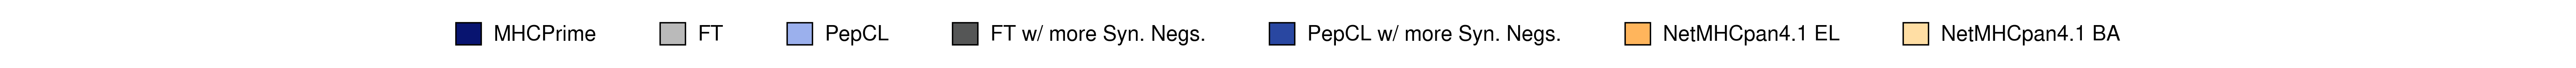

In [ ]:
# legend resized and formatted in illustrator
plot_horizontal_legend(
    legend_dict={
        'MHCPrime': '#081470',
        'FT': '#bababa',
        'PepCL': '#9bb0ed',
        'FT w/ more Syn. Negs.': "#555656",
        'PepCL w/ more Syn. Negs.': "#2947a1",
        'NetMHCpan4.1 EL': "#ffb55c",
        'NetMHCpan4.1 BA': "#ffdea4",
    },
    swatch_size=12,
    text_size=12,
    item_spacing=30,
    swatch_text_gap=6,
    swatch_outline_color='black',
    swatch_outline_width=0.8,
    figsize=None,
    dpi=300,
    default_font='Nimbus Sans',
    save_path=None,
    # save_path=f"{central_figure_dir}/suppfig8_a_legend",
)

In [ ]:
# ligand mhc atlas set
ligand_mhc_atlas_output_dir=f"{DATA_DIR}/Training_Datasets/Processed/MS_Train_Test_Sets/Ligand_MHC_Atlas"
ligand_mhc_atlas_cancer_test_set_for_escape_seq=pd.read_csv(f"{ligand_mhc_atlas_output_dir}/ligand_mhc_atlas_cancer_test_set_for_escape_seq.csv", index_col=0)

In [ ]:
# compute recovery and avg rank
score_cols=["mhcprime", "escape_seq_neoant_ft_cls", "escape_seq_neoant_pepcl_cls"]
score_cols+=["escape_seq_neoant_ft_w_more_negs_cls", "escape_seq_neoant_pepcl_w_more_negs_cls"]
rank_score_cols=[score_col+"_rank_r_chp" for score_col in score_cols]

ligand_mhc_atlas_recovery=compute_recovery(ligand_mhc_atlas_cancer_test_set_for_escape_seq, score_cols, [], threshold=98)
ligand_mhc_atlas_avg_rank=compute_mean_median_rank(ligand_mhc_atlas_cancer_test_set_for_escape_seq, score_cols, [])

In [ ]:
# get p-values
ligand_mhc_atlas_avg_rank_pval_df=compute_pairwise_pvalues_general(ligand_mhc_atlas_cancer_test_set_for_escape_seq[rank_score_cols])
ligand_mhc_atlas_avg_rank_pval_df.columns=score_cols
ligand_mhc_atlas_avg_rank_pval_df.index=score_cols
display(ligand_mhc_atlas_avg_rank_pval_df)
display(pval_to_stars(ligand_mhc_atlas_avg_rank_pval_df))

,mhcprime,escape_seq_neoant_ft_cls,escape_seq_neoant_pepcl_cls,escape_seq_neoant_ft_w_more_negs_cls,escape_seq_neoant_pepcl_w_more_negs_cls
mhcprime,1.000000e+00,0.000000e+00,2.372357e-16,0.000000e+00,1.466855e-67
escape_seq_neoant_ft_cls,0.000000e+00,1.000000e+00,0.000000e+00,3.398786e-44,0.000000e+00
escape_seq_neoant_pepcl_cls,2.372357e-16,0.000000e+00,1.000000e+00,0.000000e+00,3.113287e-30
escape_seq_neoant_ft_w_more_negs_cls,0.000000e+00,3.398786e-44,0.000000e+00,1.000000e+00,0.000000e+00
escape_seq_neoant_pepcl_w_more_negs_cls,1.466855e-67,0.000000e+00,3.113287e-30,0.000000e+00,1.000000e+00


,mhcprime,escape_seq_neoant_ft_cls,escape_seq_neoant_pepcl_cls,escape_seq_neoant_ft_w_more_negs_cls,escape_seq_neoant_pepcl_w_more_negs_cls
mhcprime,ns,****,****,****,****
escape_seq_neoant_ft_cls,****,ns,****,****,****
escape_seq_neoant_pepcl_cls,****,****,ns,****,****
escape_seq_neoant_ft_w_more_negs_cls,****,****,****,ns,****
escape_seq_neoant_pepcl_w_more_negs_cls,****,****,****,****,ns


{'mhcprime': ['mhcprime'], 'escape_seq_neoant_ft_cls': ['escape_seq_neoant_ft_cls'], 'escape_seq_neoant_pepcl_cls': ['escape_seq_neoant_pepcl_cls'], 'escape_seq_neoant_ft_w_more_negs_cls': ['escape_seq_neoant_ft_w_more_negs_cls'], 'escape_seq_neoant_pepcl_w_more_negs_cls': ['escape_seq_neoant_pepcl_w_more_negs_cls']}


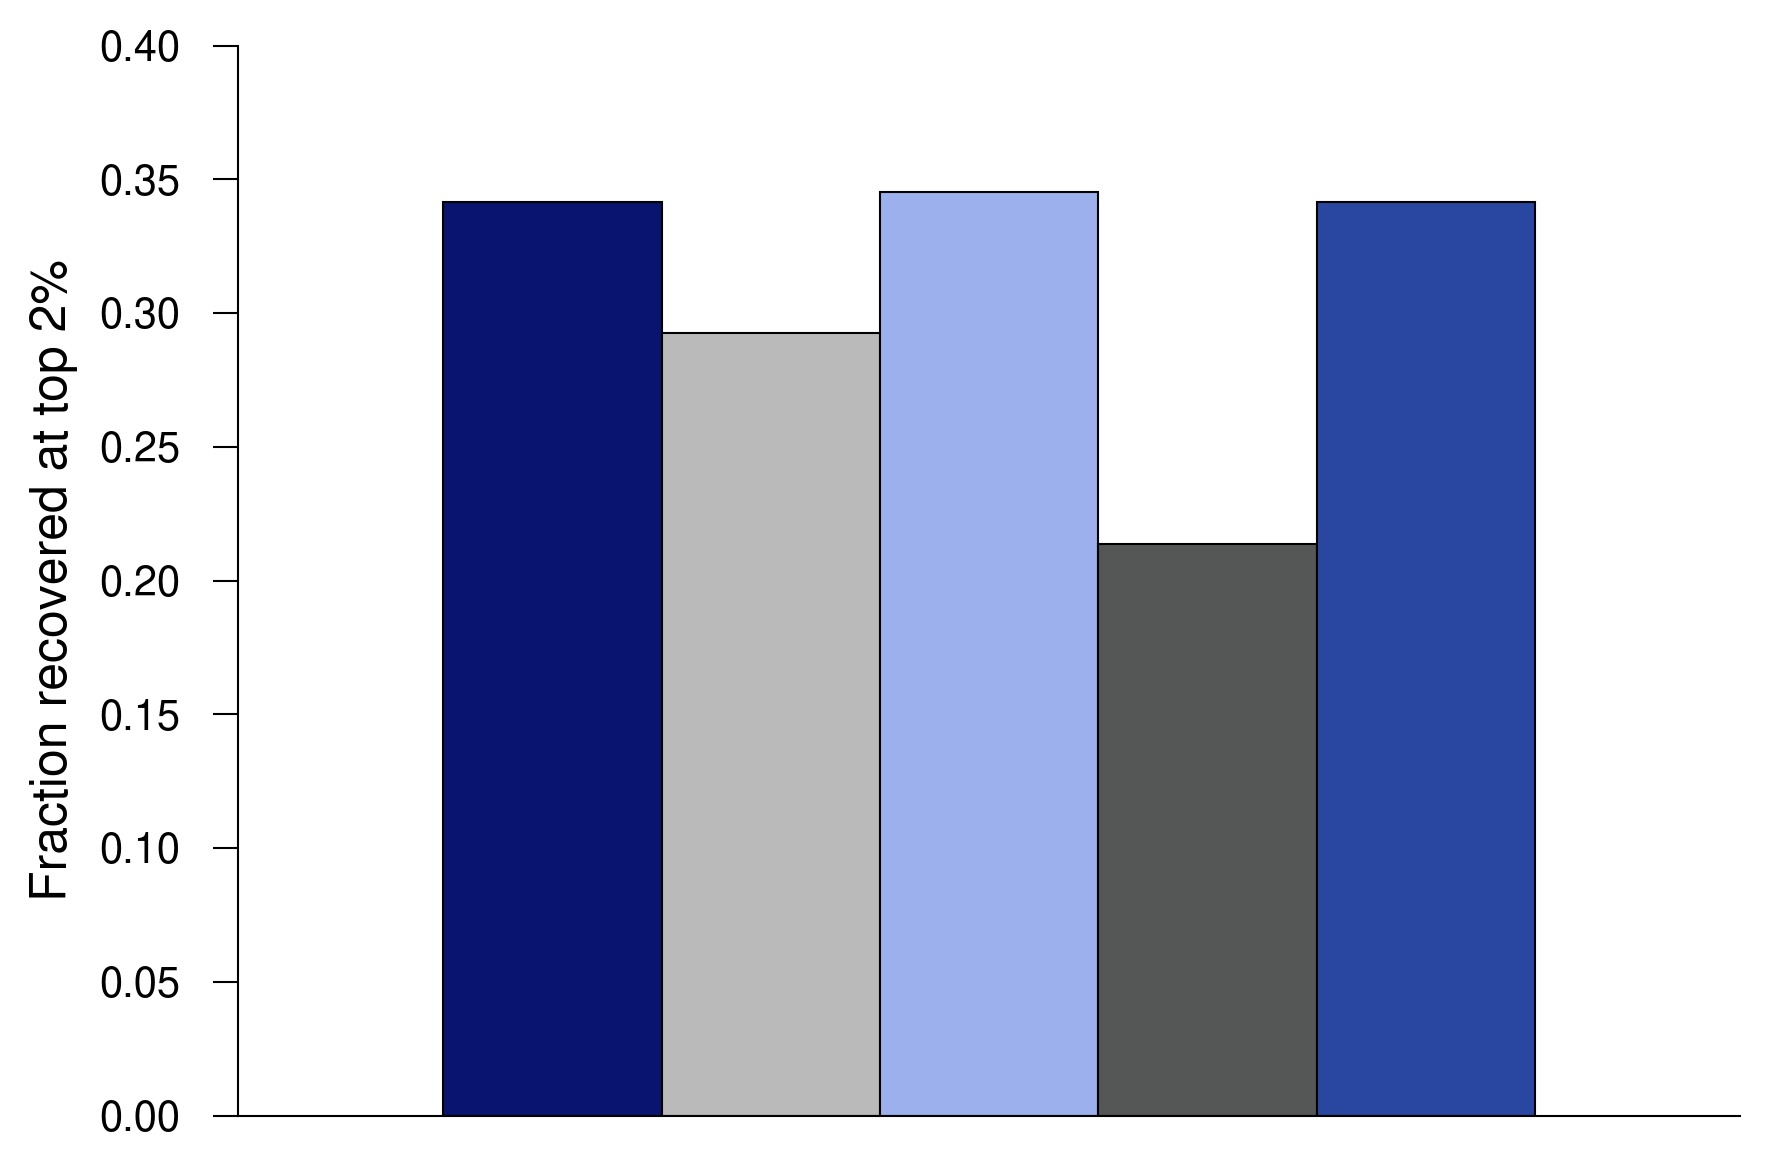

In [ ]:
# recovery barplot
model_groups = {m: [m] for m in score_cols}
print(model_groups)
x_ticks = [""]

colors = {
    'mhcprime': '#081470',
    'escape_seq_neoant_ft_cls': '#bababa',
    'escape_seq_neoant_pepcl_cls': '#9bb0ed',
    'escape_seq_neoant_ft_w_more_negs_cls': "#555656",
    'escape_seq_neoant_pepcl_w_more_negs_cls': "#2947a1",
}
plot_params = {
    'title': '',
    'title_fontsize': 16,
    'title_bold': False,
    'xlabel': '',
    'ylabel': 'Fraction recovered at top 2%',
    'xlabel_fontsize': 12,
    'ylabel_fontsize': 12,
    'figsize': (6, 4),
    'dpi': 300,
    'legend_fontsize': 12,
    'legend_cols': 5,
    'legend_handle_size': 0.9,
    'marker_size': 3,
    'axis_linewidth': 0.5,
    'tick_length': 6.0,
    'xlabel_pad': 5.0,
    'ylabel_pad': 5.0,
    'xtick_labelsize': 10,
    'ytick_labelsize': 10
}


_=plot_model_performance_bars_or_box_v2(
    df=ligand_mhc_atlas_recovery,
    model_col='model_name',
    score_col='recovered',
    model_groups=model_groups,
    x_ticks=x_ticks,
    colors=colors,
    plot_params=plot_params,
    ylim=(0.0, 0.4),
    grid_alpha=0.0,
    default_font='Nimbus Sans',
    bar_width=0.8,
    group_spacing=1.5,
    bar_spacing=0.0,
    bar_outline_color='black',
    bar_outline_width=0.5,
    hline_y=None,
    hline_label=None,
    hline_color='gray',
    hline_width=1.0,
    hline_style=':',
    hline_text=None,
    hline_text_position='above',
    hline_text_color=None,
    hline_text_fontsize=12,
    hline_text_offset=0.005,
    hline_text_x_offset=-0.035,
    hline_in_legend=True,
    legend_mode=None,
    mode='bar',
    box_flier_size=2,
    save_path=None,
    # save_path=f"{central_figure_dir}/suppfig8_b_ligand_mhc_atlas_recovery_cls_models"
)

{'mhcprime': ['mhcprime'], 'escape_seq_neoant_ft_cls': ['escape_seq_neoant_ft_cls'], 'escape_seq_neoant_pepcl_cls': ['escape_seq_neoant_pepcl_cls'], 'escape_seq_neoant_ft_w_more_negs_cls': ['escape_seq_neoant_ft_w_more_negs_cls'], 'escape_seq_neoant_pepcl_w_more_negs_cls': ['escape_seq_neoant_pepcl_w_more_negs_cls']}


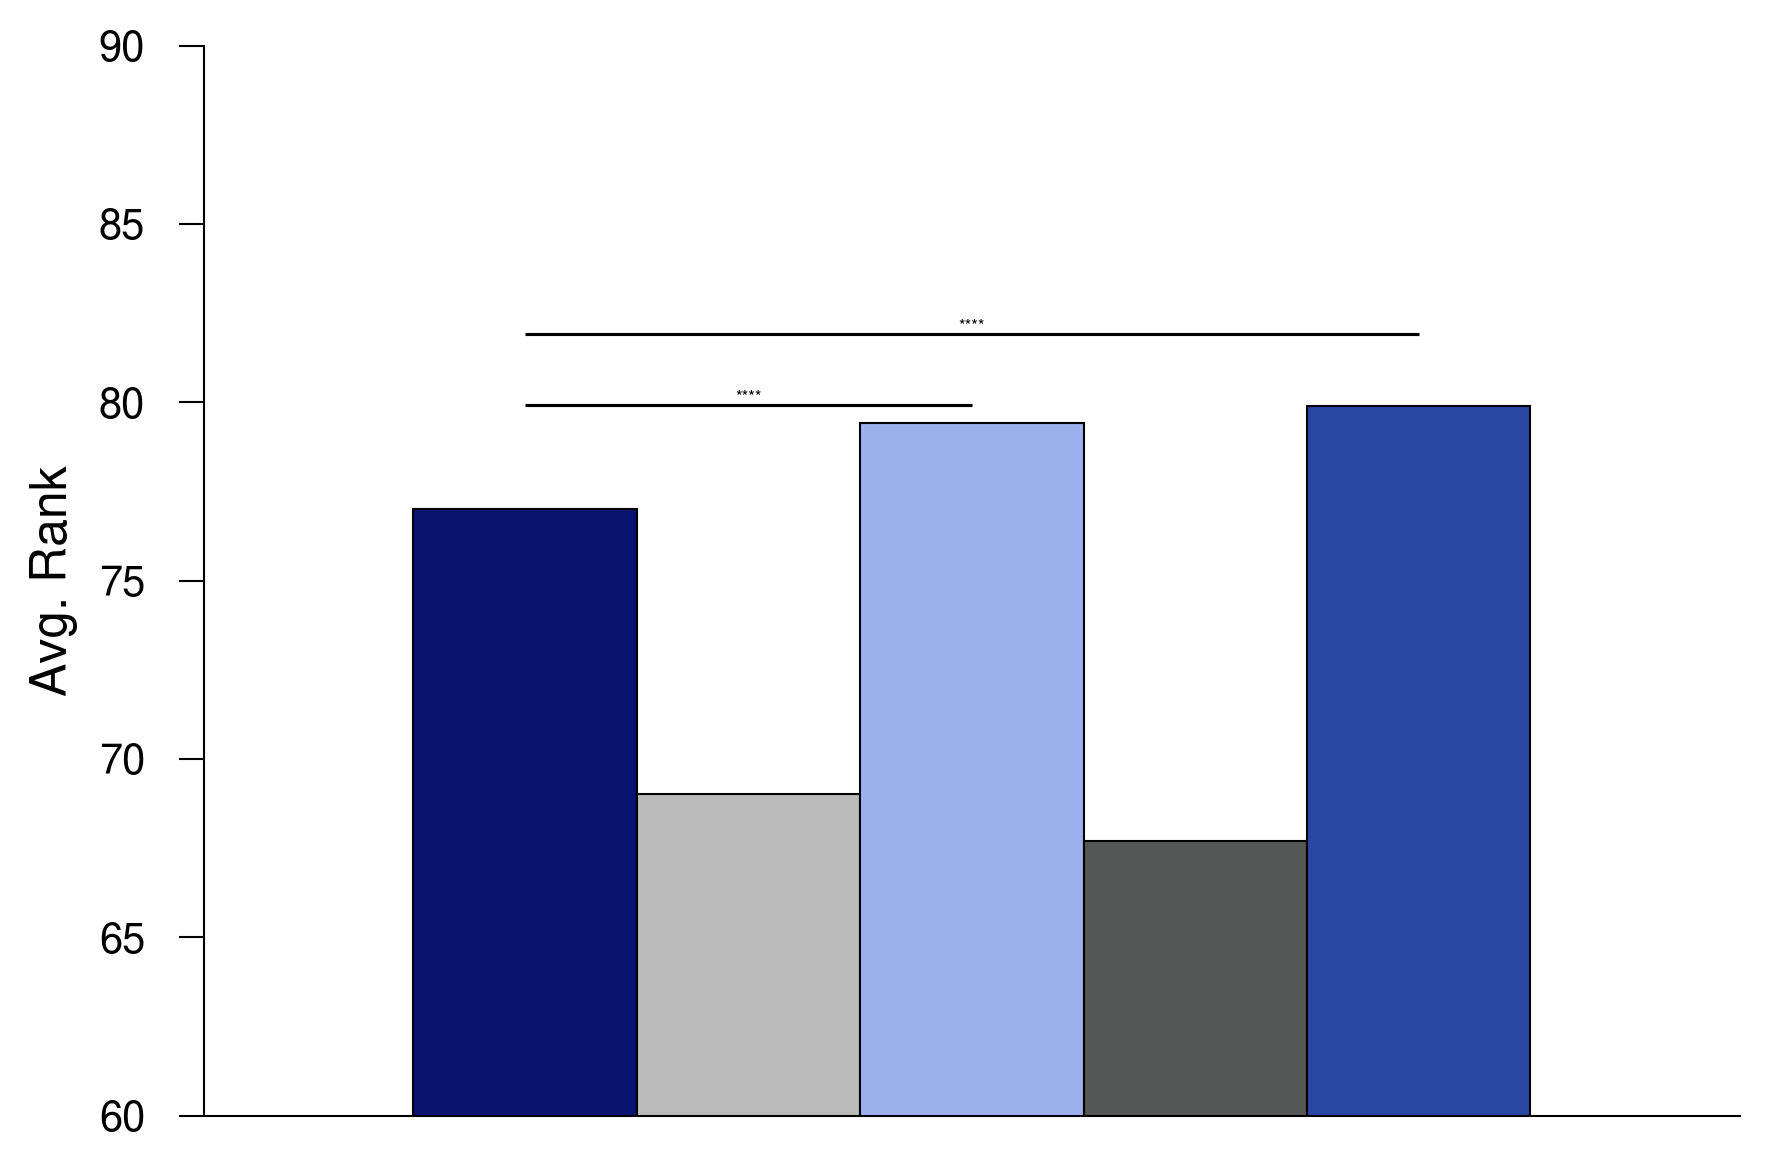

In [ ]:
# avg rank barplot
model_groups = {m: [m] for m in score_cols}
print(model_groups)
x_ticks = ['']

colors = {
    'mhcprime': '#081470',
    'escape_seq_neoant_ft_cls': '#bababa',
    'escape_seq_neoant_pepcl_cls': '#9bb0ed',
    'escape_seq_neoant_ft_w_more_negs_cls': "#555656",
    'escape_seq_neoant_pepcl_w_more_negs_cls': "#2947a1",
}

plot_params = {
    'title': '',
    'title_fontsize': 16,
    'title_bold': False,
    'xlabel': '',
    'ylabel': 'Avg. Rank',
    'xlabel_fontsize': 12,
    'ylabel_fontsize': 12,
    'figsize': (6, 4),
    'dpi': 300,
    'legend_fontsize': 12,
    'legend_cols': 5,
    'legend_handle_size': 0.9,
    'marker_size': 3,
    'axis_linewidth': 0.5,
    'tick_length': 6.0,
    'xlabel_pad': 5.0,
    'ylabel_pad': 5.0,
    'xtick_labelsize': 10,
    'ytick_labelsize': 10
}


_=plot_model_performance_bars_or_box_v2(
    df=ligand_mhc_atlas_avg_rank,
    model_col='model_name',
    score_col='mean_rank',
    model_groups=model_groups,
    x_ticks=x_ticks,
    colors=colors,
    plot_params=plot_params,
    ylim=(60.0, 90.0),
    grid_alpha=0.0,
    default_font='Nimbus Sans',
    bar_width=0.8,
    group_spacing=1.5,
    bar_spacing=0.0,
    bar_outline_color='black',
    bar_outline_width=0.5,
    hline_y=None,
    hline_label=None,
    hline_color='gray',
    hline_width=1.0,
    hline_style=':',
    hline_text=None,
    hline_text_position='above',
    hline_text_color=None,
    hline_text_fontsize=12,
    hline_text_offset=0.005,
    hline_text_x_offset=-0.035,
    hline_in_legend=True,
    legend_mode=None,
    mode='bar',
    box_flier_size=2,

    # p-value settings matching the 5-box compact style
    pval_df=ligand_mhc_atlas_avg_rank_pval_df,
    pval_base_only=False,
    pval_base_col="mhcprime",
    pval_pairs=[
                ("mhcprime", "escape_seq_neoant_pepcl_cls"),
                ("mhcprime", "escape_seq_neoant_pepcl_w_more_negs_cls"),
            ],
    pval_fontsize=4,
    pval_linewidth=0.75,
    pval_color='black',
    pval_bar_offset=0.035,
    pval_bar_spacing=2,
    pval_text_offset=0.004,
    pval_star_text_offset=-0.01,
    pval_ns_text_offset=0.004,
    pval_merge_nonoverlapping=False,

    save_path=None,
    # save_path=f"{central_figure_dir}/suppfig8_b_ligand_mhc_atlas_avg_rank_cls_models"
)

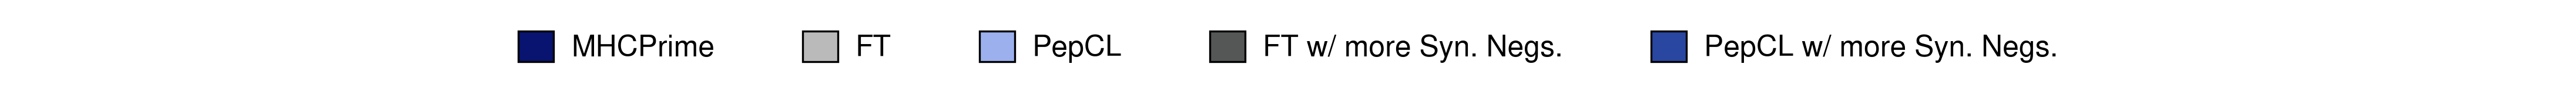

In [ ]:
# legend resized and formatted in illustrator
plot_horizontal_legend(
    legend_dict={
        'MHCPrime': '#081470',
        'FT': '#bababa',
        'PepCL': '#9bb0ed',
        'FT w/ more Syn. Negs.': "#555656",
        'PepCL w/ more Syn. Negs.': "#2947a1",
    },
    swatch_size=12,
    text_size=12,
    item_spacing=30,
    swatch_text_gap=6,
    swatch_outline_color='black',
    swatch_outline_width=0.8,
    figsize=None,
    dpi=300,
    default_font='Nimbus Sans',
    save_path=None,
    # save_path=f"{central_figure_dir}/suppfig8_b_legend",
)

In [ ]:
"""
Save dataframes associated with figures.
"""
save_dfs=False
# save_dfs=True

if save_dfs:
    escapeseq_neoantigens_recovery.to_csv(f"{associated_data_dir}/suppfig8_a_escapeseq_neoantigens_recovery.csv")
    escapeseq_neoantigens_avg_rank.to_csv(f"{associated_data_dir}/suppfig8_a_escapeseq_neoantigens_avg_rank.csv")

    ligand_mhc_atlas_recovery.to_csv(f"{associated_data_dir}/suppfig8_b_ligand_mhc_atlas_recovery.csv")
    ligand_mhc_atlas_avg_rank.to_csv(f"{associated_data_dir}/suppfig8_b_ligand_mhc_atlas_avg_rank.csv")
    ligand_mhc_atlas_avg_rank_pval_df.to_csv(f"{associated_data_dir}/suppfig8_b_ligand_mhc_atlas_avg_rank_pval_df.csv")

    

### Supplementary Figure 9: Additional BA updating statistics

In [ ]:
# ms/ba test sets
datasets_dir = DATA_DIR / "Training_Datasets" / "Processed" / "MS_Train_Test_Sets"
ms_test_data=pd.read_csv(f"{datasets_dir}/ms_test_data.csv", index_col=0)

ba_train_test_dir = DATA_DIR / "Training_Datasets" / "Processed" / "BA"
test_df_ba_for_updating=pd.read_csv(f"{ba_train_test_dir}/test_df_ba_for_updating.csv", index_col=0)

In [ ]:
# match allele length distribuction for ms data
# get seq len
test_df_ba_for_updating["seq_len"]=test_df_ba_for_updating.seq.str.replace("$", "").apply(len)
ms_test_data["seq_len"]=ms_test_data.seq.str.replace("$", "").apply(len)

ms_test_data_allele_length_matched=filter_to_shared_pairs(ms_test_data, test_df_ba_for_updating, allele_col='allele', seq_len_col='seq_len')

print_data_stats(ms_test_data_allele_length_matched)

Total: 1,361,400
Pos: 13,614 | 1.00%
Neg: 1,347,786 | 99.00%
N alleles: 51


In [ ]:
# ap per allele
# get ap matrix
score_cols=["mhcprime", "ba_ft_con", "ba_pepcl_con", "ba_ft_cls", "ba_pepcl_cls"]

# ms test set (matched allele-length distribution)
ms_allele_ap_df=compute_ap_matrix_optimized(ms_test_data_allele_length_matched, score_cols, label_col='label', allele_col='allele', disable_tqdm=True)

# ap for ba
ba_allele_ap_df=compute_ap_matrix_optimized(test_df_ba_for_updating, score_cols, label_col='label', allele_col='allele', disable_tqdm=True)

# ba test set (spearman correlation)
ba_allele_spearman_df=compute_spearman_matrix_optimized(test_df_ba_for_updating, score_cols, reference_col="ba_value", allele_col='allele', disable_tqdm=True)

ba_pos_allele_spearman_df=compute_spearman_matrix_optimized(test_df_ba_for_updating.query("label == 1"), score_cols, reference_col="ba_value", allele_col='allele', disable_tqdm=True)

In [ ]:
# pvals
ms_allele_ap_pval_df=compute_pairwise_pvalues_general(ms_allele_ap_df[score_cols])
display(ms_allele_ap_pval_df)
display(pval_to_stars(ms_allele_ap_pval_df))

ba_allele_ap_pval_df=compute_pairwise_pvalues_general(ba_allele_ap_df[score_cols])
display(ba_allele_ap_pval_df)
display(pval_to_stars(ba_allele_ap_pval_df))

ba_allele_spearman_pval_df=compute_pairwise_pvalues_general(ba_allele_spearman_df[score_cols])
display(ba_allele_spearman_pval_df)
display(pval_to_stars(ba_allele_spearman_pval_df))

ba_pos_allele_spearman_pval_df=compute_pairwise_pvalues_general(ba_pos_allele_spearman_df[score_cols])
display(ba_pos_allele_spearman_pval_df)
display(pval_to_stars(ba_pos_allele_spearman_pval_df))

,mhcprime,ba_ft_con,ba_pepcl_con,ba_ft_cls,ba_pepcl_cls
mhcprime,1.000000e+00,5.145276e-10,5.145276e-10,5.145276e-10,5.145276e-10
ba_ft_con,5.145276e-10,1.000000e+00,5.145276e-10,5.617593e-04,5.145276e-10
ba_pepcl_con,5.145276e-10,5.145276e-10,1.000000e+00,5.145276e-10,4.944083e-09
ba_ft_cls,5.145276e-10,5.617593e-04,5.145276e-10,1.000000e+00,5.145276e-10
ba_pepcl_cls,5.145276e-10,5.145276e-10,4.944083e-09,5.145276e-10,1.000000e+00


,mhcprime,ba_ft_con,ba_pepcl_con,ba_ft_cls,ba_pepcl_cls
mhcprime,ns,****,****,****,****
ba_ft_con,****,ns,****,***,****
ba_pepcl_con,****,****,ns,****,****
ba_ft_cls,****,***,****,ns,****
ba_pepcl_cls,****,****,****,****,ns


,mhcprime,ba_ft_con,ba_pepcl_con,ba_ft_cls,ba_pepcl_cls
mhcprime,1.000000e+00,1.985134e-09,8.774256e-10,8.774256e-10,6.151931e-10
ba_ft_con,1.985134e-09,1.000000e+00,1.979812e-03,5.485716e-01,4.127090e-03
ba_pepcl_con,8.774256e-10,1.979812e-03,1.000000e+00,1.089649e-01,5.931426e-01
ba_ft_cls,8.774256e-10,5.485716e-01,1.089649e-01,1.000000e+00,2.964560e-03
ba_pepcl_cls,6.151931e-10,4.127090e-03,5.931426e-01,2.964560e-03,1.000000e+00


,mhcprime,ba_ft_con,ba_pepcl_con,ba_ft_cls,ba_pepcl_cls
mhcprime,ns,****,****,****,****
ba_ft_con,****,ns,**,ns,**
ba_pepcl_con,****,**,ns,ns,ns
ba_ft_cls,****,ns,ns,ns,**
ba_pepcl_cls,****,**,ns,**,ns


,mhcprime,ba_ft_con,ba_pepcl_con,ba_ft_cls,ba_pepcl_cls
mhcprime,1.000000e+00,5.461521e-10,5.145276e-10,6.151931e-10,5.145276e-10
ba_ft_con,5.461521e-10,1.000000e+00,2.218847e-02,2.464132e-05,2.530809e-07
ba_pepcl_con,5.145276e-10,2.218847e-02,1.000000e+00,1.200188e-02,7.101615e-07
ba_ft_cls,6.151931e-10,2.464132e-05,1.200188e-02,1.000000e+00,2.565291e-04
ba_pepcl_cls,5.145276e-10,2.530809e-07,7.101615e-07,2.565291e-04,1.000000e+00


,mhcprime,ba_ft_con,ba_pepcl_con,ba_ft_cls,ba_pepcl_cls
mhcprime,ns,****,****,****,****
ba_ft_con,****,ns,*,****,****
ba_pepcl_con,****,*,ns,*,****
ba_ft_cls,****,****,*,ns,***
ba_pepcl_cls,****,****,****,***,ns


,mhcprime,ba_ft_con,ba_pepcl_con,ba_ft_cls,ba_pepcl_cls
mhcprime,1.000000e+00,5.723301e-08,5.532901e-09,2.530809e-07,5.430358e-08
ba_ft_con,5.723301e-08,1.000000e+00,1.089649e-01,1.641266e-02,8.760360e-04
ba_pepcl_con,5.532901e-09,1.089649e-01,1.000000e+00,5.866747e-01,8.917594e-03
ba_ft_cls,2.530809e-07,1.641266e-02,5.866747e-01,1.000000e+00,1.028939e-01
ba_pepcl_cls,5.430358e-08,8.760360e-04,8.917594e-03,1.028939e-01,1.000000e+00


,mhcprime,ba_ft_con,ba_pepcl_con,ba_ft_cls,ba_pepcl_cls
mhcprime,ns,****,****,****,****
ba_ft_con,****,ns,ns,*,***
ba_pepcl_con,****,ns,ns,ns,**
ba_ft_cls,****,*,ns,ns,ns
ba_pepcl_cls,****,***,**,ns,ns


{'MHCPrime': ['mhcprime'], 'FT CON': ['ba_ft_con'], 'FT CLS': ['ba_ft_cls'], 'PepCL CON': ['ba_pepcl_con'], 'PepCL CLS': ['ba_pepcl_cls']}


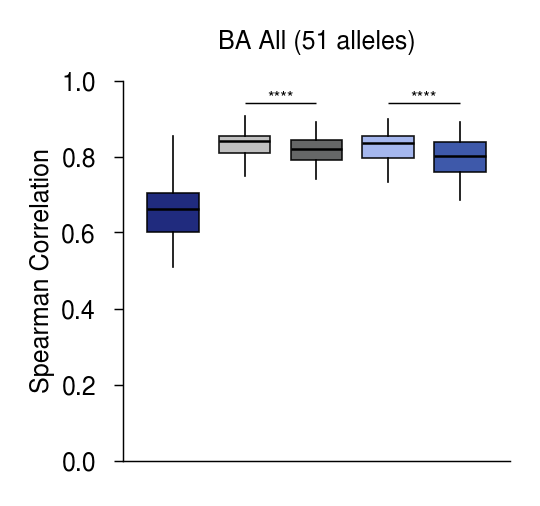

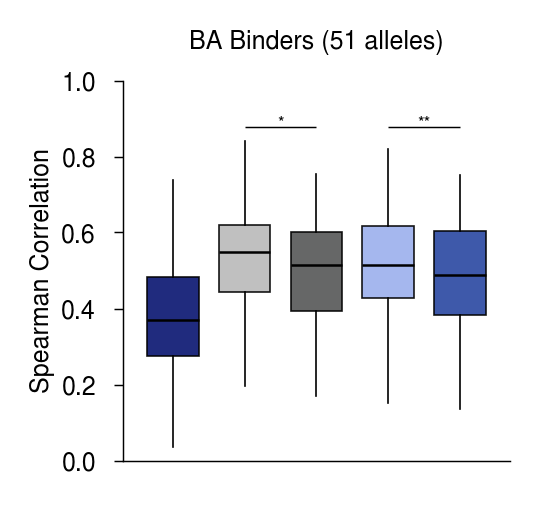

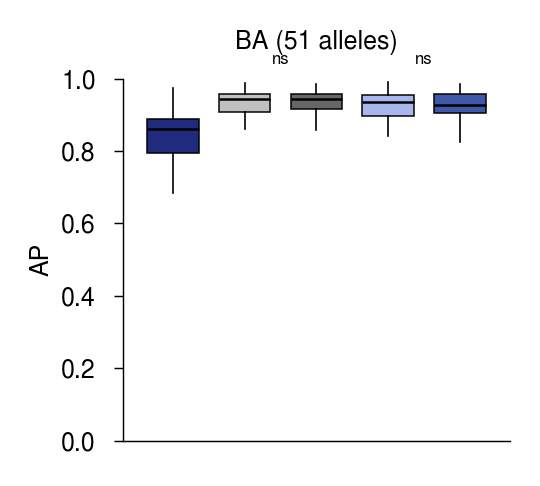

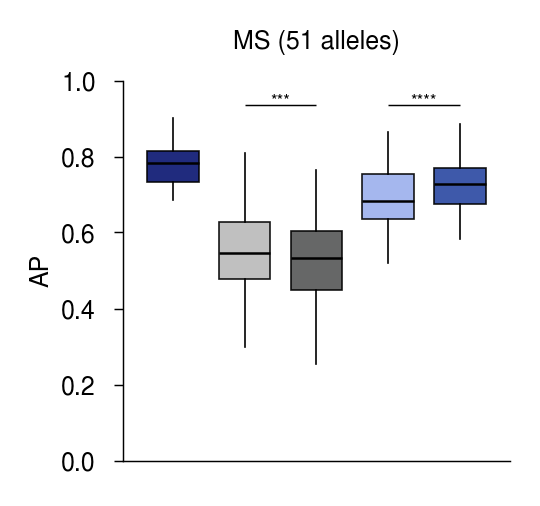

In [ ]:
# plot all together
score_cols = [
    "mhcprime",
    "ba_ft_con",
    "ba_ft_cls",
    "ba_pepcl_con",
    "ba_pepcl_cls",
]

model_groups = {
    'MHCPrime': ["mhcprime"],
    'FT CON': ["ba_ft_con"],
    'FT CLS': ["ba_ft_cls"],
    'PepCL CON': ["ba_pepcl_con"],
    'PepCL CLS': ["ba_pepcl_cls"],
}

x_ticks = ['']
print(model_groups)

colors = {
    'MHCPrime': '#081470',
    'FT CON': '#bababa',
    'FT CLS': '#555656',
    'PepCL CON': '#9bb0ed',
    'PepCL CLS': '#2947a1',
}

plot_params = {
    'title': '',
    'title_y': 1.1,
    'title_bbox': None,
    'title_fontsize': 6,
    'title_bold': False,
    'xlabel': '',
    'ylabel': 'Spearman Correlation',
    'xlabel_fontsize': 6,
    'ylabel_fontsize': 6,

    # 5-box compact equivalent
    'figsize': (1.90, 1.65),

    'dpi': 300,
    'legend_fontsize': 6,
    'legend_cols': 5,
    'legend_handle_size': 0.7,
    'axis_linewidth': 0.35,
    'tick_length': 2.2,
    'xlabel_pad': 1,
    'ylabel_pad': 1.5,
    'xtick_labelsize': 5.5,
    'ytick_labelsize': 6,
}

plotting_parameters = dict(
    model_col='model_name',
    score_col='metric',
    model_groups=model_groups,
    x_ticks=x_ticks,
    colors=colors,
    plot_params=plot_params,
    ylim=(0.0, 1.0),
    grid_alpha=0,
    default_font='Nimbus Sans',
    mode='box',

    # compact 5-box geometry
    bar_width=0.32,
    bar_spacing=0.08,
    group_spacing=0.10,
    x_margin=0.12,

    bar_outline_color='black',
    box_median_width=0.60,
    bar_outline_width=0.40,
    box_whisker_width=0.40,
    box_flier_size=0,

    legend_mode=None,
    xtick_rotation=0,

    # p-value settings matching the 5-box compact style
    pval_df=None,
    pval_base_only=True,
    pval_base_col="mhcprime",
    pval_fontsize=4,
    pval_linewidth=0.35,
    pval_color='black',
    pval_bar_offset=0.035,
    pval_bar_spacing=0.06,
    pval_text_offset=0.004,
    pval_star_text_offset=-0.01,
    pval_ns_text_offset=0.004,
)

plot_params["ylabel"] = "Spearman Correlation"
plot_params["title"] = f"BA All ({ba_allele_spearman_df.index.nunique()} alleles)"
plotting_parameters["plot_params"] = plot_params
plotting_parameters.update(
    dict(
        pval_df=ba_allele_spearman_pval_df,
        pval_pairs=[
            ("ba_ft_con", "ba_ft_cls"),
            ("ba_pepcl_con", "ba_pepcl_cls"),
        ],
        pval_base_only=False,
    )
)
_ = plot_model_performance_bars_or_box_v2(
    df=ba_allele_spearman_df,
    save_path=None,
    # save_path=f"{central_figure_dir}/suppfig9_a_ba_updating_per_allele_spearman_correlation_boxplots",
    **plotting_parameters,
)

plot_params["ylabel"] = "Spearman Correlation"
plot_params["title"] = f"BA Binders ({ba_pos_allele_spearman_df.index.nunique()} alleles)"
plotting_parameters["plot_params"] = plot_params
plotting_parameters.update(
    dict(
        pval_df=ba_pos_allele_spearman_pval_df,
        pval_pairs=[
            ("ba_ft_con", "ba_ft_cls"),
            ("ba_pepcl_con", "ba_pepcl_cls"),
        ],
        pval_base_only=False,
    )
)
_ = plot_model_performance_bars_or_box_v2(
    df=ba_pos_allele_spearman_df,
    save_path=None,
    # save_path=f"{central_figure_dir}/suppfig9_b_ba_updating_pos_only_per_allele_spearman_correlation_boxplots",
    **plotting_parameters,
)


plot_params["ylabel"] = "AP"
plot_params["title"] = f"BA ({ba_allele_ap_df.index.nunique()} alleles)"
plotting_parameters["plot_params"]=plot_params
plotting_parameters.update(
    dict(
        pval_df=ba_allele_ap_pval_df,
        pval_pairs=[
            ("ba_ft_con", "ba_ft_cls"),
            ("ba_pepcl_con", "ba_pepcl_cls"),
        ],
        pval_base_only=False,
    )
)
_=plot_model_performance_bars_or_box_v2(
    df=ba_allele_ap_df,
    save_path=None,
    # save_path=f"{central_figure_dir}/suppfig9_c_ba_updating_only_per_allele_ap_boxplots",
    **plotting_parameters
)

plot_params["ylabel"] = "AP"
plot_params["title"] = f"MS ({ms_allele_ap_df.index.nunique()} alleles)"
plotting_parameters["plot_params"]=plot_params
plotting_parameters.update(
    dict(
        pval_df=ms_allele_ap_pval_df,
        pval_pairs=[
            ("ba_ft_con", "ba_ft_cls"),
            ("ba_pepcl_con", "ba_pepcl_cls"),
        ],
        pval_base_only=False,
    )
)
_=plot_model_performance_bars_or_box_v2(
    df=ms_allele_ap_df,
    save_path=None,
    # save_path=f"{central_figure_dir}/suppfig9_d_ms_for_ba_updating_only_per_allele_ap_boxplots",
    **plotting_parameters
)



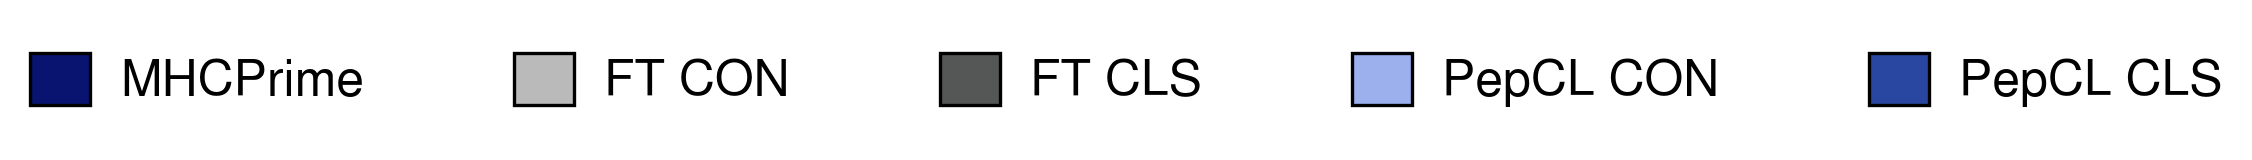

In [ ]:
# legend resized and formatted in illustrator
plot_horizontal_legend(
    legend_dict={
        'MHCPrime': '#081470',
        'FT CON': '#bababa',
        'FT CLS': '#555656',
        'PepCL CON': '#9bb0ed',
        'PepCL CLS': '#2947a1',
    },
    swatch_size=12,
    text_size=12,
    item_spacing=30,
    swatch_text_gap=6,
    swatch_outline_color='black',
    swatch_outline_width=0.8,
    figsize=None,
    dpi=300,
    default_font='Nimbus Sans',
    save_path=None,
    # save_path=f"{central_figure_dir}/suppfig9_legend",
)

In [ ]:
"""
Save dataframes associated with figures.
"""
save_dfs=False
# save_dfs=True

if save_dfs:
    ba_allele_spearman_df.to_csv(f"{associated_data_dir}/suppfig9_a_ba_allele_spearman_df.csv")
    ba_allele_spearman_pval_df.to_csv(f"{associated_data_dir}/suppfig9_a_ba_allele_spearman_pval_df.csv")

    ba_pos_allele_spearman_df.to_csv(f"{associated_data_dir}/suppfig9_b_ba_pos_allele_spearman_df.csv")
    ba_pos_allele_spearman_pval_df.to_csv(f"{associated_data_dir}/suppfig9_b_ba_pos_allele_spearman_pval_df.csv")

    ba_allele_ap_df.to_csv(f"{associated_data_dir}/suppfig9_c_ba_allele_ap_df.csv")
    ba_allele_ap_pval_df.to_csv(f"{associated_data_dir}/suppfig9_c_ba_allele_ap_pval_df.csv")

    ms_allele_ap_df.to_csv(f"{associated_data_dir}/suppfig9_d_ms_allele_ap_df.csv")
    ms_allele_ap_pval_df.to_csv(f"{associated_data_dir}/suppfig9_d_ms_allele_ap_pval_df.csv")

### Supplementary Figure 10: ESCAPE-seq differential mutation calling per gene

In [ ]:
# get data

# get nmp41 escape seq predictions
escape_seq_datasets_dir = DATA_DIR / "Training_Datasets" / "Processed" / "ESCAPE_seq"
escape_seq_all_data_nmp41=pd.read_csv(f"{escape_seq_datasets_dir}/escape_seq_all_data_nmp41.csv")
escape_seq_all_data_nmp41=create_seq_allele_column(escape_seq_all_data_nmp41)

# process
escape_seq_all_data_nmp41_processed=full_process_data(escape_seq_all_data_nmp41, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
escape_seq_all_data_nmp41_processed=create_seq_allele_column(escape_seq_all_data_nmp41_processed)
escape_seq_all_data_nmp41_processed["method_group"]='nonMS'
print_data_stats(escape_seq_all_data_nmp41_processed)

Total: 87,267
Pos: 9,464 | 10.84%
Neg: 77,803 | 89.16%
N alleles: 50


In [ ]:
%%time
# process gene holdout results
central_ft_dir=f"{DATA_DIR}/ESCAPE_seq_gene_holdout_experiment"
output_df_dir="inference_dfs"

genes_to_run=['JAK2', 'MAX', 'MPL', 'MED12', 'TP53', 'SRSF2', 'NOTCH2', 'EZH2', 'AKT1', 'IDH1', 'ATM', 'MYD88', 'EGFR', 'FGFR3', 'PTEN', 'SF3B1', 'CREBBP', 'MYC', 'FBXW7', 'BRAF', 'RET', 'SMAD4', 'ERBB2', 'GNAS', 'DNMT3A', 'ALK', 'KIAA1549', 'EWSR1']

# add genes from gene groups
gene_groups={
    "KRAS": ["KRAS", "KRAS-NRAS", "KRAS-KRAS-NRAS-NRAS-HRAS-HRAS", "KRAS-HRAS", "KRAS-NRAS-HRAS", "HRAS", "NRAS-HRAS"], 
    "FLT3": ["FLT3", "KIT", "PDGFRA", "FLT3-KIT-PDGFRA", "FLT3-PDGFRA"],
    "IDH2": ["IDH2", "IDH2-IDH2"],
    "PIK3CA": ["PIK3CA", "PIK3CA-PIK3CA"],
    "CTNNB1": ["CTNNB1", "CTNNB1-CTNNB1"],
}

genes_to_run+=list(gene_groups.keys())

allele_ap_matrix_wt_neg_mut_pos=pd.DataFrame()
allele_ap_matrix_wt_pos_mut_neg=pd.DataFrame()

full_spearmans=pd.DataFrame()
wt_spearmans=pd.DataFrame()
mut_spearmans=pd.DataFrame()
wt_mut_gene_diff_noX_spearmans=pd.DataFrame()

for gene in tqdm(genes_to_run):

    mut_wt_df_gene=pd.read_csv(f"{central_ft_dir}/{output_df_dir}/mut_wt_df_gene_{gene}.csv")

    mut_wt_df_gene["name_allele"]=[f"{n}_{a}" for n, a in zip(mut_wt_df_gene.name2, mut_wt_df_gene.allele)]

    mut_wt_df_gene=create_seq_allele_column(mut_wt_df_gene)

    # map el and ba scores
    external_models=["EL_score", "BA_score"]
    for em in external_models:
        seq_allele_to_score=dict(zip(escape_seq_all_data_nmp41_processed.seq_allele, escape_seq_all_data_nmp41_processed[em]))
        mut_wt_df_gene[em]=mut_wt_df_gene.seq_allele.map(seq_allele_to_score)

    score_cols=["model_base", "model_ft", "model_pepcl"]
    
    # add external models
    score_cols+=["EL_score", "BA_score"]

    wt_mut_gene_diff_noX=pair_wt_mut_and_diff_with_quadrants_v2(
        df=filter_sequences_without_x(mut_wt_df_gene),
        score_cols=score_cols + ["escore"],
        # id_col="name2",
        id_col="name_allele",
        mut_type_col = "mut_type",
        wt_value = "wt",
        mut_value = "mut",
        allele_col = "allele",
        mutation_col = "mutation",
        seq_col = "seq",
        label_col = "label",
        quadrant_col = "wt_mut_quadrant",
        seed = 42,
        dup_mode = "pair_enumeration",

    )

    wt_mut_gene_diff_noX=add_quadrant_binary_label(
        df=wt_mut_gene_diff_noX,
        quadrant_col="wt_mut_quadrant",
        quadrant_name="WT-/MUT+",
        out_label_col = "quadrant_label",
    )
    wt_mut_gene_diff_noX_negated=wt_mut_gene_diff_noX.copy()

    wt_mut_gene_diff_noX_negated=add_quadrant_binary_label(
        df=wt_mut_gene_diff_noX_negated,
        quadrant_col="wt_mut_quadrant",
        quadrant_name="WT+/MUT-",
        out_label_col = "quadrant_label",
    )

    for score_col in score_cols + ["escore"]:
        wt_mut_gene_diff_noX_negated[score_col]=-wt_mut_gene_diff_noX_negated[score_col]

    wt_mut_gene_diff_noX=compute_hamming(wt_mut_gene_diff_noX, "seq_wt", "seq_mut", "hamming_dist")
    wt_mut_gene_diff_noX=wt_mut_gene_diff_noX.query("hamming_dist >= 1")

    wt_mut_gene_diff_noX["all"]=1
    allele_ap_matrix=compute_ap_matrix_optimized(wt_mut_gene_diff_noX.query("allele != 'A6801'"), score_cols + ["escore"], label_col='quadrant_label', allele_col='all', disable_tqdm=True) # use reverse_rank_score_cols instead of rank_score_cols

    allele_ap_matrix.index=[gene]
    allele_ap_matrix_wt_neg_mut_pos=pd.concat([allele_ap_matrix_wt_neg_mut_pos, allele_ap_matrix])

    wt_mut_gene_diff_noX_negated=compute_hamming(wt_mut_gene_diff_noX_negated, "seq_wt", "seq_mut", "hamming_dist")
    wt_mut_gene_diff_noX_negated=wt_mut_gene_diff_noX_negated.query("hamming_dist >= 1")

    wt_mut_gene_diff_noX_negated["all"]=1
    allele_ap_matrix=compute_ap_matrix_optimized(wt_mut_gene_diff_noX_negated.query("allele != 'A6801'"), score_cols + ["escore"], label_col='quadrant_label', allele_col='all', disable_tqdm=True) # use reverse_rank_score_cols instead of rank_score_cols

    allele_ap_matrix.index=[gene]
    allele_ap_matrix_wt_pos_mut_neg=pd.concat([allele_ap_matrix_wt_pos_mut_neg, allele_ap_matrix])

    base_col="escore"
    full_spearman_df=spearman_vs_base(filter_sequences_without_x(mut_wt_df_gene).query("allele != 'A6801'"), score_cols, base_col, index_name=gene)
    wt_spearman_df=spearman_vs_base(filter_sequences_without_x(mut_wt_df_gene).query("allele != 'A6801'").query("mut_type == 'wt'"), score_cols, base_col, index_name=gene)
    mut_spearman_df=spearman_vs_base(filter_sequences_without_x(mut_wt_df_gene).query("allele != 'A6801'").query("mut_type == 'mut'"), score_cols, base_col, index_name=gene)
    wt_mut_gene_diff_noX_spearman_df=spearman_vs_base(wt_mut_gene_diff_noX.query("allele != 'A6801'"), score_cols, base_col, index_name=gene)

    full_spearmans=pd.concat([full_spearmans, full_spearman_df])
    wt_spearmans=pd.concat([wt_spearmans, wt_spearman_df])
    mut_spearmans=pd.concat([mut_spearmans, mut_spearman_df])
    wt_mut_gene_diff_noX_spearmans=pd.concat([wt_mut_gene_diff_noX_spearmans, wt_mut_gene_diff_noX_spearman_df])


100%|██████████| 33/33 [00:06<00:00,  4.81it/s]

CPU times: user 6.84 s, sys: 72.4 ms, total: 6.91 s
Wall time: 6.87 s


In [ ]:
# process for individual gene performance

# wt-/mut+
df_to_use=allele_ap_matrix_wt_neg_mut_pos.drop(["escore"], axis=1).sort_values(by="model_pepcl", ascending=False).copy()
allele_ap_matrix_wt_neg_mut_pos_flat=flatten_gene_model_df(df_to_use, name_col='model_name', value_col='metric')
allele_ap_matrix_wt_neg_mut_pos_model_groups, wt_neg_mut_pos_genes_xticks=get_model_gene_dict(df_to_use)

# wt+/mut-
df_to_use=allele_ap_matrix_wt_pos_mut_neg.drop(["escore"], axis=1).sort_values(by="model_pepcl", ascending=False).copy()
allele_ap_matrix_wt_pos_mut_neg_flat=flatten_gene_model_df(df_to_use, name_col='model_name', value_col='metric')
allele_ap_matrix_wt_pos_mut_neg_model_groups, wt_pos_mut_neg_genes_xticks=get_model_gene_dict(df_to_use)

{'model_base': ['model_base_EWSR1', 'model_base_AKT1', 'model_base_SRSF2', 'model_base_FLT3', 'model_base_SF3B1', 'model_base_MYC', 'model_base_MYD88', 'model_base_IDH1', 'model_base_MAX', 'model_base_NOTCH2', 'model_base_IDH2', 'model_base_CREBBP', 'model_base_JAK2', 'model_base_KIAA1549', 'model_base_EGFR', 'model_base_MED12', 'model_base_PIK3CA', 'model_base_ERBB2', 'model_base_PTEN', 'model_base_SMAD4', 'model_base_TP53', 'model_base_CTNNB1', 'model_base_MPL', 'model_base_DNMT3A', 'model_base_EZH2', 'model_base_KRAS', 'model_base_FBXW7', 'model_base_ALK', 'model_base_GNAS', 'model_base_ATM', 'model_base_BRAF', 'model_base_FGFR3', 'model_base_RET'], 'model_ft': ['model_ft_EWSR1', 'model_ft_AKT1', 'model_ft_SRSF2', 'model_ft_FLT3', 'model_ft_SF3B1', 'model_ft_MYC', 'model_ft_MYD88', 'model_ft_IDH1', 'model_ft_MAX', 'model_ft_NOTCH2', 'model_ft_IDH2', 'model_ft_CREBBP', 'model_ft_JAK2', 'model_ft_KIAA1549', 'model_ft_EGFR', 'model_ft_MED12', 'model_ft_PIK3CA', 'model_ft_ERBB2', 'model

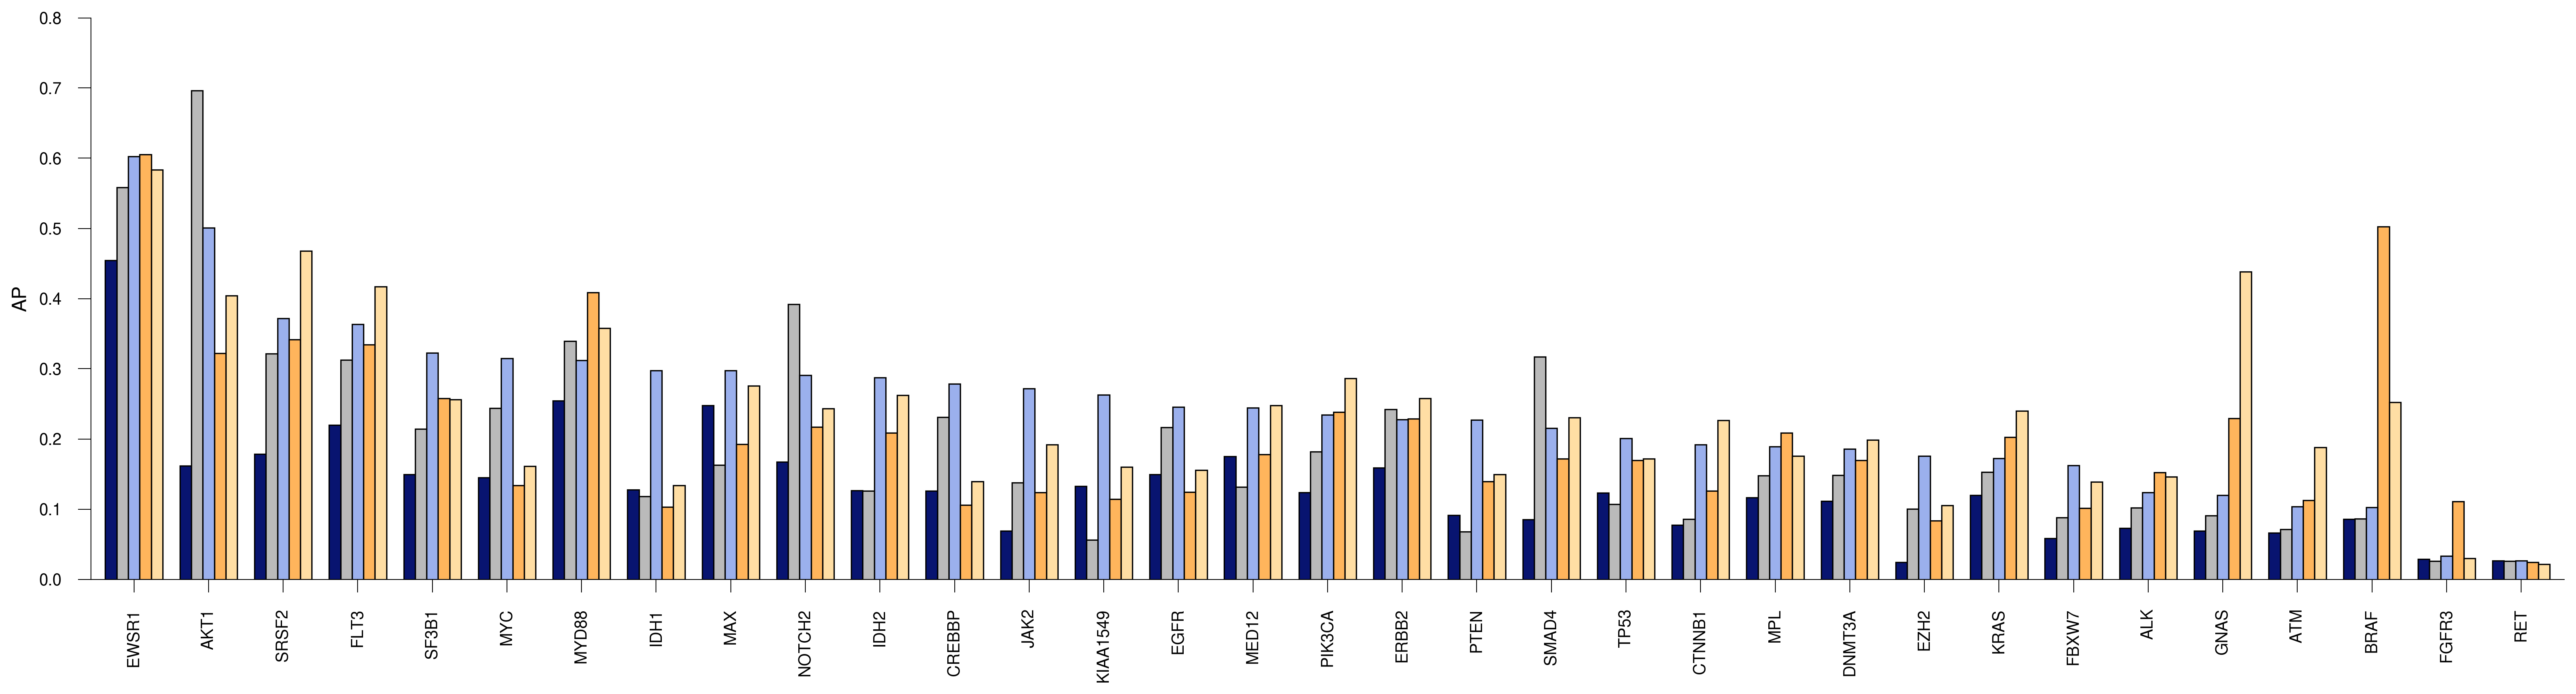

{'model_base': ['model_base_EWSR1', 'model_base_PTEN', 'model_base_IDH1', 'model_base_DNMT3A', 'model_base_AKT1', 'model_base_MAX', 'model_base_IDH2', 'model_base_ATM', 'model_base_CREBBP', 'model_base_NOTCH2', 'model_base_GNAS', 'model_base_JAK2', 'model_base_EGFR', 'model_base_FBXW7', 'model_base_PIK3CA', 'model_base_MYD88', 'model_base_KIAA1549', 'model_base_ALK', 'model_base_TP53', 'model_base_MPL', 'model_base_SF3B1', 'model_base_ERBB2', 'model_base_BRAF', 'model_base_RET', 'model_base_EZH2', 'model_base_MED12', 'model_base_FLT3', 'model_base_MYC', 'model_base_SMAD4', 'model_base_SRSF2', 'model_base_KRAS', 'model_base_CTNNB1', 'model_base_FGFR3'], 'model_ft': ['model_ft_EWSR1', 'model_ft_PTEN', 'model_ft_IDH1', 'model_ft_DNMT3A', 'model_ft_AKT1', 'model_ft_MAX', 'model_ft_IDH2', 'model_ft_ATM', 'model_ft_CREBBP', 'model_ft_NOTCH2', 'model_ft_GNAS', 'model_ft_JAK2', 'model_ft_EGFR', 'model_ft_FBXW7', 'model_ft_PIK3CA', 'model_ft_MYD88', 'model_ft_KIAA1549', 'model_ft_ALK', 'model_f

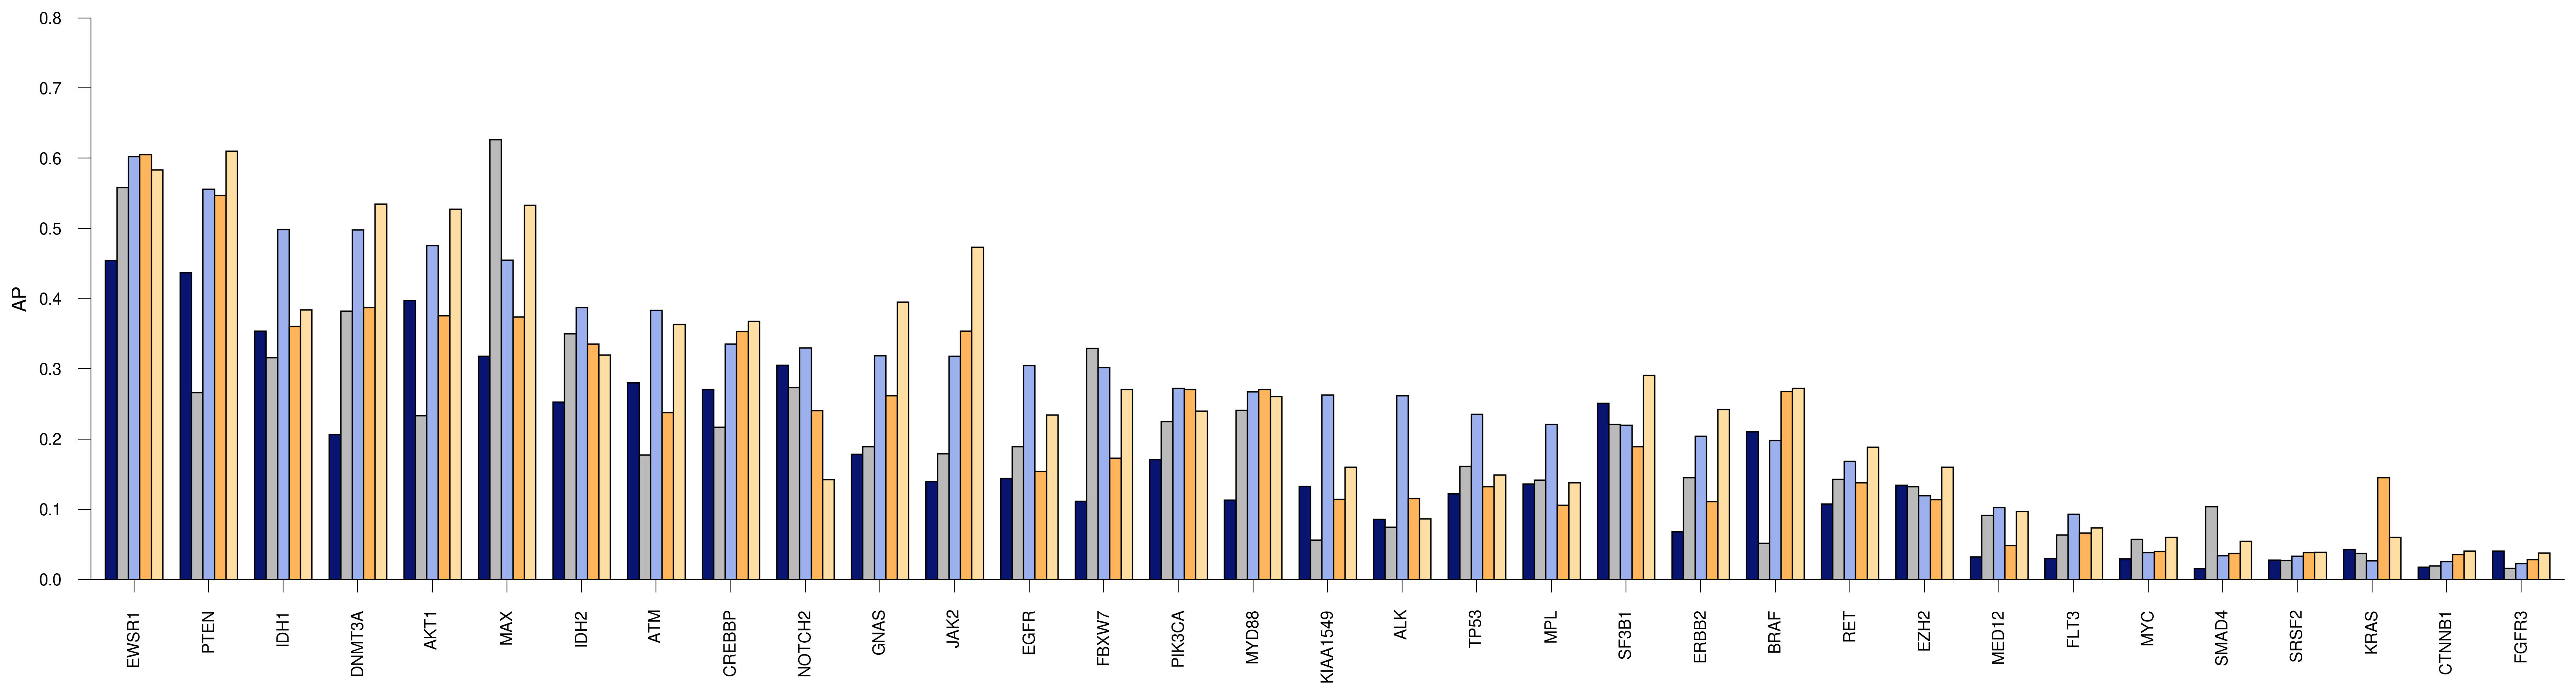

In [ ]:
# plot per gene performance
model_groups = allele_ap_matrix_wt_neg_mut_pos_model_groups

print(model_groups)

# X-axis values (epochs)
x_ticks = wt_neg_mut_pos_genes_xticks

colors = {
    'model_base': '#081470',
    'model_ft': '#bababa',
    'model_pepcl': '#9bb0ed',
    'EL_score': "#ffb55c",
    'BA_score': "#ffdea4",
}


# Plot parameters
plot_params = {
    'title': '',
    'title_fontsize': 16,
    'title_bold': False,
    'xlabel': '',
    'ylabel': 'AP',
    'xlabel_fontsize': 12,
    'ylabel_fontsize': 12,
    'figsize': (22, 6),
    'dpi': 300,
    'legend_fontsize': 12,
    'legend_cols': 5,
    'legend_handle_size': 0.9,
    'marker_size': 3,
    'axis_linewidth': 0.5,
    'tick_length': 8.0,
    'xlabel_pad': 5.0,
    'ylabel_pad': 5.0,
    'xtick_labelsize': 10,
    'ytick_labelsize': 10
}

# gain mutations
_=plot_model_performance_bars_or_box_v2(
    df=allele_ap_matrix_wt_neg_mut_pos_flat, 
    model_col='model_name',
    score_col='metric',
    model_groups=model_groups,
    x_ticks=x_ticks,
    colors=colors,
    plot_params=plot_params,
    ylim=(0.0, 0.8),
    grid_alpha=0,
    default_font='Nimbus Sans',
    bar_width=2.0,
    group_spacing=3,
    bar_spacing=0.0,
    bar_outline_color='black',
    bar_outline_width=0.8,
    hline_y=None,
    hline_label=None,
    hline_color='gray',
    hline_width=1.0,
    hline_style=':',
    hline_text=None,
    hline_text_position='above',
    hline_text_color=None,
    hline_text_fontsize=12,
    hline_text_offset=0.005,
    hline_text_x_offset=-0.035,
    hline_in_legend=True,
    # legend_mode='integrated',
    legend_mode=None,
    mode='bar',
    box_flier_size=2,
    xtick_rotation=90,
    x_margin=2.5,
    save_path=None,
    # save_path=f"{central_figure_dir}/suppfig10_a_per_gene_metric_results_wt_neg_mut_pos_grouped_barplot_continuous_ft_models"
)

# escape mutations
model_groups = allele_ap_matrix_wt_pos_mut_neg_model_groups
print(model_groups)
x_ticks = wt_pos_mut_neg_genes_xticks

_=plot_model_performance_bars_or_box_v2(
    df=allele_ap_matrix_wt_pos_mut_neg_flat,
    model_col='model_name',
    score_col='metric',
    model_groups=model_groups,
    x_ticks=x_ticks,
    colors=colors,
    plot_params=plot_params,
    ylim=(0.0, 0.8),
    grid_alpha=0,
    default_font='Nimbus Sans',
    bar_width=2.0,
    group_spacing=3,
    bar_spacing=0.0,
    bar_outline_color='black',
    bar_outline_width=0.8,
    hline_y=None,
    hline_label=None,
    hline_color='gray',
    hline_width=1.0,
    hline_style=':',
    hline_text=None,
    hline_text_position='above',
    hline_text_color=None,
    hline_text_fontsize=12,
    hline_text_offset=0.005,
    hline_text_x_offset=-0.035,
    hline_in_legend=True,
    # legend_mode='integrated',
    legend_mode=None,
    mode='bar',
    box_flier_size=2,
    xtick_rotation=90,
    x_margin=2.5,
    save_path=None,
    # save_path=f"{central_figure_dir}/suppfig10_b_per_gene_metric_results_wt_pos_mut_neg_grouped_barplot_continuous_ft_models"
)

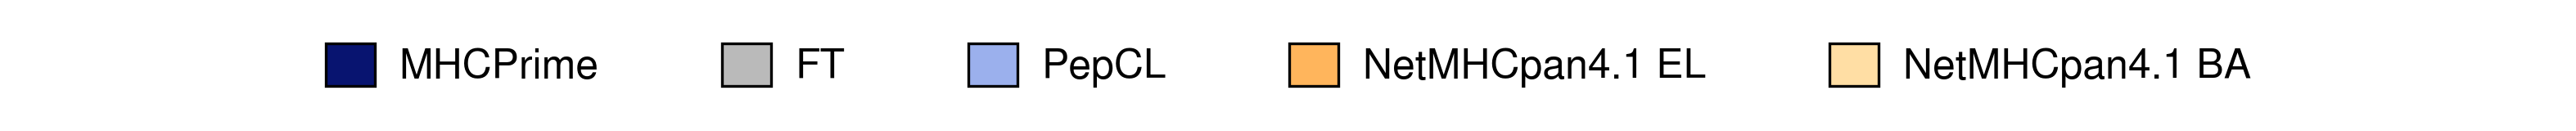

In [ ]:
# legend resized and formatted in illustrator
plot_horizontal_legend(
    legend_dict={
        'MHCPrime': '#081470',
        'FT': '#bababa',
        'PepCL': '#9bb0ed',
        'NetMHCpan4.1 EL': "#ffb55c",
        'NetMHCpan4.1 BA': "#ffdea4",
    },
    swatch_size=12,
    text_size=12,
    item_spacing=30,
    swatch_text_gap=6,
    swatch_outline_color='black',
    swatch_outline_width=0.8,
    figsize=None,
    dpi=300,
    default_font='Nimbus Sans',
    save_path=None,
    # save_path=f"{central_figure_dir}/suppfig10_legend",
)

In [ ]:
"""
Save dataframes associated with figures.
"""
save_dfs=False
# save_dfs=True

if save_dfs:
    allele_ap_matrix_wt_neg_mut_pos_flat.to_csv(f"{associated_data_dir}/suppfig10_a_allele_ap_matrix_wt_neg_mut_pos_flat.csv")
    allele_ap_matrix_wt_pos_mut_neg_flat.to_csv(f"{associated_data_dir}/suppfig10_b_allele_ap_matrix_wt_pos_mut_neg_flat.csv")